# Data Exploration

In [1]:
# pip install "notebook>=7.0" "anywidget>=0.9.13"
# %pip install missingno

In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
np.set_printoptions(linewidth=75)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

### Read all CSV files at once

In [3]:
PBJ_Daily_Nurse_Staffing_Q2_2024 = pd.read_csv('PBJ_Daily_Nurse_Staffing_Q2_2024.csv', encoding='cp1252')
FY_2024_SNF_VBP_Aggregate_Performance = pd.read_csv('FY_2024_SNF_VBP_Aggregate_Performance.csv', encoding='cp1252')
FY_2024_SNF_VBP_Facility_Performance = pd.read_csv('FY_2024_SNF_VBP_Facility_Performance.csv', encoding='cp1252')
NH_CitationDescriptions_Oct2024 = pd.read_csv('NH_CitationDescriptions_Oct2024.csv', encoding='cp1252')
NH_CovidVaxAverages_20241027 = pd.read_csv('NH_CovidVaxAverages_20241027.csv', encoding='cp1252')
NH_CovidVaxProvider_20241027 = pd.read_csv('NH_CovidVaxProvider_20241027.csv', encoding='cp1252')
NH_DataCollectionIntervals_Oct2024 = pd.read_csv('NH_DataCollectionIntervals_Oct2024.csv', encoding='cp1252')
NH_FireSafetyCitations_Oct2024 = pd.read_csv('NH_FireSafetyCitations_Oct2024.csv', encoding='cp1252')
NH_HealthCitations_Oct2024 = pd.read_csv('NH_HealthCitations_Oct2024.csv', encoding='cp1252')
NH_HlthInspecCutpointsState_Oct2024 = pd.read_csv('NH_HlthInspecCutpointsState_Oct2024.csv', encoding='cp1252')
NH_Ownership_Oct2024 = pd.read_csv('NH_Ownership_Oct2024.csv', encoding='cp1252')
NH_Penalties_Oct2024 = pd.read_csv('NH_Penalties_Oct2024.csv', encoding='cp1252')
NH_ProviderInfo_Oct2024 = pd.read_csv('NH_ProviderInfo_Oct2024.csv', encoding='cp1252')
NH_QualityMsr_Claims_Oct2024 = pd.read_csv('NH_QualityMsr_Claims_Oct2024.csv', encoding='cp1252')
NH_QualityMsr_MDS_Oct2024 = pd.read_csv('NH_QualityMsr_MDS_Oct2024.csv', encoding='cp1252')
NH_StateUSAverages_Oct2024 = pd.read_csv('NH_StateUSAverages_Oct2024.csv', encoding='cp1252')
NH_SurveyDates_Oct2024 = pd.read_csv('NH_SurveyDates_Oct2024.csv', encoding='cp1252')
NH_SurveySummary_Oct2024 = pd.read_csv('NH_SurveySummary_Oct2024.csv', encoding='cp1252')
Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024 = pd.read_csv('Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024.csv', encoding='cp1252')
Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024 = pd.read_csv('Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024.csv', encoding='cp1252')
Swing_Bed_SNF_data_Oct2024 = pd.read_csv('Swing_Bed_SNF_data_Oct2024.csv', encoding='cp1252')

C:\Users\student\AppData\Local\Temp\ipykernel_23896\3145720333.py:1: DtypeWarning: Columns (0: PROVNUM) have mixed types. Specify dtype option on import or set low_memory=False.
  PBJ_Daily_Nurse_Staffing_Q2_2024 = pd.read_csv('PBJ_Daily_Nurse_Staffing_Q2_2024.csv', encoding='cp1252')
C:\Users\student\AppData\Local\Temp\ipykernel_23896\3145720333.py:8: DtypeWarning: Columns (0: CMS Certification Number (CCN)) have mixed types. Specify dtype option on import or set low_memory=False.
  NH_FireSafetyCitations_Oct2024 = pd.read_csv('NH_FireSafetyCitations_Oct2024.csv', encoding='cp1252')
C:\Users\student\AppData\Local\Temp\ipykernel_23896\3145720333.py:9: DtypeWarning: Columns (0: CMS Certification Number (CCN)) have mixed types. Specify dtype option on import or set low_memory=False.
  NH_HealthCitations_Oct2024 = pd.read_csv('NH_HealthCitations_Oct2024.csv', encoding='cp1252')
C:\Users\student\AppData\Local\Temp\ipykernel_23896\3145720333.py:15: DtypeWarning: Columns (0: CMS Certificatio

### PBJ Daily Nursing Staffing
- Provides daily nursing staffing hour statistics for on-duty registered nurses (RNs), RNs, RN administrators, Licensed Practical Nurses (LPN), LPN administrators, Certified Nursing Assistants (CNAs), Nursing Assistants in training, and Medication Aides.
    - Statistics are kept separate between employees hired directly by the provider (emp) versus contracted employees (ctr). They are summed together and listed separately (no distinction between emp vs ctr).

In [4]:
PBJ_Daily_Nurse_Staffing_Q2_2024.head()

,PROVNUM,PROVNAME,CITY,STATE,COUNTY_NAME,COUNTY_FIPS,CY_Qtr,WorkDate,MDScensus,Hrs_RNDON,Hrs_RNDON_emp,Hrs_RNDON_ctr,Hrs_RNadmin,Hrs_RNadmin_emp,Hrs_RNadmin_ctr,Hrs_RN,Hrs_RN_emp,Hrs_RN_ctr,Hrs_LPNadmin,Hrs_LPNadmin_emp,Hrs_LPNadmin_ctr,Hrs_LPN,Hrs_LPN_emp,Hrs_LPN_ctr,Hrs_CNA,Hrs_CNA_emp,Hrs_CNA_ctr,Hrs_NAtrn,Hrs_NAtrn_emp,Hrs_NAtrn_ctr,Hrs_MedAide,Hrs_MedAide_emp,Hrs_MedAide_ctr
0,15009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240401,51,10.77,10.77,0.0,10.40,10.40,0.0,55.70,55.70,0.0,0.0,0.0,0.0,25.50,25.50,0.0,160.08,160.08,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,15009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240402,52,8.43,8.43,0.0,18.25,18.25,0.0,63.28,63.28,0.0,0.0,0.0,0.0,15.22,15.22,0.0,135.95,135.95,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,15009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240403,53,11.13,11.13,0.0,12.08,12.08,0.0,76.29,76.29,0.0,0.0,0.0,0.0,5.46,5.46,0.0,150.31,150.31,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,15009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240404,52,12.27,12.27,0.0,17.53,17.53,0.0,54.13,54.13,0.0,0.0,0.0,0.0,20.18,20.18,0.0,133.01,133.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,15009,"BURNS NURSING HOME, INC.",RUSSELLVILLE,AL,Franklin,59,2024Q2,20240405,52,4.95,4.95,0.0,17.42,17.42,0.0,53.63,53.63,0.0,0.0,0.0,0.0,27.85,27.85,0.0,137.92,137.92,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
PBJ_Daily_Nurse_Staffing_Q2_2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 1325324 entries, 0 to 1325323
Data columns (total 33 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   PROVNUM           1325324 non-null  object 
 1   PROVNAME          1325324 non-null  str    
 2   CITY              1325324 non-null  str    
 3   STATE             1325324 non-null  str    
 4   COUNTY_NAME       1325324 non-null  str    
 5   COUNTY_FIPS       1325324 non-null  int64  
 6   CY_Qtr            1325324 non-null  str    
 7   WorkDate          1325324 non-null  int64  
 8   MDScensus         1325324 non-null  int64  
 9   Hrs_RNDON         1325324 non-null  float64
 10  Hrs_RNDON_emp     1325324 non-null  float64
 11  Hrs_RNDON_ctr     1325324 non-null  float64
 12  Hrs_RNadmin       1325324 non-null  float64
 13  Hrs_RNadmin_emp   1325324 non-null  float64
 14  Hrs_RNadmin_ctr   1325324 non-null  float64
 15  Hrs_RN            1325324 non-null  float64
 16  Hrs_RN_emp 

In [6]:
# Check if theory about emp vs ctr employees being summed into 'total' columns is accurate.
PBJ_filtered = PBJ_Daily_Nurse_Staffing_Q2_2024[PBJ_Daily_Nurse_Staffing_Q2_2024["Hrs_RNDON_ctr"]>0].head()
print(PBJ_filtered)

     PROVNUM        PROVNAME        CITY STATE COUNTY_NAME  COUNTY_FIPS  \
5560   15133  MAGNOLIA RIDGE  GARDENDALE    AL   Jefferson           73   
5561   15133  MAGNOLIA RIDGE  GARDENDALE    AL   Jefferson           73   
5562   15133  MAGNOLIA RIDGE  GARDENDALE    AL   Jefferson           73   
5565   15133  MAGNOLIA RIDGE  GARDENDALE    AL   Jefferson           73   
5566   15133  MAGNOLIA RIDGE  GARDENDALE    AL   Jefferson           73   

      CY_Qtr  WorkDate  MDScensus  Hrs_RNDON  Hrs_RNDON_emp  Hrs_RNDON_ctr  \
5560  2024Q2  20240410        137      22.80           16.0           6.80   
5561  2024Q2  20240411        136      25.41           16.0           9.41   
5562  2024Q2  20240412        138      24.98           16.0           8.98   
5565  2024Q2  20240415        137      17.01            8.0           9.01   
5566  2024Q2  20240416        138      17.36            8.0           9.36   

      Hrs_RNadmin  Hrs_RNadmin_emp  Hrs_RNadmin_ctr  Hrs_RN  Hrs_RN_emp  \
5560 

<Axes: >

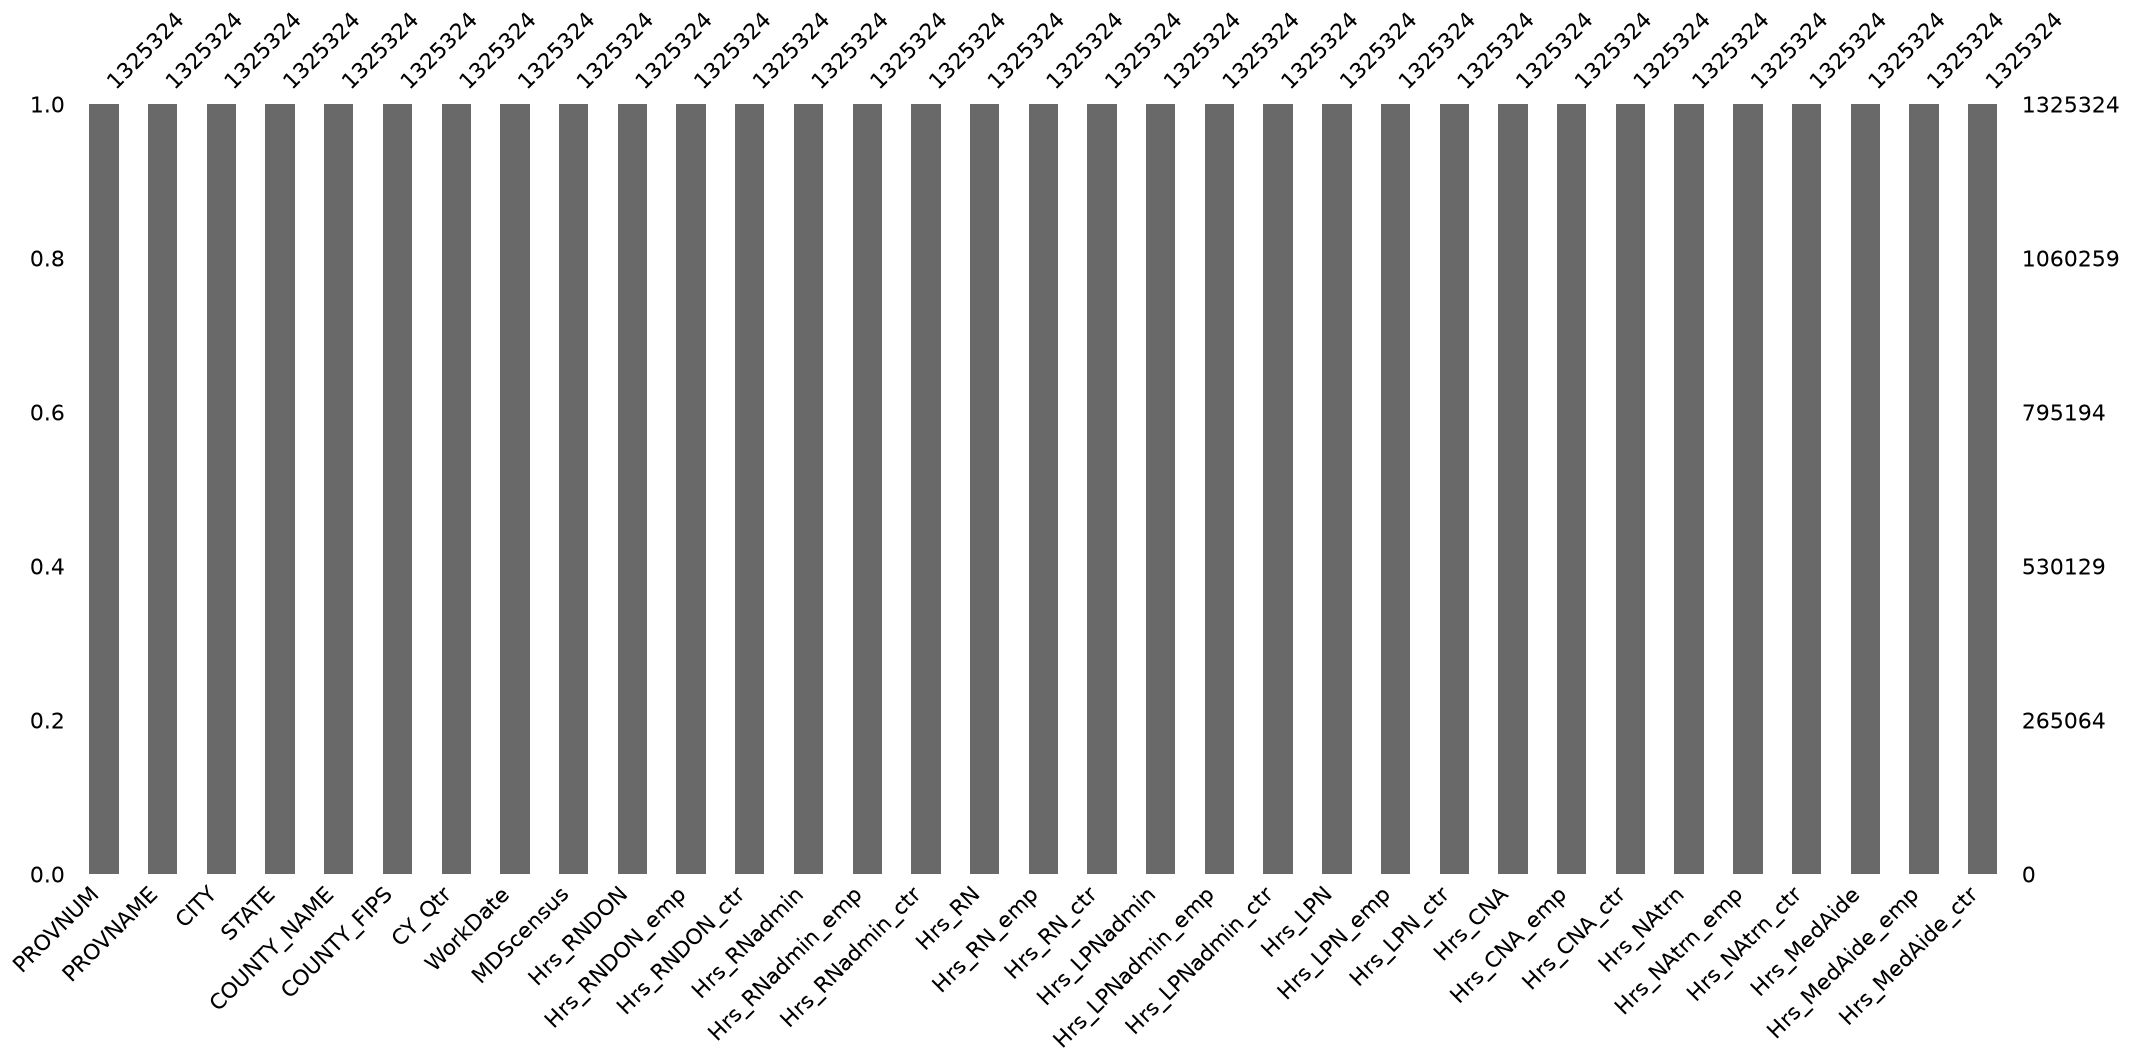

In [7]:
# Null Values
msno.bar(PBJ_Daily_Nurse_Staffing_Q2_2024)

In [8]:
# Duplicates
PBJ_Daily_Nurse_Staffing_Q2_2024_duplicates = PBJ_Daily_Nurse_Staffing_Q2_2024[PBJ_Daily_Nurse_Staffing_Q2_2024.duplicated()]
print(PBJ_Daily_Nurse_Staffing_Q2_2024_duplicates)

Empty DataFrame
Columns: [PROVNUM, PROVNAME, CITY, STATE, COUNTY_NAME, COUNTY_FIPS, CY_Qtr, WorkDate, MDScensus, Hrs_RNDON, Hrs_RNDON_emp, Hrs_RNDON_ctr, Hrs_RNadmin, Hrs_RNadmin_emp, Hrs_RNadmin_ctr, Hrs_RN, Hrs_RN_emp, Hrs_RN_ctr, Hrs_LPNadmin, Hrs_LPNadmin_emp, Hrs_LPNadmin_ctr, Hrs_LPN, Hrs_LPN_emp, Hrs_LPN_ctr, Hrs_CNA, Hrs_CNA_emp, Hrs_CNA_ctr, Hrs_NAtrn, Hrs_NAtrn_emp, Hrs_NAtrn_ctr, Hrs_MedAide, Hrs_MedAide_emp, Hrs_MedAide_ctr]
Index: []


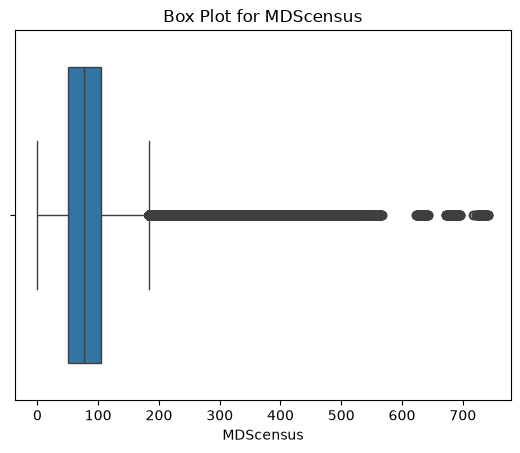

In [9]:
# Outlier Detection: MDScensus (Number of Patients) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['MDScensus'])
plt.title("Box Plot for MDScensus")
plt.show()

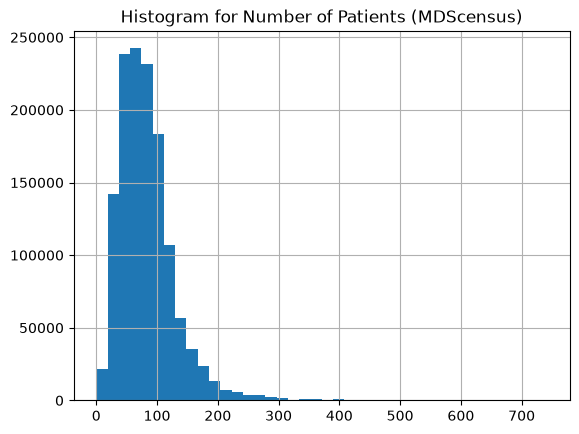

In [10]:
# Outlier Detection: MDScensus (Number of Patients) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['MDScensus'].hist(bins=40)
plt.title("Histogram for Number of Patients (MDScensus)")
plt.show()

In [11]:
# MDScensus_outliers = PBJ_Daily_Nurse_Staffing_Q2_2024[PBJ_Daily_Nurse_Staffing_Q2_2024['MDScensus'] > 300]
# print(MDScensus_outliers)

In [12]:
# Outlier Detection: MDScensus (Number of Patients) Z-Scores - too many rows
# z = np.abs(stats.zscore(PBJ_Daily_Nurse_Staffing_Q2_2024['MDScensus']))
# outliers = PBJ_Daily_Nurse_Staffing_Q2_2024[z > 3]

# print("Outliers:\n", outliers)

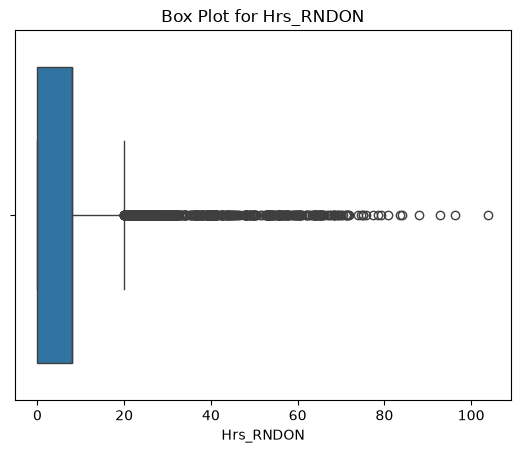

In [13]:
# Outlier Detection: Hrs_RNDON (total hours worked by RNs on duty) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNDON'])
plt.title("Box Plot for Hrs_RNDON")
plt.show()

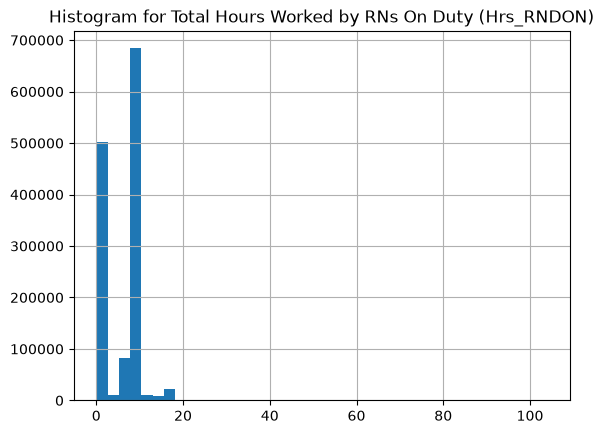

In [14]:
# Outlier Detection: Hrs_RNDON (total hours worked by RNs on duty) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNDON'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by RNs On Duty (Hrs_RNDON)")
plt.show()

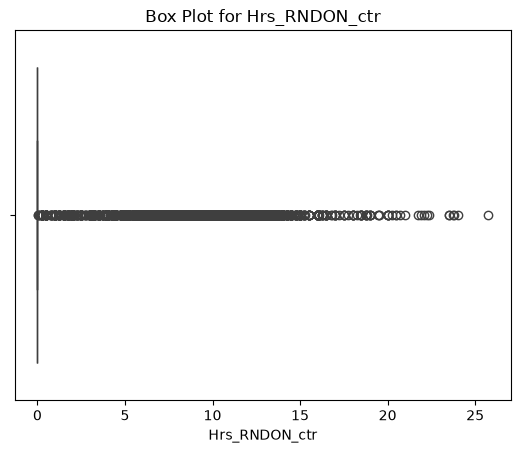

In [15]:
# Outlier Detection: Hrs_RNDON_ctr (total hours worked by contracted RNs on duty) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNDON_ctr'])
plt.title("Box Plot for Hrs_RNDON_ctr")
plt.show()

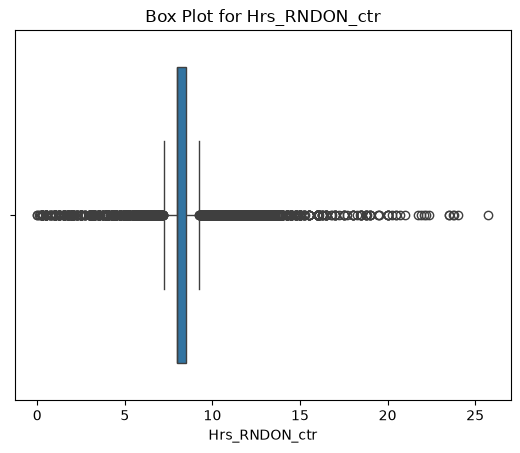

In [16]:
# Outlier Detection: Hrs_RNDON_ctr (total hours worked by contracted RNs on duty) Boxplot

# Exclude 0 values
non_zero_Hrs_RNDON_ctr = PBJ_Daily_Nurse_Staffing_Q2_2024[PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNDON_ctr'] > 0]

sns.boxplot(x=non_zero_Hrs_RNDON_ctr['Hrs_RNDON_ctr'])
plt.title("Box Plot for Hrs_RNDON_ctr")
plt.show()

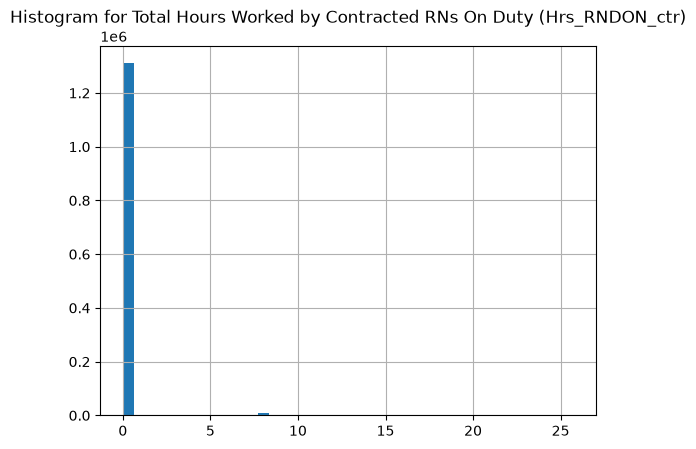

In [17]:
# Outlier Detection: Hrs_RNDON_ctr (total hours worked by contracted RNs on duty) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNDON_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted RNs On Duty (Hrs_RNDON_ctr)")
plt.show()

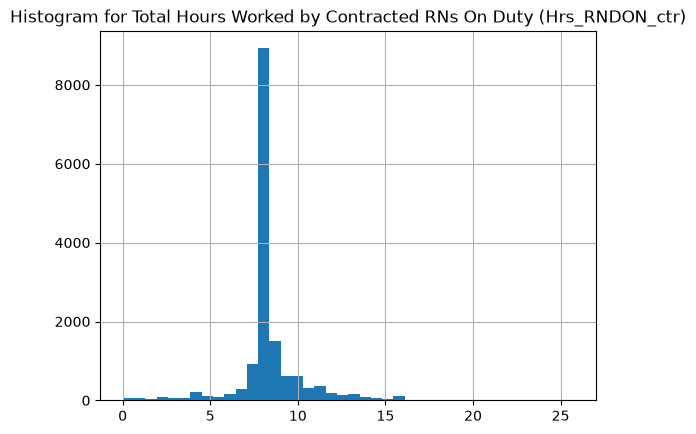

In [18]:
# Outlier Detection: Hrs_RNDON_ctr (total hours worked by contracted RNs on duty) Histogram
non_zero_Hrs_RNDON_ctr['Hrs_RNDON_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted RNs On Duty (Hrs_RNDON_ctr)")
plt.show()

In [19]:
# Check the kurtosis ('tailedness' of the probability distribution; standard kurtosis = 3, leptokurtic > 3, platykurtic < 3)
print(non_zero_Hrs_RNDON_ctr['Hrs_RNDON_ctr'].kurtosis())

8.292229299656956


In [20]:
# Identify values with > 25 total hours worked by contracted RNs on duty
Hrs_RNDON_ctr_outliers = PBJ_Daily_Nurse_Staffing_Q2_2024[PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNDON_ctr'] > 25].iloc[:, [0, 1, 2, 3, 7, 11]]
print(Hrs_RNDON_ctr_outliers)

        PROVNUM                      PROVNAME   CITY STATE  WorkDate  \
1157147  515140  TRINITY HEALTH CARE OF LOGAN  LOGAN    WV  20240622   

         Hrs_RNDON_ctr  
1157147          25.75  


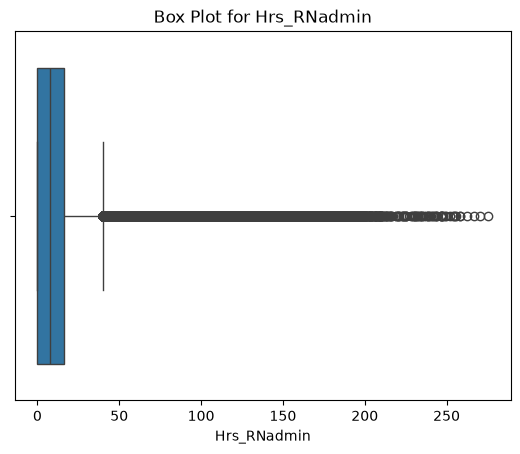

In [21]:
# Outlier Detection: Hrs_RNadmin (total hours worked by RNs Admins) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNadmin'])
plt.title("Box Plot for Hrs_RNadmin")
plt.show()

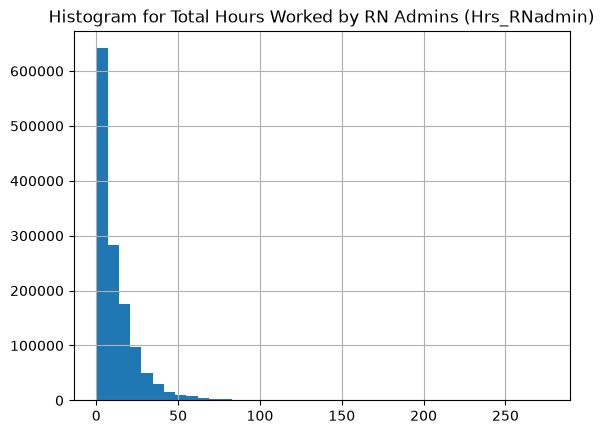

In [22]:
# Outlier Detection: Hrs_RNadmin (total hours worked by RNs Admins) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNadmin'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by RN Admins (Hrs_RNadmin)")
plt.show()

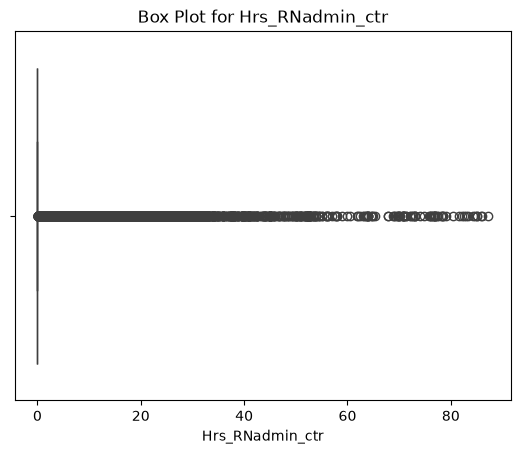

In [23]:
# Outlier Detection: Hrs_RNadmin_ctr (total hours worked by contracted RNs Admins) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNadmin_ctr'])
plt.title("Box Plot for Hrs_RNadmin_ctr")
plt.show()

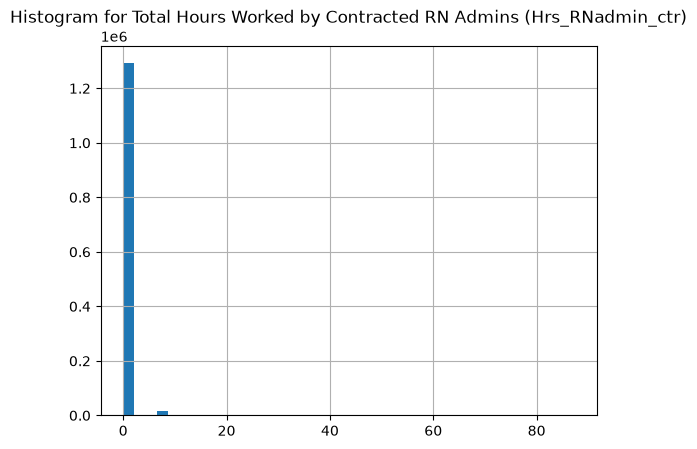

In [24]:
# Outlier Detection: Hrs_RNadmin_ctr (total hours worked by contracted RNs Admins) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RNadmin_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted RN Admins (Hrs_RNadmin_ctr)")
plt.show()

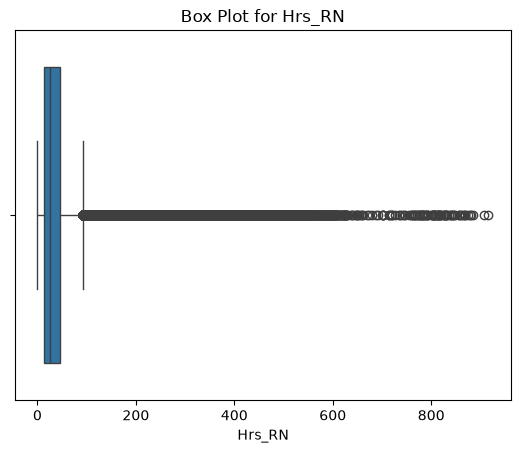

In [25]:
# Outlier Detection: Hrs_RN (total hours worked by RNs) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RN'])
plt.title("Box Plot for Hrs_RN")
plt.show()

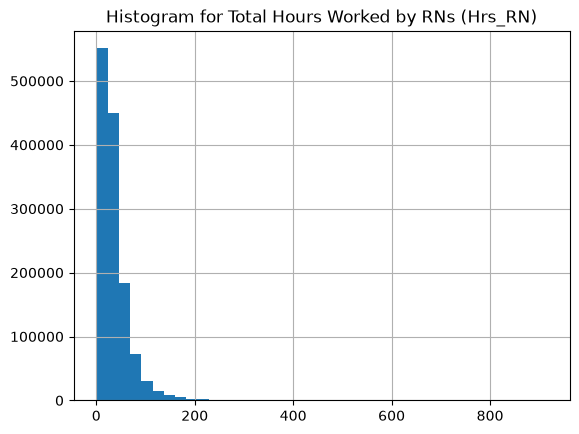

In [26]:
# Outlier Detection: Hrs_RN (total hours worked by RNs) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RN'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by RNs (Hrs_RN)")
plt.show()

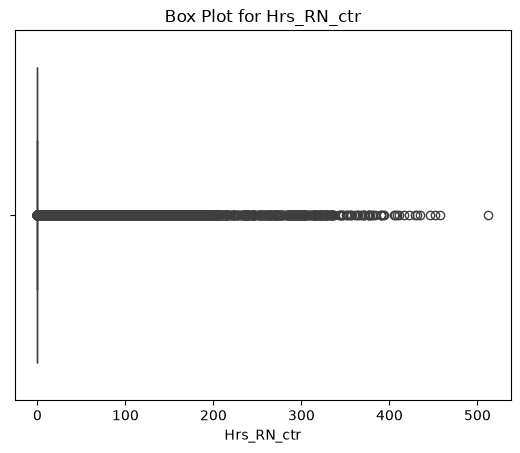

In [27]:
# Outlier Detection: Hrs_RN_ctr (total hours worked by contracted RNs) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RN_ctr'])
plt.title("Box Plot for Hrs_RN_ctr")
plt.show()

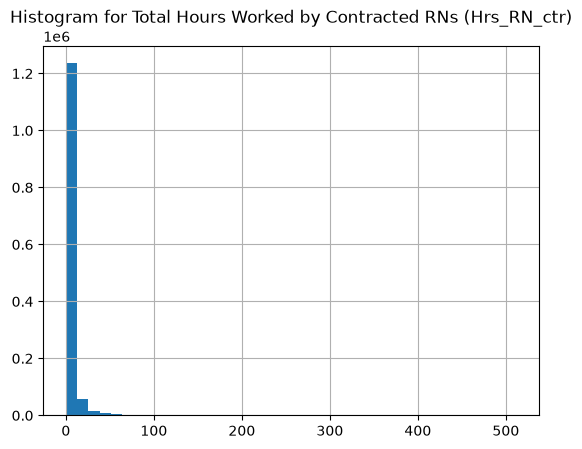

In [28]:
# Outlier Detection: Hrs_RN_ctr (total hours worked by contracted RNs) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_RN_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted RNs (Hrs_RN_ctr)")
plt.show()

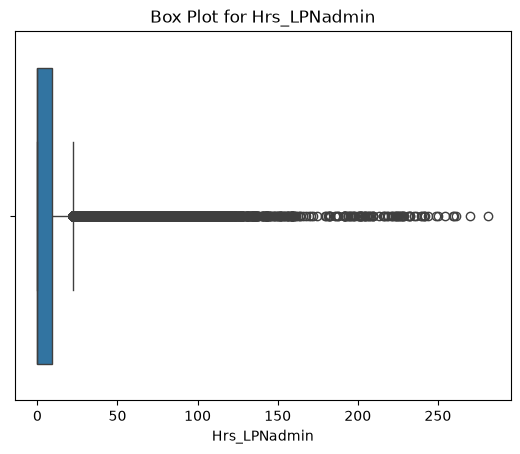

In [29]:
# Outlier Detection: Hrs_LPNadmin (total hours worked by Licensed Practical Nurse (LPN) administrators) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPNadmin'])
plt.title("Box Plot for Hrs_LPNadmin")
plt.show()

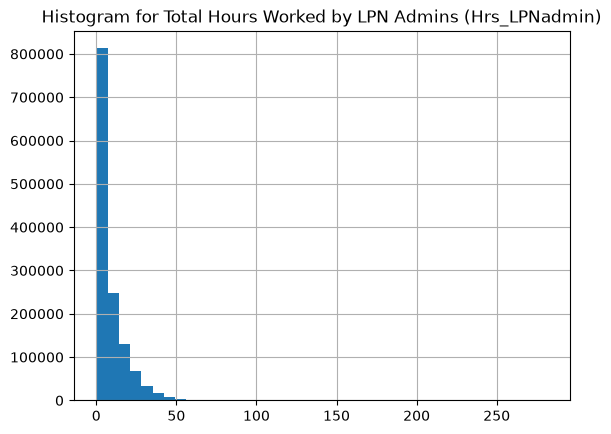

In [30]:
# Outlier Detection: Hrs_LPNadmin (total hours worked by Licensed Practical Nurse (LPN) administrators) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPNadmin'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by LPN Admins (Hrs_LPNadmin)")
plt.show()

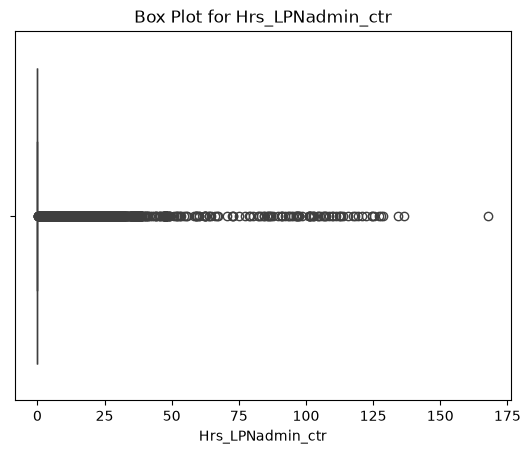

In [31]:
# Outlier Detection: Hrs_LPNadmin_ctr (total hours worked by contracted Licensed Practical Nurse (LPN) administrators) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPNadmin_ctr'])
plt.title("Box Plot for Hrs_LPNadmin_ctr")
plt.show()

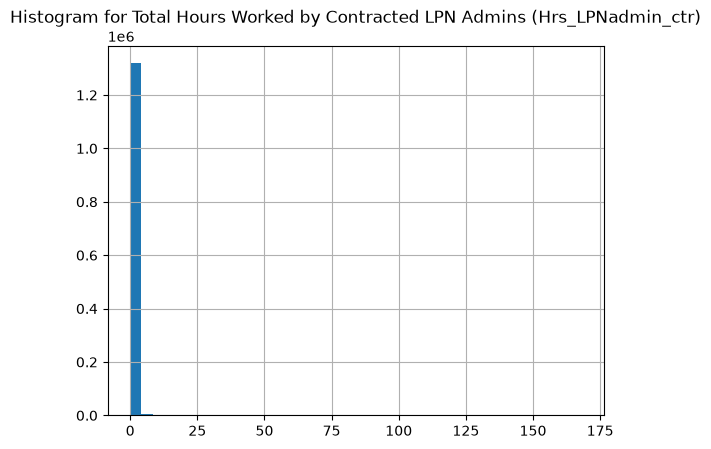

In [32]:
# Outlier Detection: Hrs_LPNadmin_ctr (total hours worked by contracted Licensed Practical Nurse (LPN) administrators) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPNadmin_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted LPN Admins (Hrs_LPNadmin_ctr)")
plt.show()

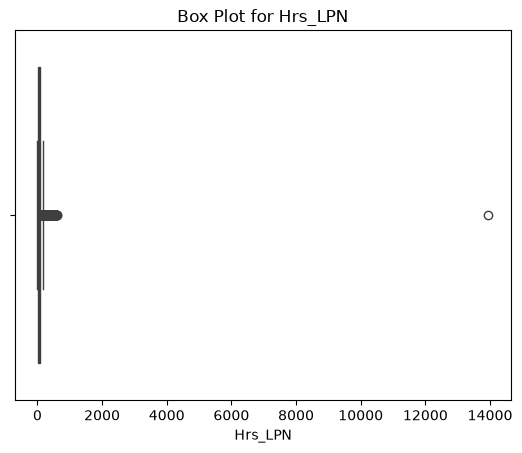

In [33]:
# Outlier Detection: Hrs_LPN (total hours worked by Licensed Practical Nurses (LPNs)) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPN'])
plt.title("Box Plot for Hrs_LPN")
plt.show()

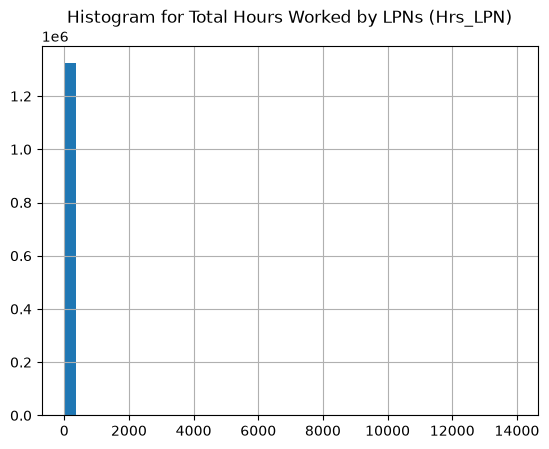

In [34]:
# Outlier Detection: Hrs_LPN (total hours worked by Licensed Practical Nurses (LPNs)) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPN'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by LPNs (Hrs_LPN)")
plt.show()

In [35]:
# Identify value with > 10000 total hours worked by LPNs
Hrs_LPN_outliers = PBJ_Daily_Nurse_Staffing_Q2_2024[PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPN'] > 10000].iloc[:, [0, 1, 2, 3, 7, 21]]
print(Hrs_LPN_outliers)

       PROVNUM                     PROVNAME       CITY STATE  WorkDate  \
272144  145446  MARIGOLD REHABILITATION HCC  GALESBURG    IL  20240525   

         Hrs_LPN  
272144  13946.25  


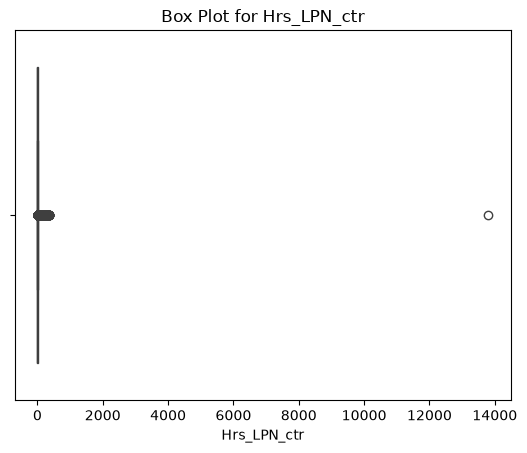

In [36]:
# Outlier Detection: Hrs_LPN_ctr (total hours worked by contracted Licensed Practical Nurses (LPNs)) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPN_ctr'])
plt.title("Box Plot for Hrs_LPN_ctr")
plt.show()

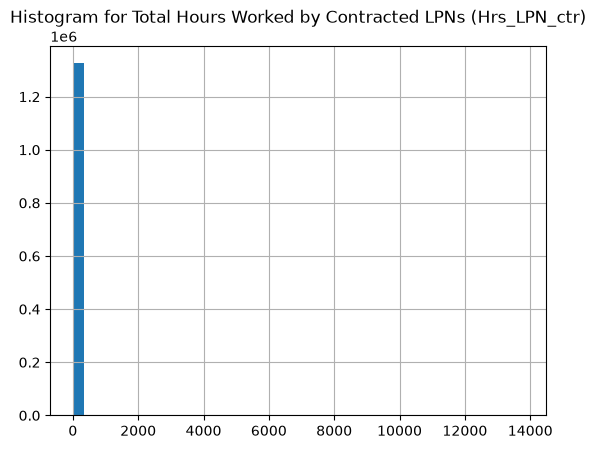

In [37]:
# Outlier Detection: Hrs_LPN_ctr (total hours worked by contracted Licensed Practical Nurses (LPNs)) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_LPN_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted LPNs (Hrs_LPN_ctr)")
plt.show()

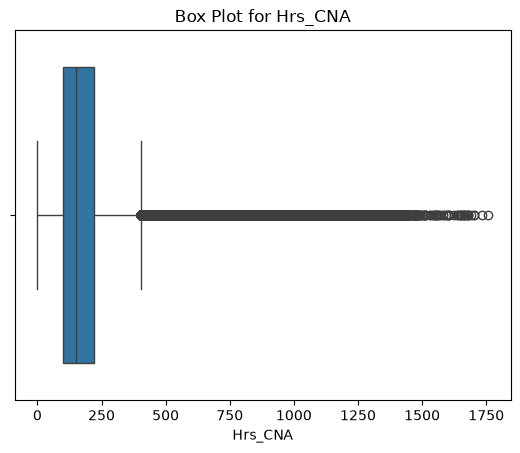

In [38]:
# Outlier Detection: Hrs_CNA (total hours worked by Certified Nursing Assistants (CNAs)) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_CNA'])
plt.title("Box Plot for Hrs_CNA")
plt.show()

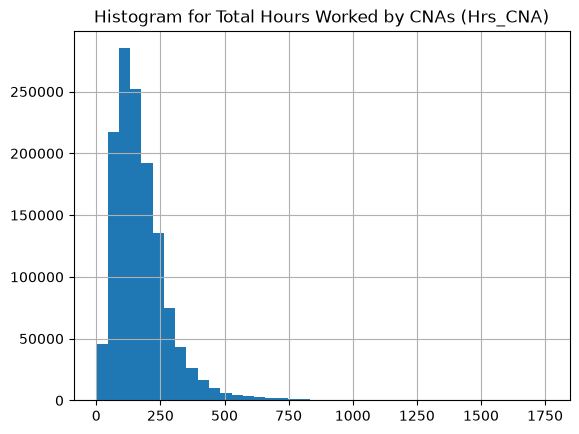

In [39]:
# Outlier Detection: Hrs_CNA (total hours worked by Certified Nursing Assistants (CNAs)) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_CNA'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by CNAs (Hrs_CNA)")
plt.show()

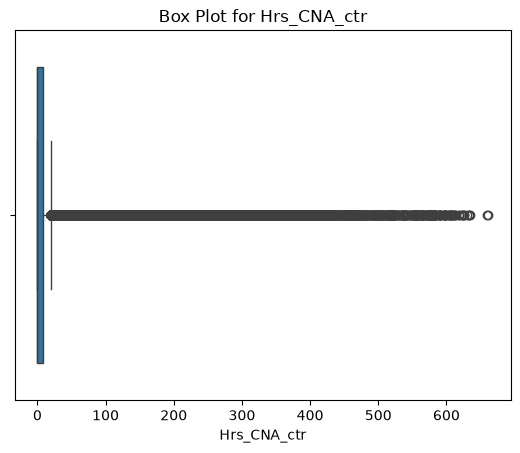

In [40]:
# Outlier Detection: Hrs_CNA_ctr (total hours worked by contracted Certified Nursing Assistants (CNAs)) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_CNA_ctr'])
plt.title("Box Plot for Hrs_CNA_ctr")
plt.show()

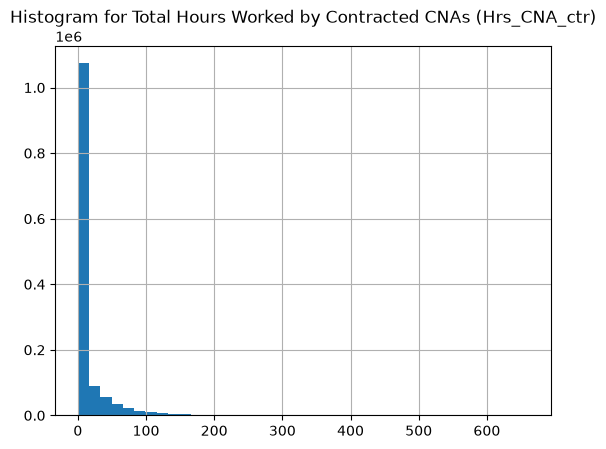

In [41]:
# Outlier Detection: Hrs_CNA_ctr (total hours worked by contracted Certified Nursing Assistants (CNAs)) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_CNA_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted CNAs (Hrs_CNA_ctr)")
plt.show()

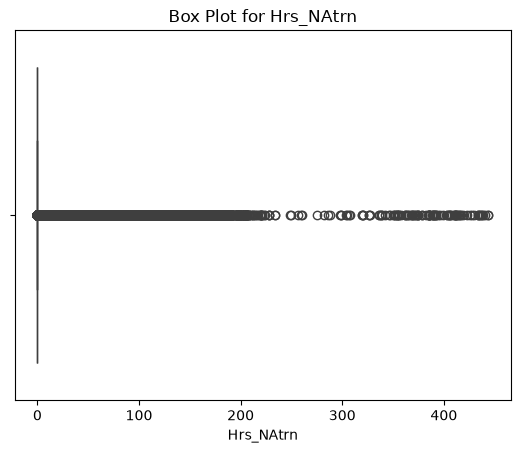

In [42]:
# Outlier Detection: Hrs_NAtrn (total hours worked by Nursing Assistants in training) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_NAtrn'])
plt.title("Box Plot for Hrs_NAtrn")
plt.show()

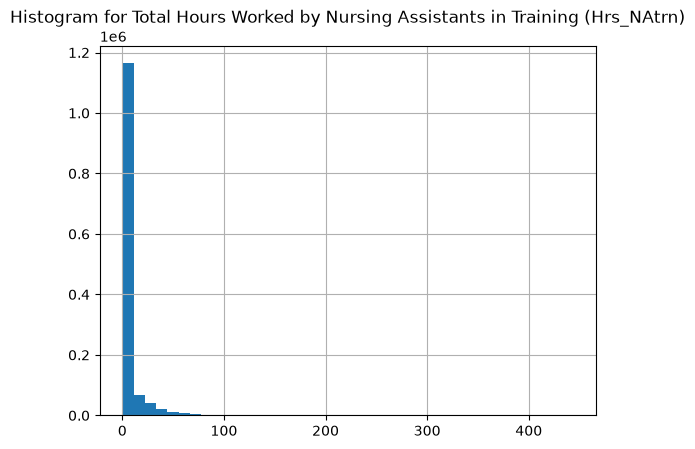

In [43]:
# Outlier Detection: Hrs_NAtrn (total hours worked by Nursing Assistants in training) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_NAtrn'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Nursing Assistants in Training (Hrs_NAtrn)")
plt.show()

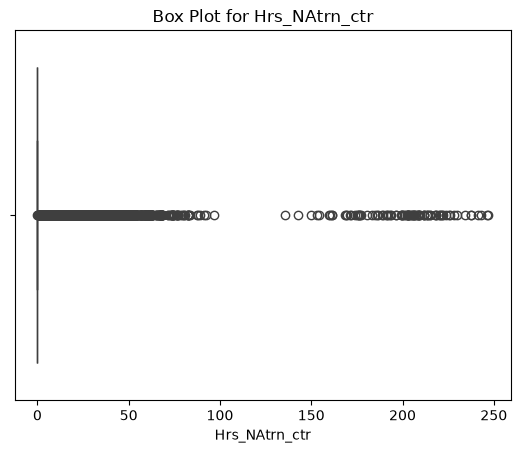

In [44]:
# Outlier Detection: Hrs_NAtrn_ctr (total hours worked by contracted Nursing Assistants in training) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_NAtrn_ctr'])
plt.title("Box Plot for Hrs_NAtrn_ctr")
plt.show()

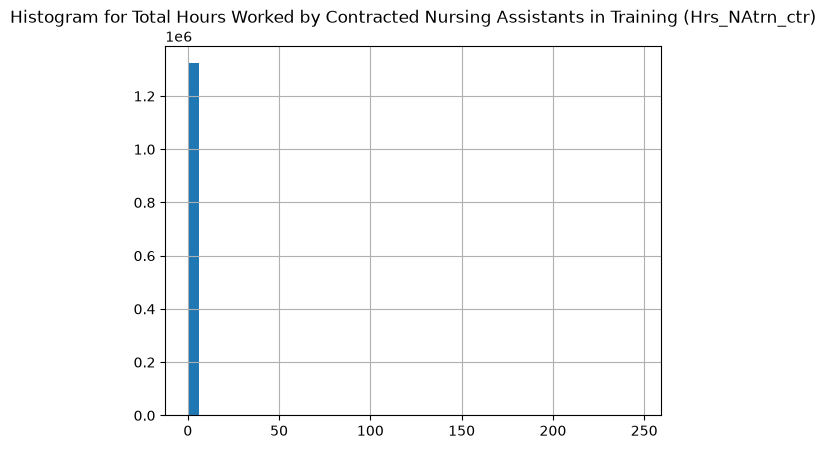

In [45]:
# Outlier Detection: Hrs_NAtrn_ctr (total hours worked by contracted Nursing Assistants in training) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_NAtrn_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted Nursing Assistants in Training (Hrs_NAtrn_ctr)")
plt.show()

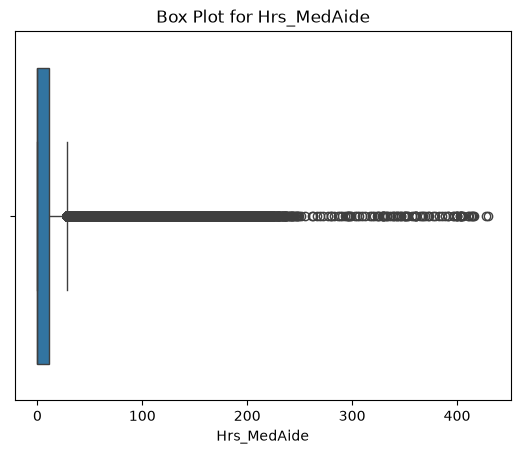

In [46]:
# Outlier Detection: Hrs_MedAide (total hours worked by Medication Aides) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_MedAide'])
plt.title("Box Plot for Hrs_MedAide")
plt.show()

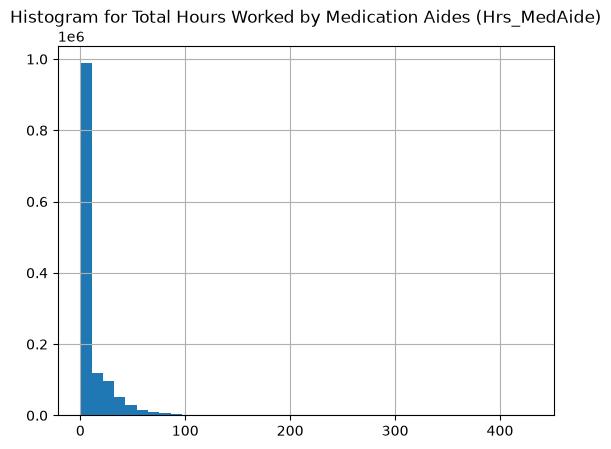

In [47]:
# Outlier Detection: Hrs_MedAide (total hours worked by Medication Aides) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_MedAide'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Medication Aides (Hrs_MedAide)")
plt.show()

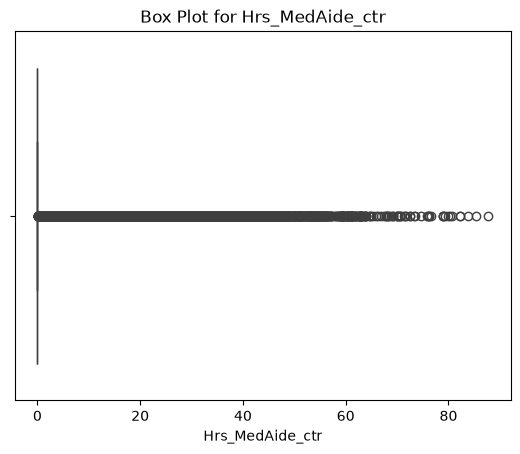

In [48]:
# Outlier Detection: Hrs_MedAide_ctr (total hours worked by contracted Medication Aides) Boxplot
sns.boxplot(x=PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_MedAide_ctr'])
plt.title("Box Plot for Hrs_MedAide_ctr")
plt.show()

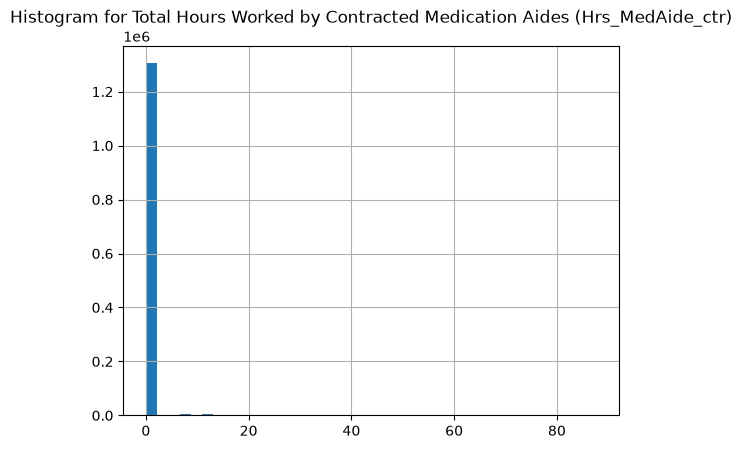

In [49]:
# Outlier Detection: Hrs_MedAide_ctr (total hours worked by contracted Medication Aides) Histogram
PBJ_Daily_Nurse_Staffing_Q2_2024['Hrs_MedAide_ctr'].hist(bins=40)
plt.title("Histogram for Total Hours Worked by Contracted Medication Aides (Hrs_MedAide_ctr)")
plt.show()

### FY 2024 SNF VBP Aggregate Performance
- Contains national, aggregate-level results for the FY 2024 Skilled Nursing Facility Value-Based Purchasing (SNF VBP) Program.
    - Includes unadjusted national average readmission rates for the baseline period (FY 2019) and performance period (FY 2022), the achieve threshold and benchmark (that is, the performance standards for the FY 2024 SNF VBP Program year), and info on performance scores, incentive payment multipliers, value-based incentive payments (in dollars), and the total number of SNFs received value-based incentive payments for the FY 2024 SNF VBP Program year.
- Note: SNFs that did not meet the SNFRM's case minimum (25 or more eligible stays) in the performance period (FY 2022) are excluded from the SNF VBP Program for FY 2024. Payments to these SNFs in FY 2024 will not be affected by the SNF VBP Program; instead, these SNFs will receive their adjusted federal per diem rate.
    - CMS will not publicly report any data for the FY 2024 SNF VBP Program year for these excluded SNFs.

In [50]:
FY_2024_SNF_VBP_Aggregate_Performance.head()

,Baseline Period: FY 2019 National Average Readmission Rate,Performance Period: FY 2022 National Average Readmission Rate,FY 2024 Achievement Threshold,FY 2024 Benchmark,Range of Performance Scores,Total Number of SNFs Receiving Value-Based Incentive Payments,Range of Incentive Payment Multipliers,Range of Value-Based Incentive Payments ($),Total Amount of Value-Based Incentive Payments ($)
0,0.19788,0.20223,0.79271,0.83033,0.00000-100.00000,10858,0.9802538758-1.0176785153,To be added after the end of FY 2024,To be added after the end of FY 2024


In [51]:
FY_2024_SNF_VBP_Aggregate_Performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 9 columns):
 #   Column                                                         Non-Null Count  Dtype  
---  ------                                                         --------------  -----  
 0   Baseline Period: FY 2019 National Average Readmission Rate     1 non-null      float64
 1   Performance Period: FY 2022 National Average Readmission Rate  1 non-null      float64
 2   FY 2024 Achievement Threshold                                  1 non-null      float64
 3   FY 2024 Benchmark                                              1 non-null      float64
 4   Range of Performance Scores                                    1 non-null      str    
 5   Total Number of SNFs Receiving Value-Based Incentive Payments  1 non-null      int64  
 6   Range of Incentive Payment Multipliers                         1 non-null      str    
 7   Range of Value-Based Incentive Payments ($)                    1 non-null     

<Axes: >

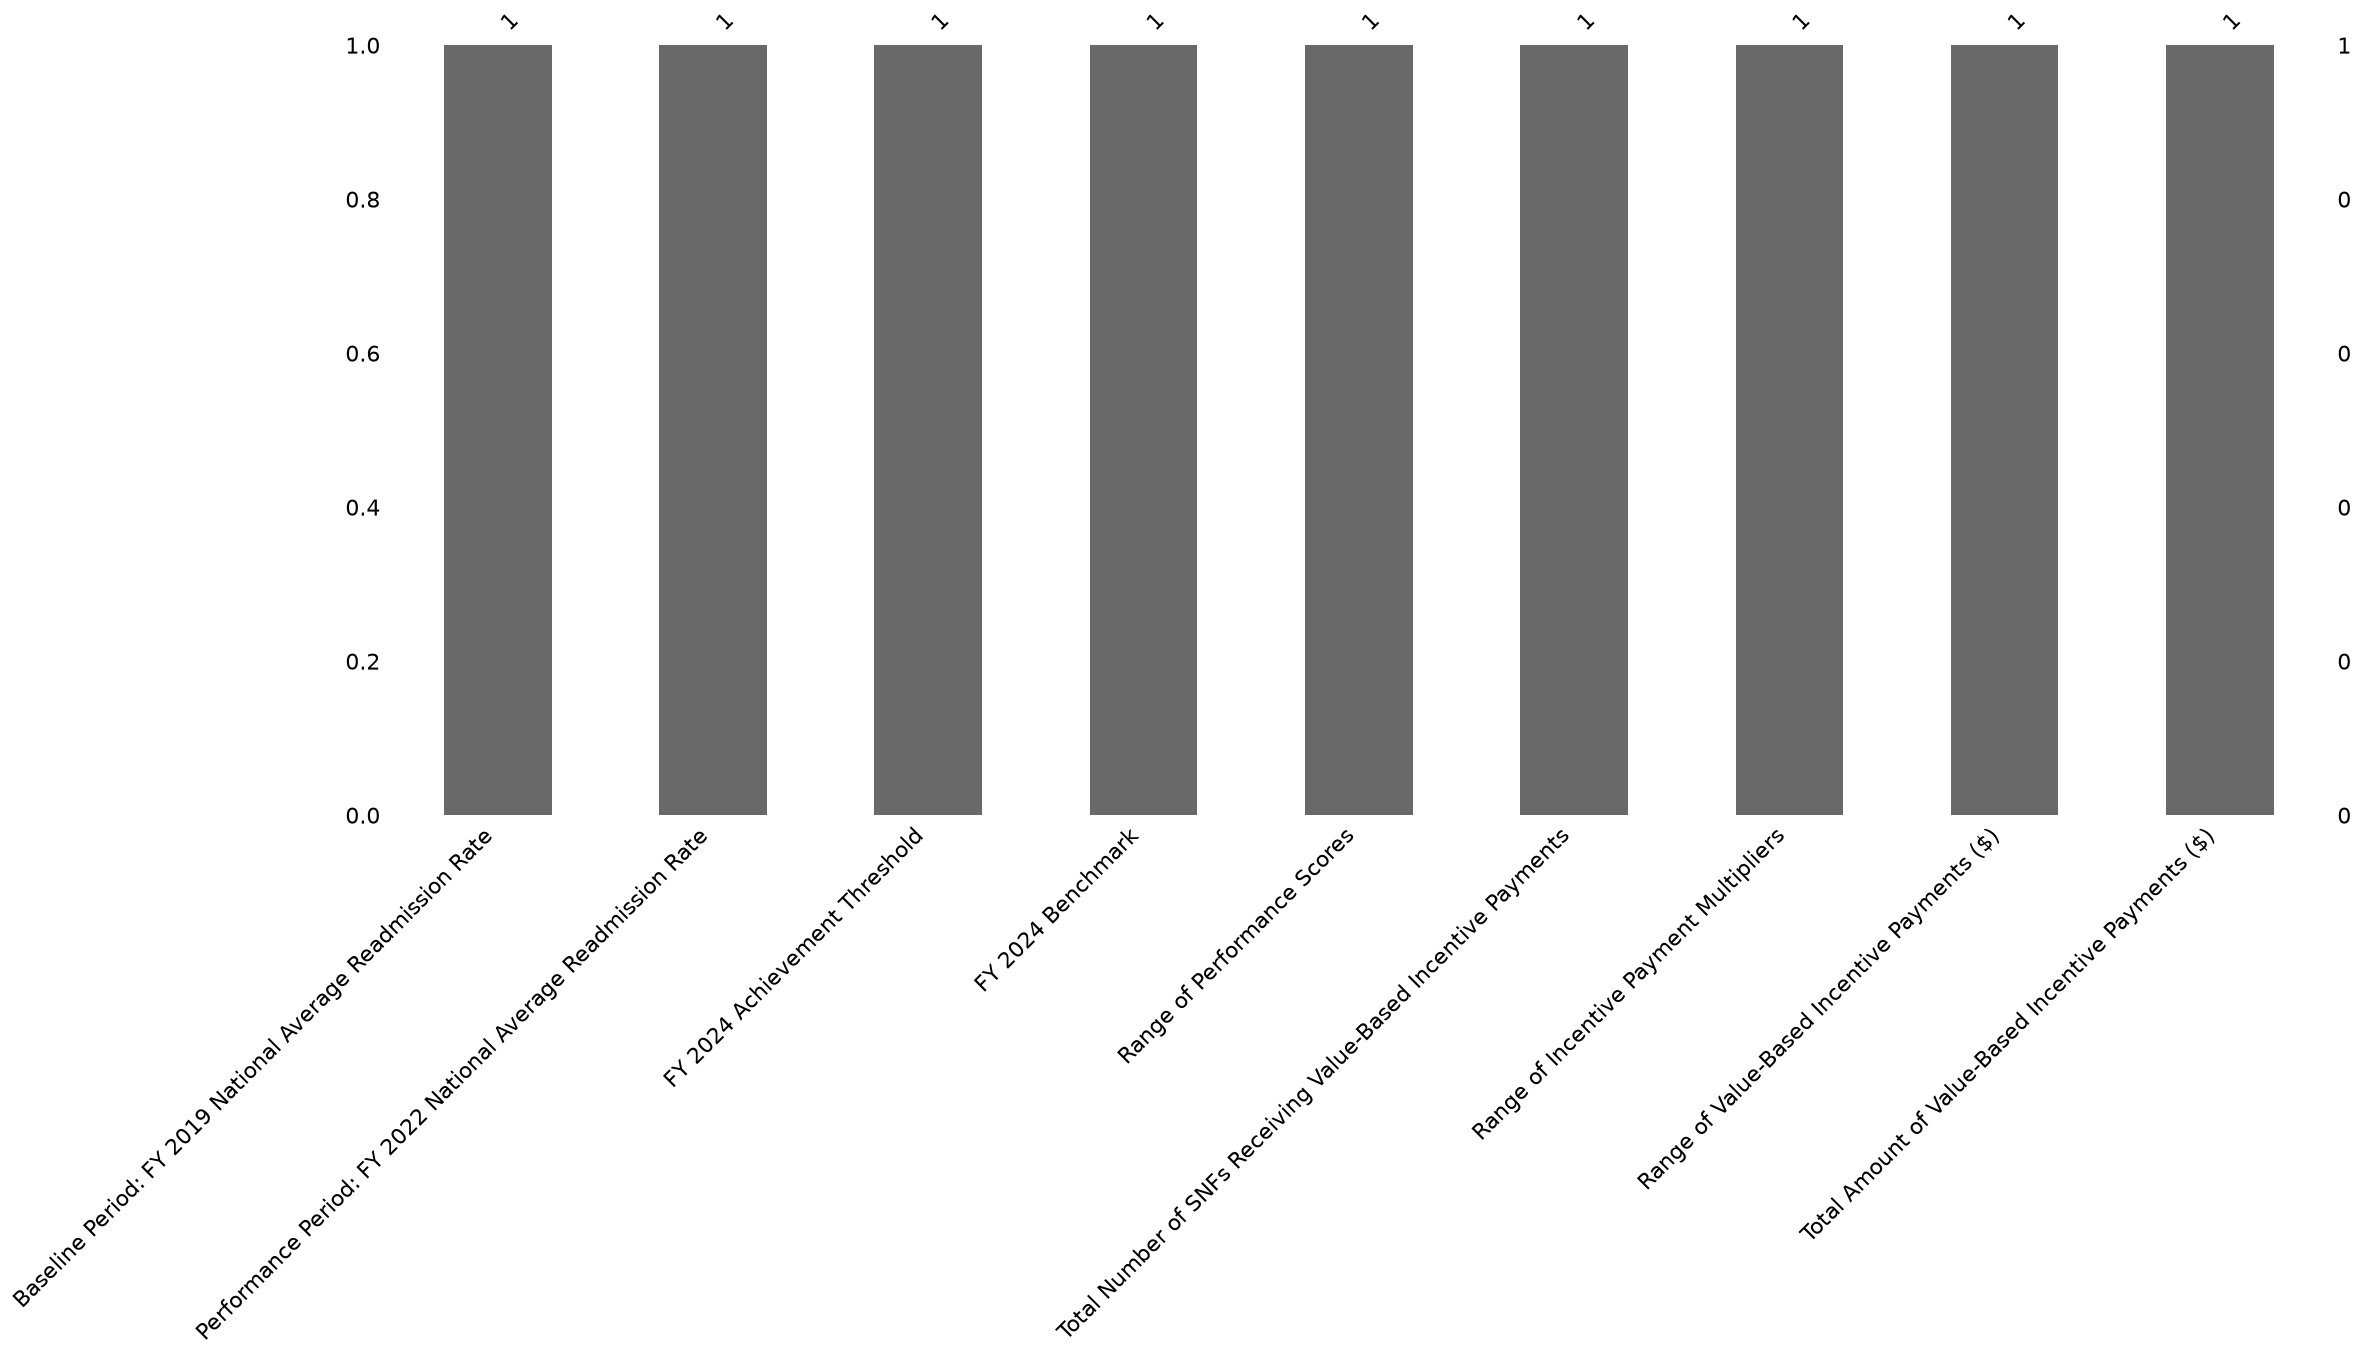

In [52]:
# Null Values
msno.bar(FY_2024_SNF_VBP_Aggregate_Performance)

### FY 2024 SNF VBP Facility-Level Dataset
- Contains facility-specific performance results for the FY 2024 Skilled Nursing Facility Value-Based Purchasing (SNF VBP) Program.
    - Includes baseline period (FY 2019) and performance period (FY 2022) risk-standardized readmission rates (RSRRs), achievement scores, improvement scores, and performance scores, rankings, and incentive payment multipliers for the FY 2024 SNF VBP Program year.
- Note: SNFs that did not meet the SNFRM's case minimum (25 or more eligible stays) in the performance period (FY 2022) are excluded from the SNF VBP Program for FY 2024. Payments to these SNFs in FY 2024 will not be affected by the SNF VBP Program; instead, these SNFs will receive their adjusted federal per diem rate.
    - CMS will not publicly report any data for the FY 2024 SNF VBP Program year for these excluded SNFs.

In [53]:
FY_2024_SNF_VBP_Facility_Performance.head()

,SNF VBP Program Ranking,Footnote -- SNF VBP Program Ranking,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Baseline Period: FY 2019 Risk-Standardized Readmission Rate,Footnote -- Baseline Period: FY 2019 Risk-Standardized Readmission Rate,Performance Period: FY 2022 Risk-Standardized Readmission Rate,Footnote -- Performance Period: FY 2022 Risk-Standardized Readmission Rate,Achievement Score,Footnote -- Achievement Score,Improvement Score,Footnote -- Improvement Score,Performance Score,Footnote -- Performance Score,Incentive Payment Multiplier,Footnote -- Incentive Payment Multiplier
0,7275,NaN,10007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,OPP,AL,36467,0.20018,NaN,0.23768,NaN,0.00000,NaN,0.00000,NaN,0.00000,NaN,0.980254,NaN
1,602,NaN,10044,MARION REGIONAL MEDICAL CENTER,1256 MILITARY STREET SOUTH,HAMILTON,AL,35570,0.17051,NaN,0.17070,NaN,92.53589,NaN,0.00000,NaN,92.53589,NaN,1.017401,NaN
2,712,NaN,10045,FAYETTE MEDICAL CENTER,1653 TEMPLE AVENUE NORTH,FAYETTE,AL,35555,0.18901,NaN,0.17240,NaN,88.46890,NaN,80.88418,NaN,88.46890,NaN,1.017140,NaN
3,2966,NaN,10058,BIBB MEDICAL CENTER,208 PIERSON AVE,CENTREVILLE,AL,35042,0.18295,NaN,0.18755,NaN,52.22488,NaN,0.00000,NaN,52.22488,NaN,1.001067,NaN
4,791,NaN,10065,RUSSELL MEDICAL CENTER,3316 HIGHWAY 280,ALEXANDER CITY,AL,35010,0.19672,NaN,0.17320,NaN,86.55502,NaN,81.95009,NaN,86.55502,NaN,1.016977,NaN


#### Examples of Null Value Charts

In [54]:
FY_2024_SNF_VBP_Facility_Performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 10858 entries, 0 to 10857
Data columns (total 20 columns):
 #   Column                                                                      Non-Null Count  Dtype  
---  ------                                                                      --------------  -----  
 0   SNF VBP Program Ranking                                                     10858 non-null  int64  
 1   Footnote -- SNF VBP Program Ranking                                         0 non-null      float64
 2   CMS Certification Number (CCN)                                              10858 non-null  int64  
 3   Provider Name                                                               10858 non-null  str    
 4   Provider Address                                                            10858 non-null  str    
 5   City/Town                                                                   10858 non-null  str    
 6   State                                                    

<Axes: >

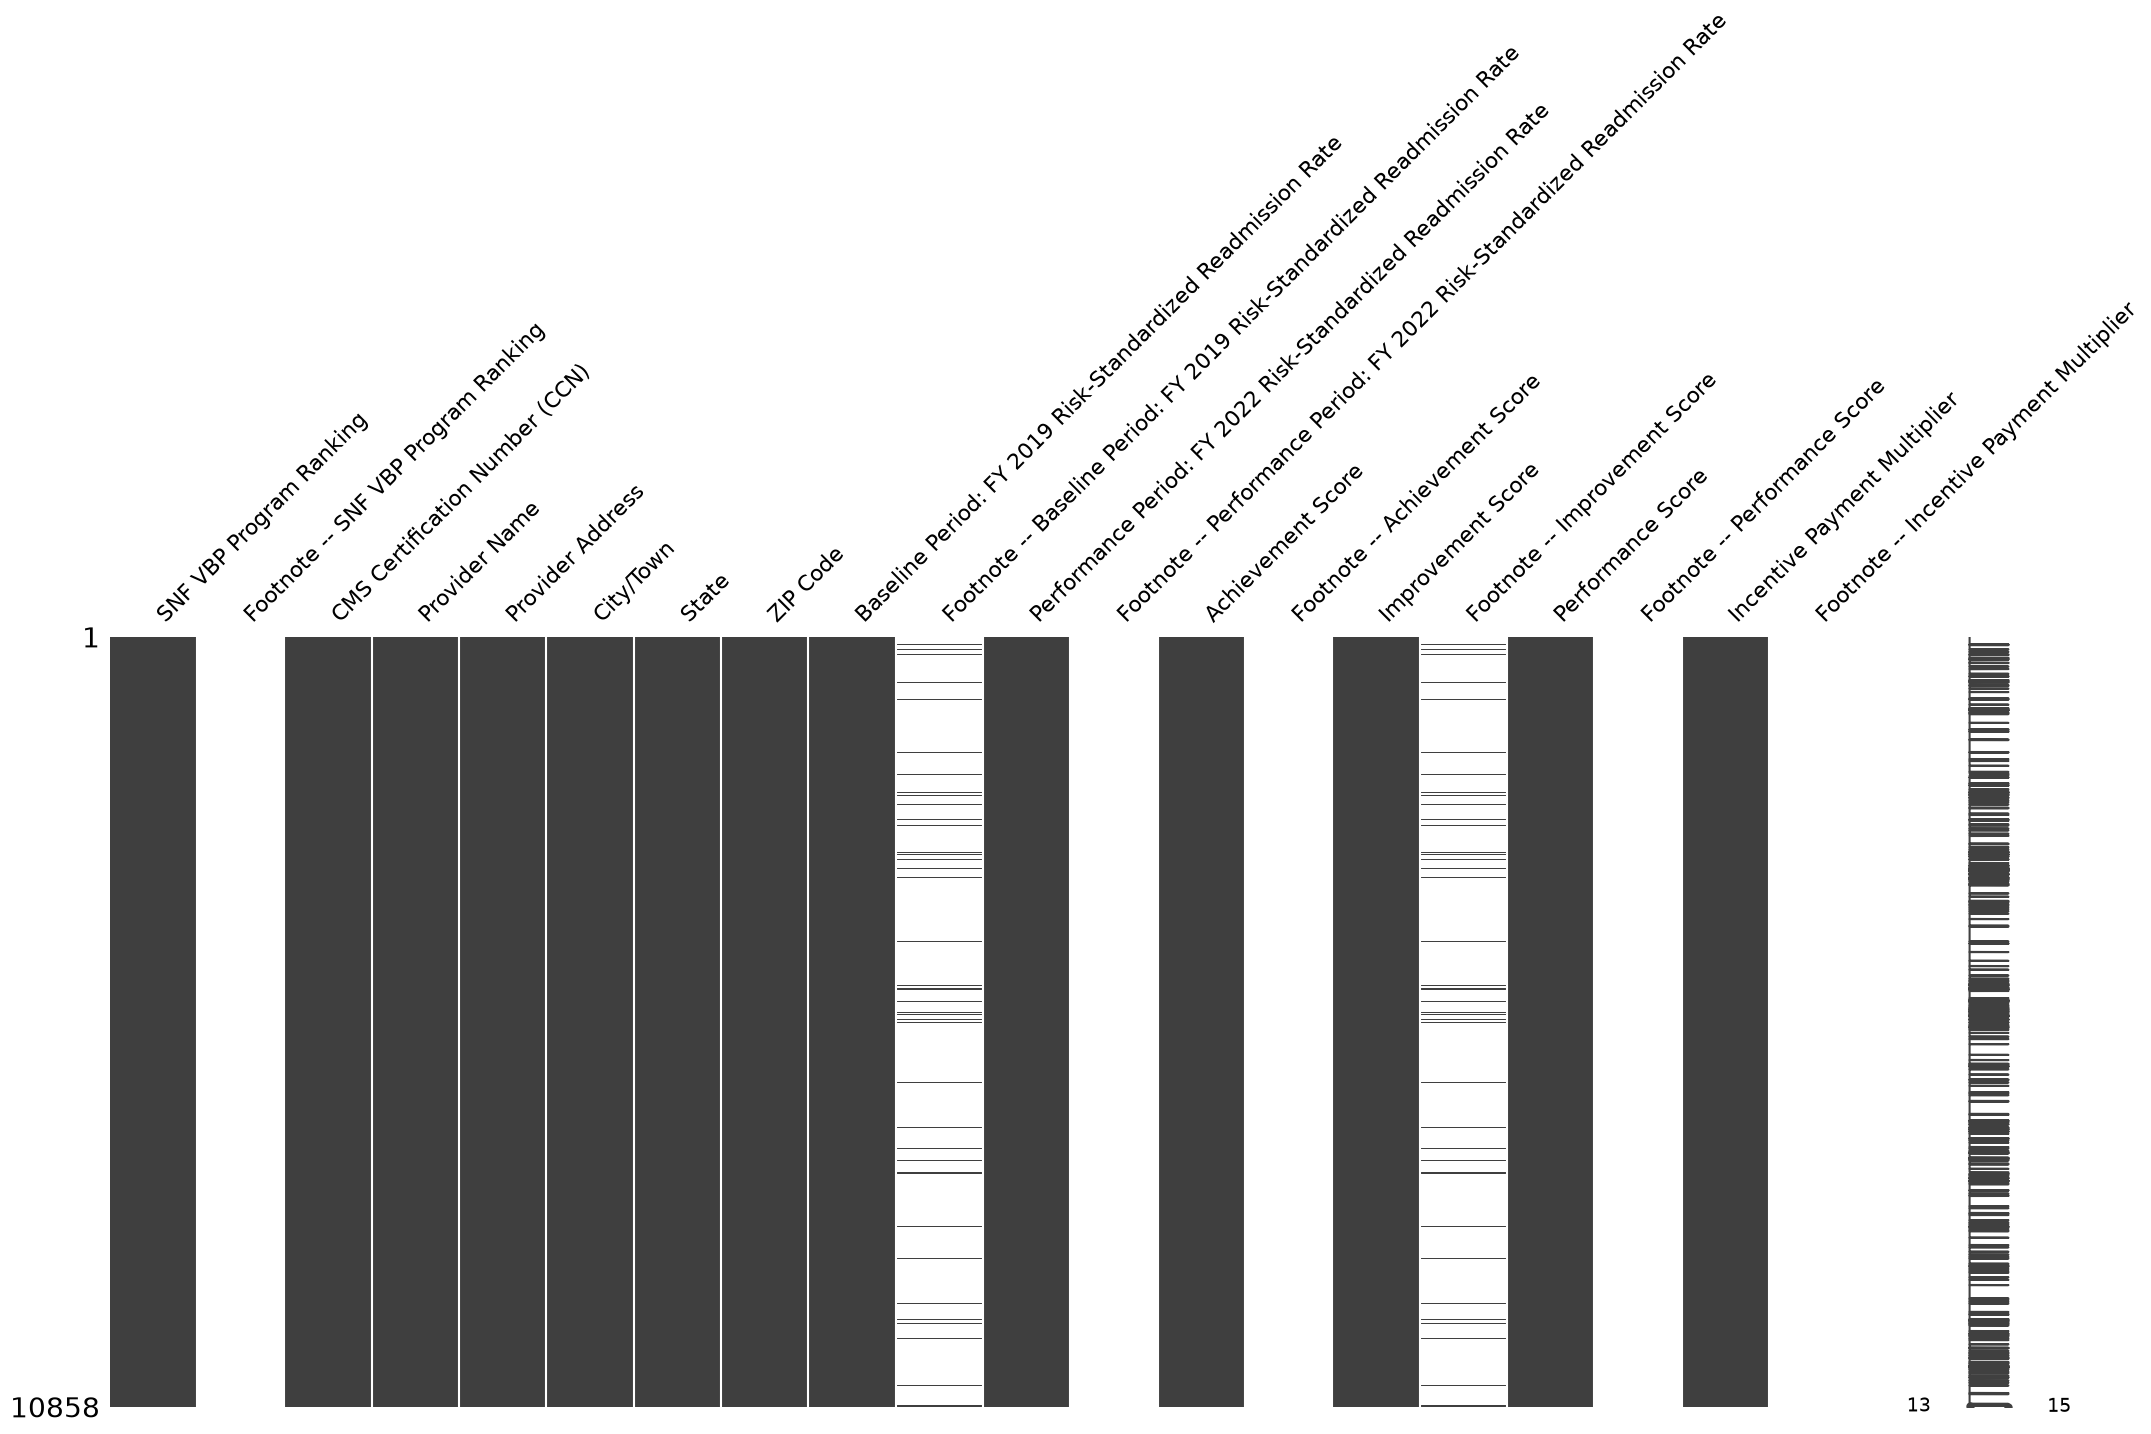

In [55]:
msno.matrix(FY_2024_SNF_VBP_Facility_Performance)

<Axes: >

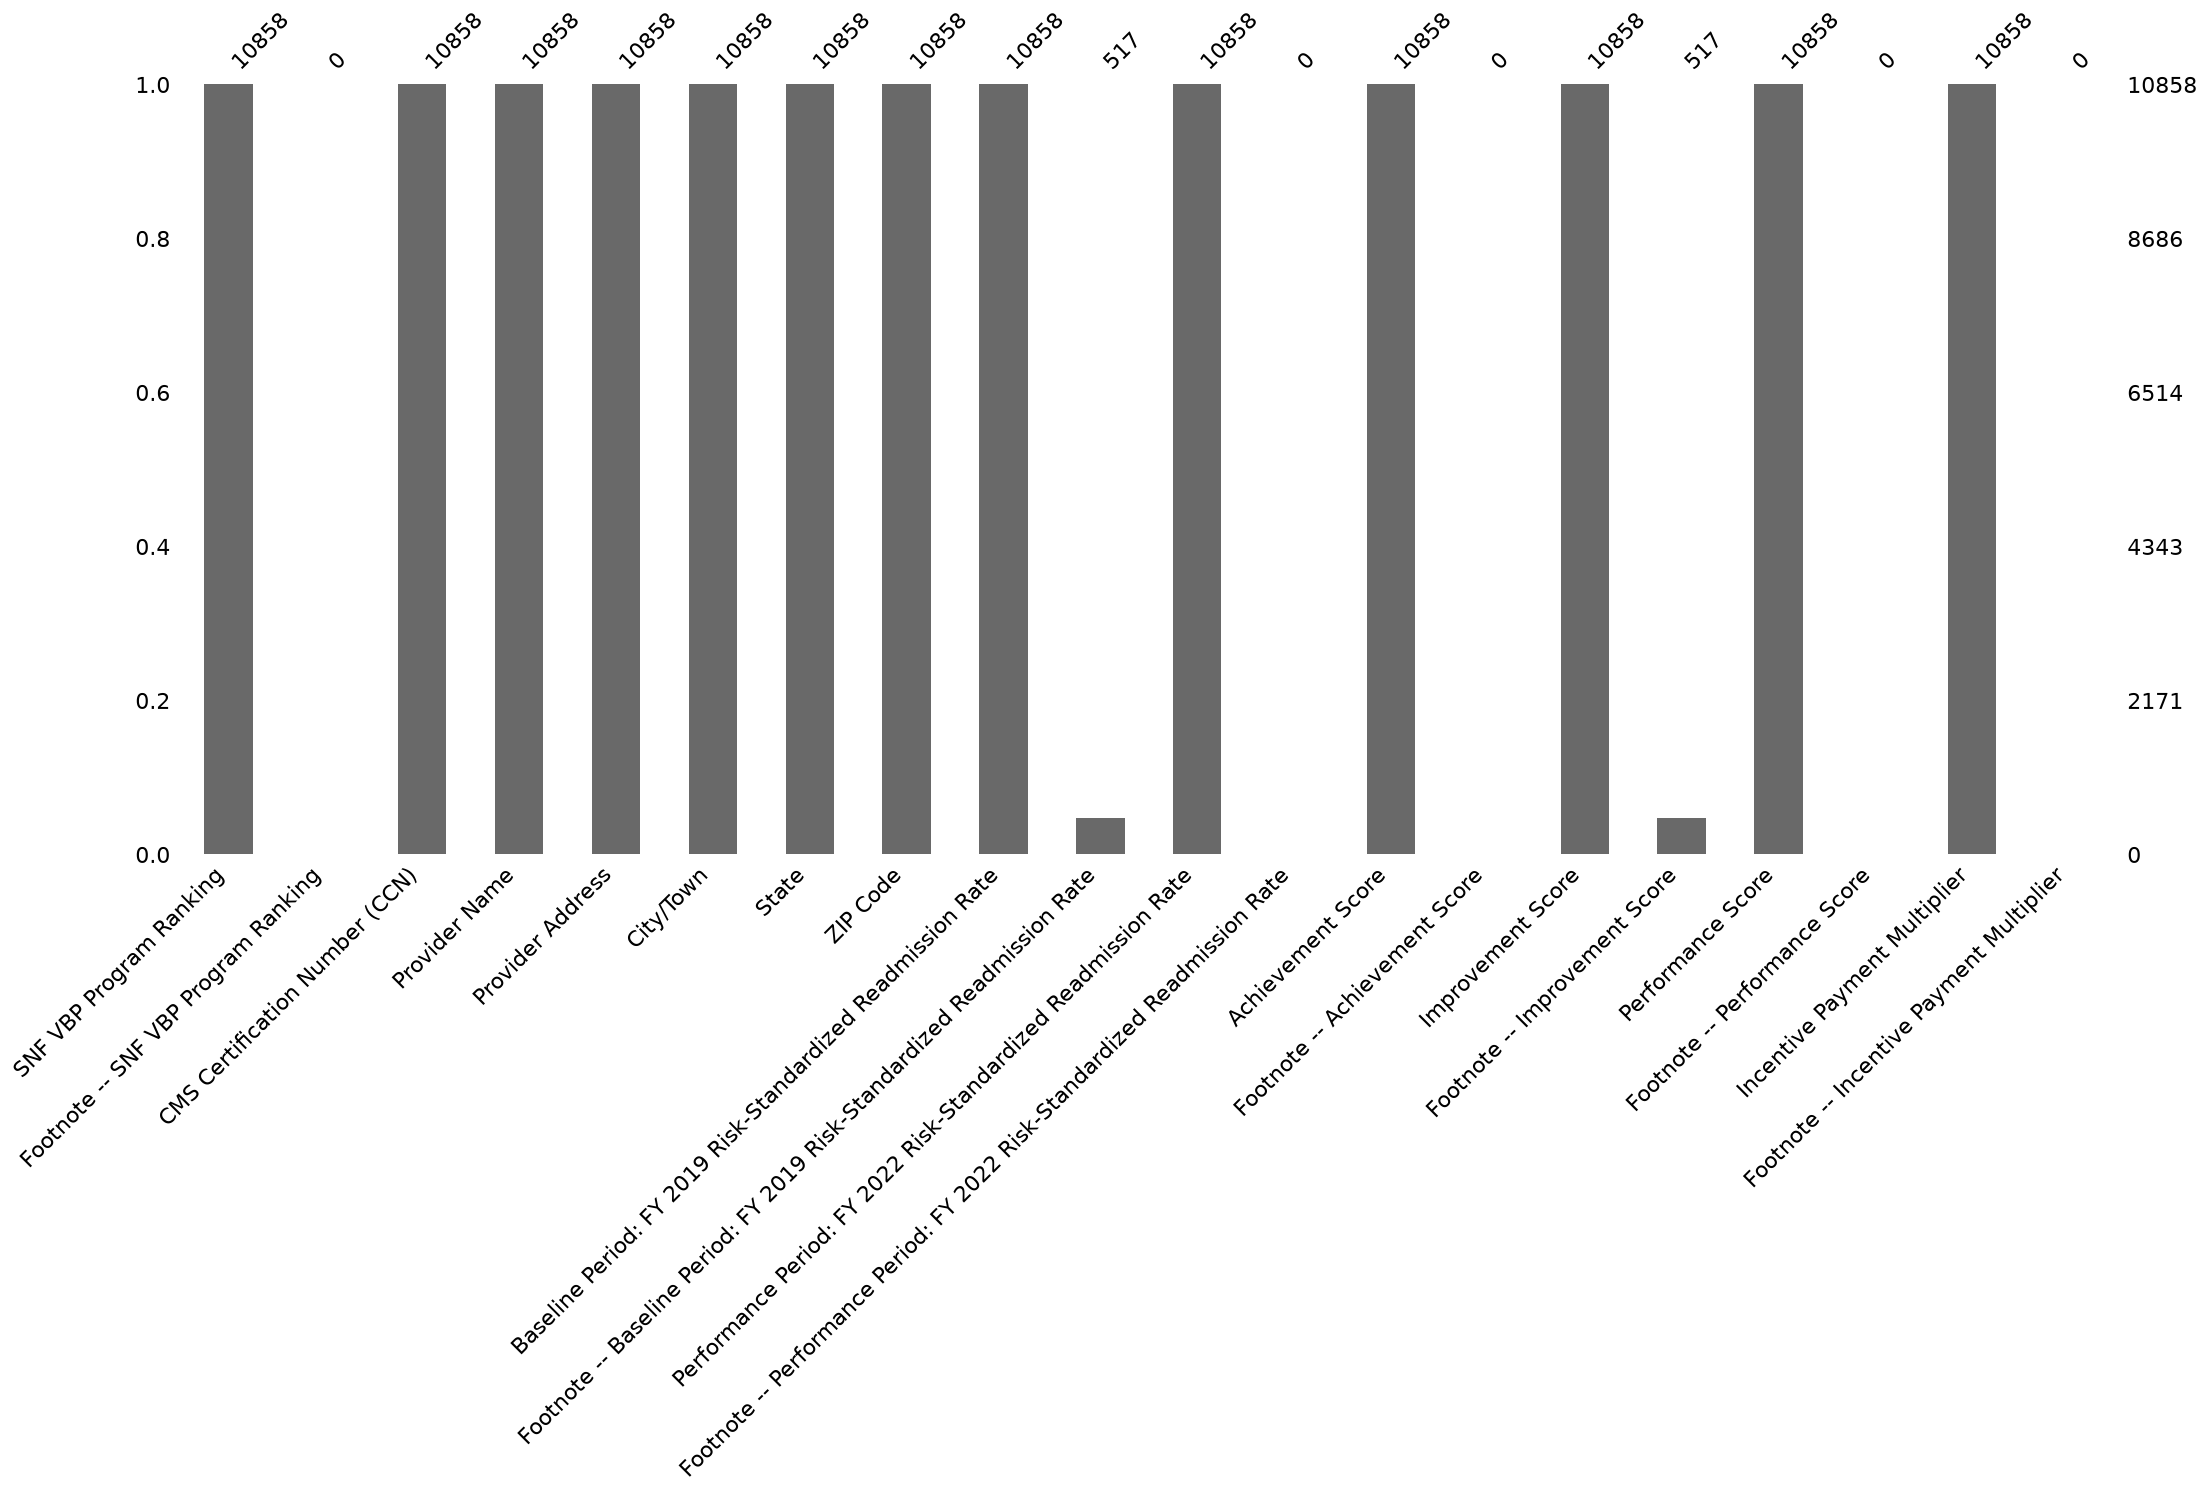

In [56]:
msno.bar(FY_2024_SNF_VBP_Facility_Performance)

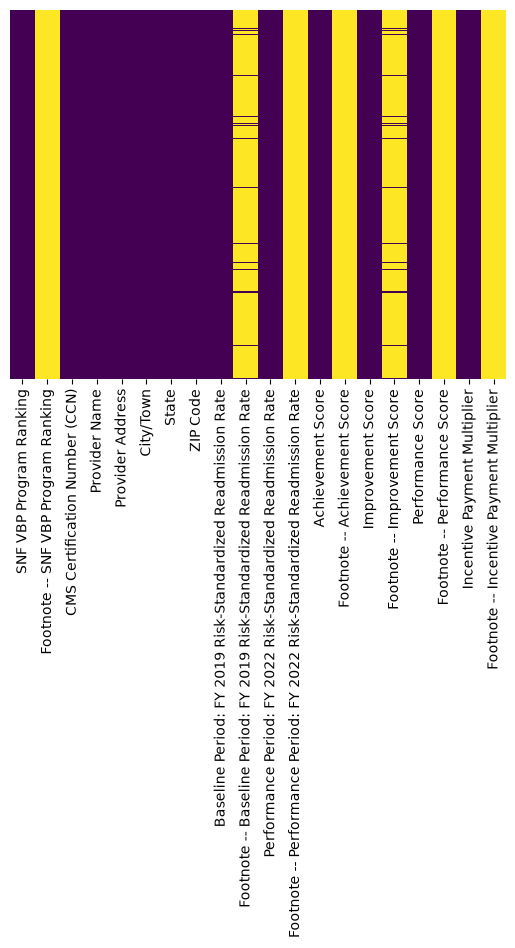

In [57]:
sns.heatmap(FY_2024_SNF_VBP_Facility_Performance.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.show()

In [58]:
# Duplicates
FY_2024_SNF_VBP_Facility_Performance_duplicates = FY_2024_SNF_VBP_Facility_Performance[FY_2024_SNF_VBP_Facility_Performance.duplicated()]
print(FY_2024_SNF_VBP_Facility_Performance_duplicates)

Empty DataFrame
Columns: [SNF VBP Program Ranking, Footnote -- SNF VBP Program Ranking, CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Baseline Period: FY 2019 Risk-Standardized Readmission Rate, Footnote -- Baseline Period: FY 2019 Risk-Standardized Readmission Rate, Performance Period: FY 2022 Risk-Standardized Readmission Rate, Footnote -- Performance Period: FY 2022 Risk-Standardized Readmission Rate, Achievement Score, Footnote -- Achievement Score, Improvement Score, Footnote -- Improvement Score, Performance Score, Footnote -- Performance Score, Incentive Payment Multiplier, Footnote -- Incentive Payment Multiplier]
Index: []


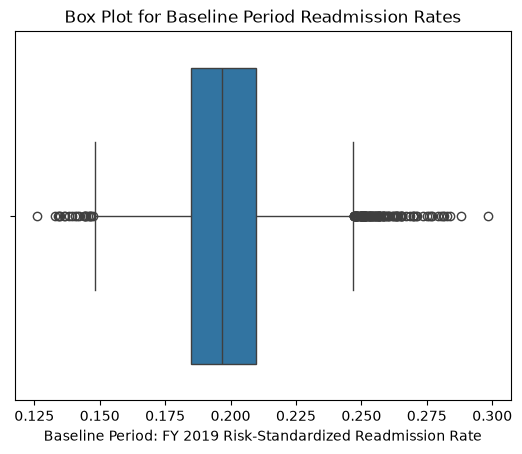

In [59]:
# Outlier Detection: Baseline Period: FY 2019 Risk-Standardized Readmission Rate (unplanned readmissions) Boxplot
FY_2024_SNF_VBP_Facility_Performance_copy = FY_2024_SNF_VBP_Facility_Performance.copy()
FY_2024_SNF_VBP_Facility_Performance_copy['Baseline Period: FY 2019 Risk-Standardized Readmission Rate'] = pd.to_numeric(FY_2024_SNF_VBP_Facility_Performance_copy['Baseline Period: FY 2019 Risk-Standardized Readmission Rate'], errors="coerce")

sns.boxplot(x=FY_2024_SNF_VBP_Facility_Performance_copy['Baseline Period: FY 2019 Risk-Standardized Readmission Rate'])
plt.title("Box Plot for Baseline Period Readmission Rates")
plt.show()

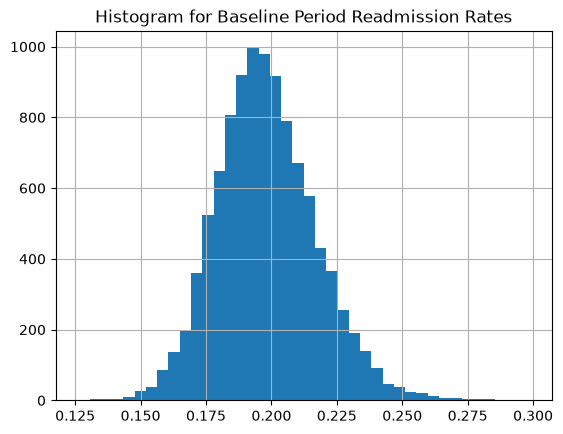

In [60]:
# Outlier Detection: Baseline Period: FY 2019 Risk-Standardized Readmission Rate (unplanned readmissions) Histogram
FY_2024_SNF_VBP_Facility_Performance_copy['Baseline Period: FY 2019 Risk-Standardized Readmission Rate'].hist(bins=40)
plt.title("Histogram for Baseline Period Readmission Rates")
plt.show()

In [61]:
# Outlier Detection: Baseline Period: FY 2019 Risk-Standardized Readmission Rate (unplanned readmissions) Z-Scores
z = np.abs(stats.zscore(FY_2024_SNF_VBP_Facility_Performance_copy['Baseline Period: FY 2019 Risk-Standardized Readmission Rate']))
outliers = FY_2024_SNF_VBP_Facility_Performance_copy[z > 3]

print("Outliers:\n", outliers)

Outliers:
 Empty DataFrame
Columns: [SNF VBP Program Ranking, Footnote -- SNF VBP Program Ranking, CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Baseline Period: FY 2019 Risk-Standardized Readmission Rate, Footnote -- Baseline Period: FY 2019 Risk-Standardized Readmission Rate, Performance Period: FY 2022 Risk-Standardized Readmission Rate, Footnote -- Performance Period: FY 2022 Risk-Standardized Readmission Rate, Achievement Score, Footnote -- Achievement Score, Improvement Score, Footnote -- Improvement Score, Performance Score, Footnote -- Performance Score, Incentive Payment Multiplier, Footnote -- Incentive Payment Multiplier]
Index: []


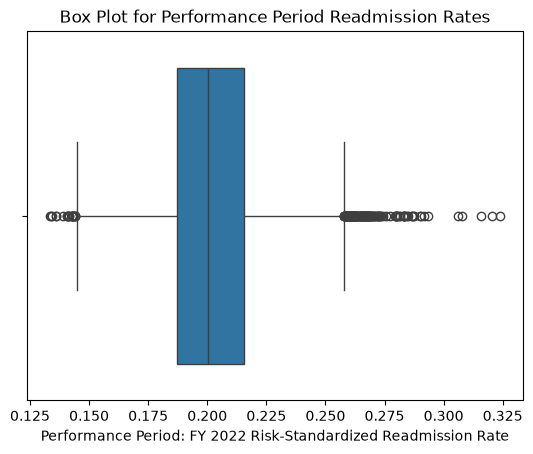

In [62]:
# Outlier Detection: Performance Period: FY 2022 Risk-Standardized Readmission Rate (unplanned readmissions) Boxplot
sns.boxplot(x=FY_2024_SNF_VBP_Facility_Performance['Performance Period: FY 2022 Risk-Standardized Readmission Rate'])
plt.title("Box Plot for Performance Period Readmission Rates")
plt.show()

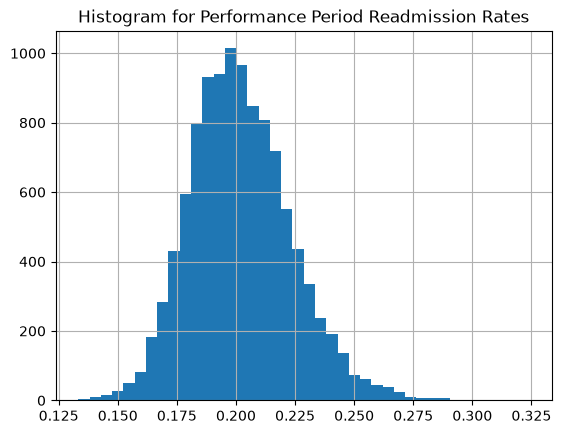

In [63]:
# Outlier Detection: Performance Period: FY 2022 Risk-Standardized Readmission Rate (unplanned readmissions) Histogram
FY_2024_SNF_VBP_Facility_Performance_copy['Performance Period: FY 2022 Risk-Standardized Readmission Rate'].hist(bins=40)
plt.title("Histogram for Performance Period Readmission Rates")
plt.show()

In [64]:
# Outlier Detection: Performance Period: FY 2022 Risk-Standardized Readmission Rate (unplanned readmissions) Z-Scores
z = np.abs(stats.zscore(FY_2024_SNF_VBP_Facility_Performance_copy['Performance Period: FY 2022 Risk-Standardized Readmission Rate']))
outliers = FY_2024_SNF_VBP_Facility_Performance_copy[z > 3]

print("Outliers:\n", outliers.loc[:,['CMS Certification Number (CCN)', 'Performance Period: FY 2022 Risk-Standardized Readmission Rate']])

Outliers:
        CMS Certification Number (CCN)  \
20                              15049   
63                              15155   
196                             35092   
222                             35131   
548                             55276   
578                             55342   
604                             55443   
793                             56065   
798                             56076   
955                             56412   
1060                            65376   
1390                           105300   
1457                           105410   
1588                           105579   
1599                           105596   
1672                           105703   
1696                           105734   
1708                           105755   
1744                           105816   
1758                           105842   
1762                           105851   
1840                           106012   
1886                           106073   
1899 

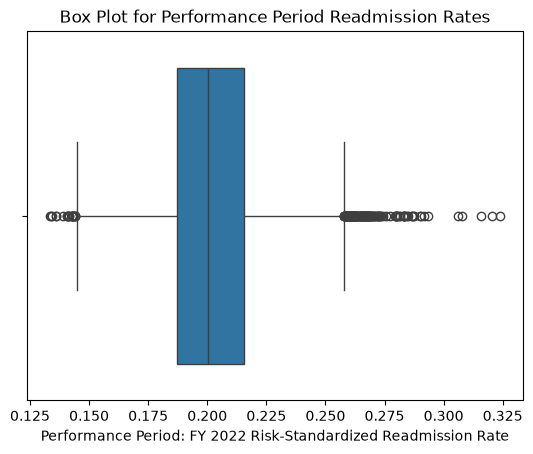

In [65]:
# Outlier Detection: Performance Period: FY 2022 Risk-Standardized Readmission Rate (unplanned readmissions) Boxplot
sns.boxplot(x=FY_2024_SNF_VBP_Facility_Performance['Performance Period: FY 2022 Risk-Standardized Readmission Rate'])
plt.title("Box Plot for Performance Period Readmission Rates")
plt.show()

### Citation Code Look-Up
- Look-up table for nursing home inspection citations.
- Provides text description for each citation or tag code.

In [66]:
NH_CitationDescriptions_Oct2024.head()

,Deficiency Prefix,Deficiency Tag Number,Deficiency Prefix and Number,Deficiency Description,Deficiency Category
0,E,1,E-0001,Establish an Emergency Preparedness Program (EP).,Emergency Preparedness Deficiencies
1,E,4,E-0004,Develop and maintain an Emergency Preparedness Program (EP).,Emergency Preparedness Deficiencies
2,E,6,E-0006,Conduct risk assessment and an All-Hazards approach.,Emergency Preparedness Deficiencies
3,E,7,E-0007,Address patient/client population and determine types of services needed.,Emergency Preparedness Deficiencies
4,E,9,E-0009,Include a process for Emergency Preparedness collaboration.,Emergency Preparedness Deficiencies


In [67]:
NH_CitationDescriptions_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 641 entries, 0 to 640
Data columns (total 5 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Deficiency Prefix             641 non-null    str  
 1   Deficiency Tag Number         641 non-null    int64
 2   Deficiency Prefix and Number  641 non-null    str  
 3   Deficiency Description        641 non-null    str  
 4   Deficiency Category           641 non-null    str  
dtypes: int64(1), str(4)
memory usage: 106.7 KB


<Axes: >

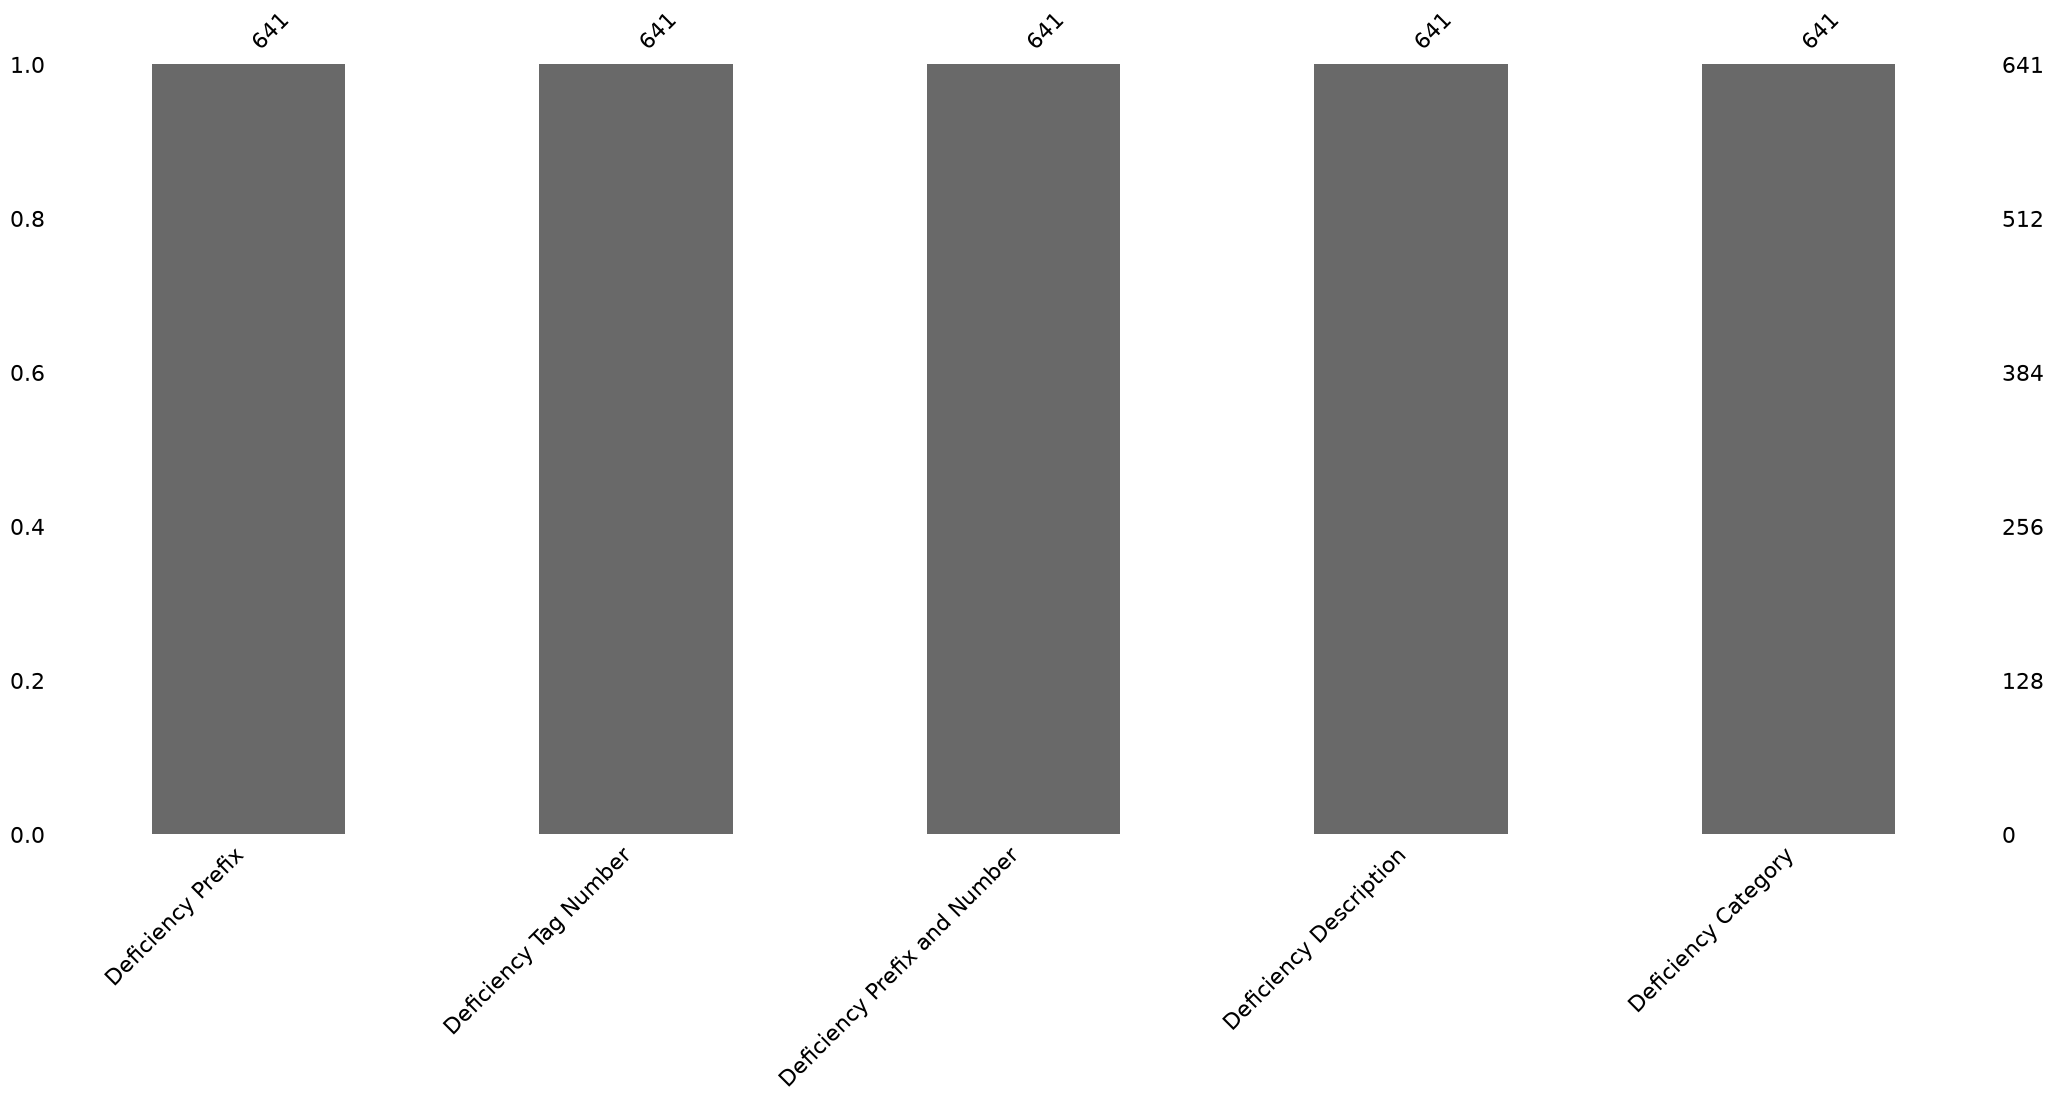

In [68]:
# Null Values
msno.bar(NH_CitationDescriptions_Oct2024)

In [69]:
# Duplicates
NH_CitationDescriptions_Oct2024_duplicates = NH_CitationDescriptions_Oct2024[NH_CitationDescriptions_Oct2024.duplicated()]
print(NH_CitationDescriptions_Oct2024_duplicates)

Empty DataFrame
Columns: [Deficiency Prefix, Deficiency Tag Number, Deficiency Prefix and Number, Deficiency Description, Deficiency Category]
Index: []


### COVID-19 Vaccination Rates - State and National Averages
- State and National averages for facility resident and healthcare personnel COVID-19 vaccination rates.
- One row per state/territory plus a row for national averages.

In [70]:
NH_CovidVaxAverages_20241027.head()

,State,Percent of residents who are up-to-date on their vaccines,Percent of staff who are up-to-date on their vaccines,Date vaccination data last updated
0,US,23.7,5.9,10/27/2024
1,AK,42.5,5.0,10/27/2024
2,AL,20.9,2.6,10/27/2024
3,AR,10.9,3.2,10/27/2024
4,AZ,19.8,6.1,10/27/2024


In [71]:
NH_CovidVaxAverages_20241027.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 4 columns):
 #   Column                                                     Non-Null Count  Dtype  
---  ------                                                     --------------  -----  
 0   State                                                      54 non-null     str    
 1   Percent of residents who are up-to-date on their vaccines  54 non-null     float64
 2   Percent of staff who are up-to-date on their vaccines      54 non-null     float64
 3   Date vaccination data last updated                         54 non-null     str    
dtypes: float64(2), str(2)
memory usage: 2.4 KB


<Axes: >

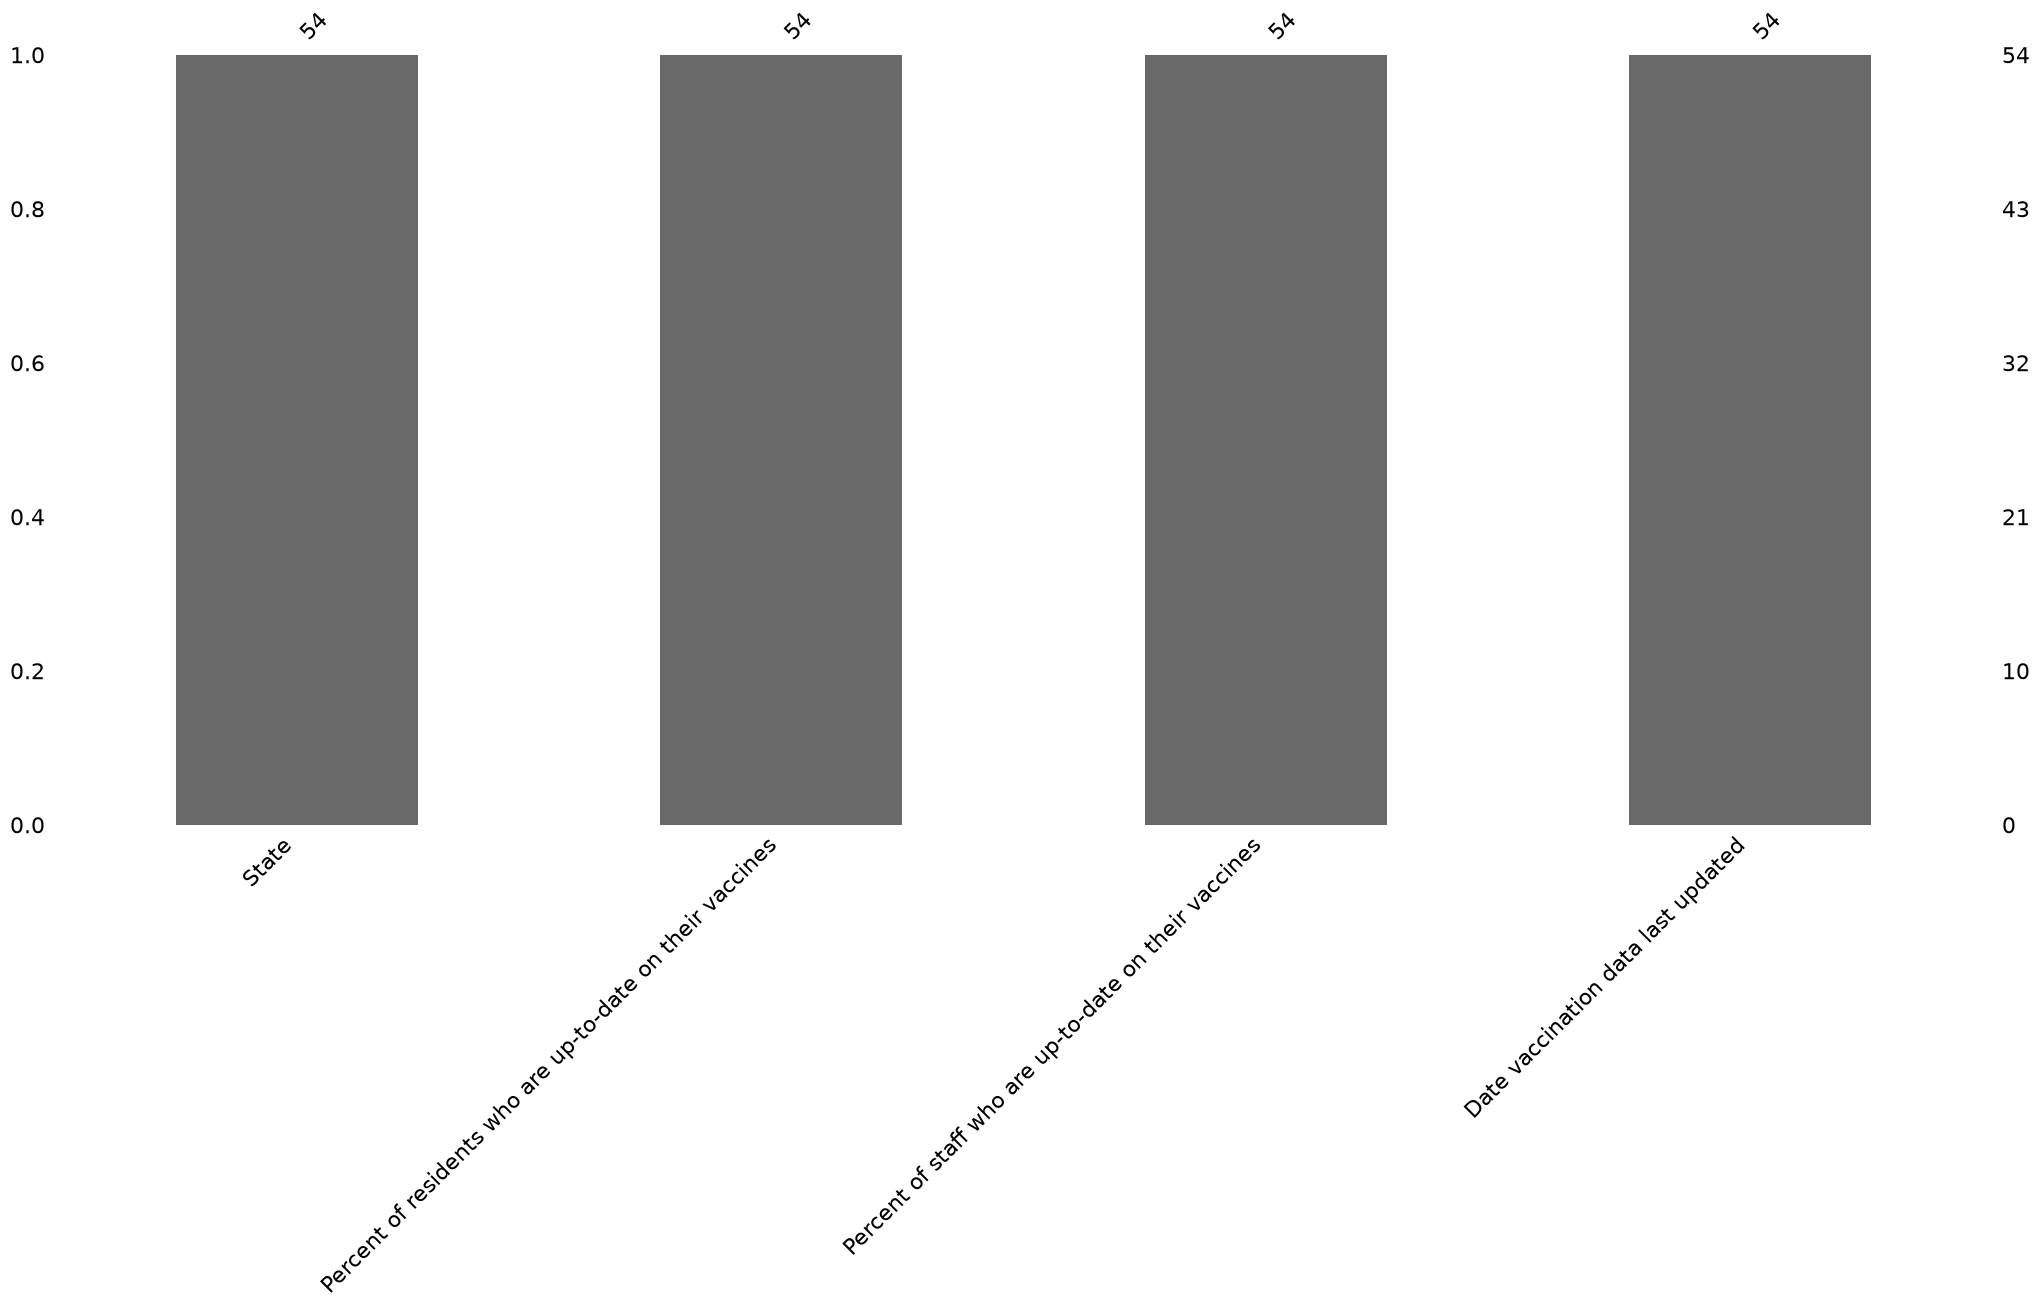

In [72]:
# Null Values
msno.bar(NH_CovidVaxAverages_20241027)

In [73]:
# Duplicates
NH_CovidVaxAverages_20241027_duplicates = NH_CovidVaxAverages_20241027[NH_CovidVaxAverages_20241027.duplicated()]
print(NH_CovidVaxAverages_20241027_duplicates)

Empty DataFrame
Columns: [State, Percent of residents who are up-to-date on their vaccines, Percent of staff who are up-to-date on their vaccines, Date vaccination data last updated]
Index: []


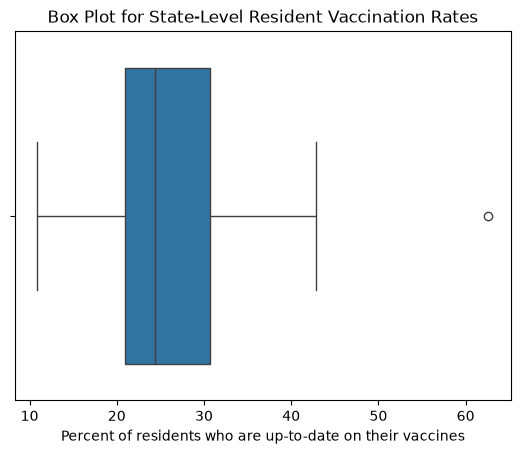

In [74]:
# Outlier Detection: Percent of residents who are up-to-date on their vaccines Boxplot
sns.boxplot(x=NH_CovidVaxAverages_20241027['Percent of residents who are up-to-date on their vaccines'])
plt.title("Box Plot for State-Level Resident Vaccination Rates")
plt.show()

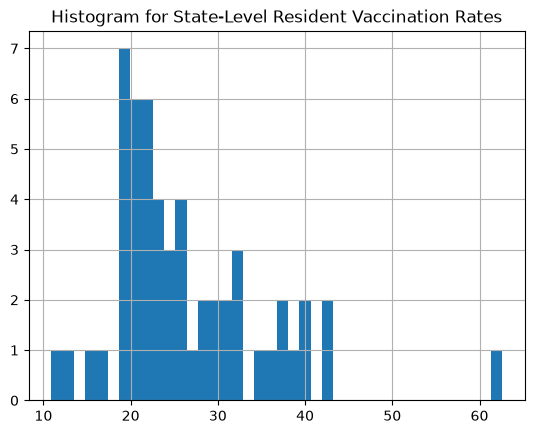

In [75]:
# Outlier Detection: Percent of residents who are up-to-date on their vaccines Histogram
NH_CovidVaxAverages_20241027['Percent of residents who are up-to-date on their vaccines'].hist(bins=40)
plt.title("Histogram for State-Level Resident Vaccination Rates")
plt.show()

In [76]:
# Outlier Detection: Percent of residents who are up-to-date on their vaccines Z-Scores
z = np.abs(stats.zscore(NH_CovidVaxAverages_20241027['Percent of residents who are up-to-date on their vaccines']))
outliers = NH_CovidVaxAverages_20241027[z > 3]

print("Outliers:\n", outliers.loc[:,['State', 'Percent of residents who are up-to-date on their vaccines']])

Outliers:
   State  Percent of residents who are up-to-date on their vaccines
8    DC                                                       62.6


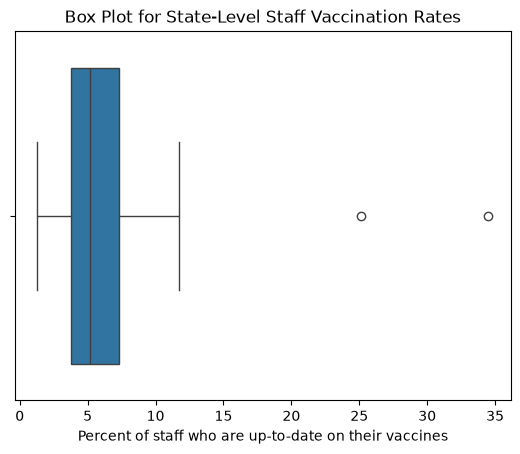

In [77]:
# Outlier Detection: Percent of staff who are up-to-date on their vaccines Boxplot
sns.boxplot(x=NH_CovidVaxAverages_20241027['Percent of staff who are up-to-date on their vaccines'])
plt.title("Box Plot for State-Level Staff Vaccination Rates")
plt.show()

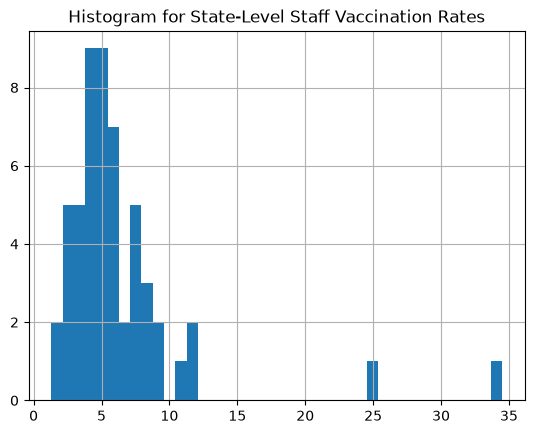

In [78]:
# Outlier Detection: Percent of staff who are up-to-date on their vaccines Histogram
NH_CovidVaxAverages_20241027['Percent of staff who are up-to-date on their vaccines'].hist(bins=40)
plt.title("Histogram for State-Level Staff Vaccination Rates")
plt.show()

In [79]:
# Outlier Detection: Percent of staff who are up-to-date on their vaccines Z-Scores
z = np.abs(stats.zscore(NH_CovidVaxAverages_20241027['Percent of staff who are up-to-date on their vaccines']))
outliers = NH_CovidVaxAverages_20241027[z > 3]

print("Outliers:\n", outliers.loc[:,['State', 'Percent of staff who are up-to-date on their vaccines']])

Outliers:
    State  Percent of staff who are up-to-date on their vaccines
8     DC                                                   34.5
41    PR                                                   25.1


### COVID-19 Vaccination Rates - Provider Data
- Current resident and healthcare personnel COVID-19 vaccination rates.
- One row per provider.

In [80]:
NH_CovidVaxProvider_20241027.head()

,CMS Certification Number (CCN),State,Percent of residents who are up-to-date on their vaccines,Percent of staff who are up-to-date on their vaccines,Date vaccination data last updated
0,015009,AL,3.8,12.3,10/27/2024
1,015010,AL,0.0,0.0,10/27/2024
2,015012,AL,37.0,0.0,10/27/2024
3,015014,AL,Not Available,Not Available,10/27/2024
4,015015,AL,65.6,0.0,10/27/2024


In [81]:
NH_CovidVaxProvider_20241027.info()

<class 'pandas.DataFrame'>
RangeIndex: 14814 entries, 0 to 14813
Data columns (total 5 columns):
 #   Column                                                     Non-Null Count  Dtype
---  ------                                                     --------------  -----
 0   CMS Certification Number (CCN)                             14814 non-null  str  
 1   State                                                      14814 non-null  str  
 2   Percent of residents who are up-to-date on their vaccines  14814 non-null  str  
 3   Percent of staff who are up-to-date on their vaccines      14814 non-null  str  
 4   Date vaccination data last updated                         14814 non-null  str  
dtypes: str(5)
memory usage: 954.0 KB


<Axes: >

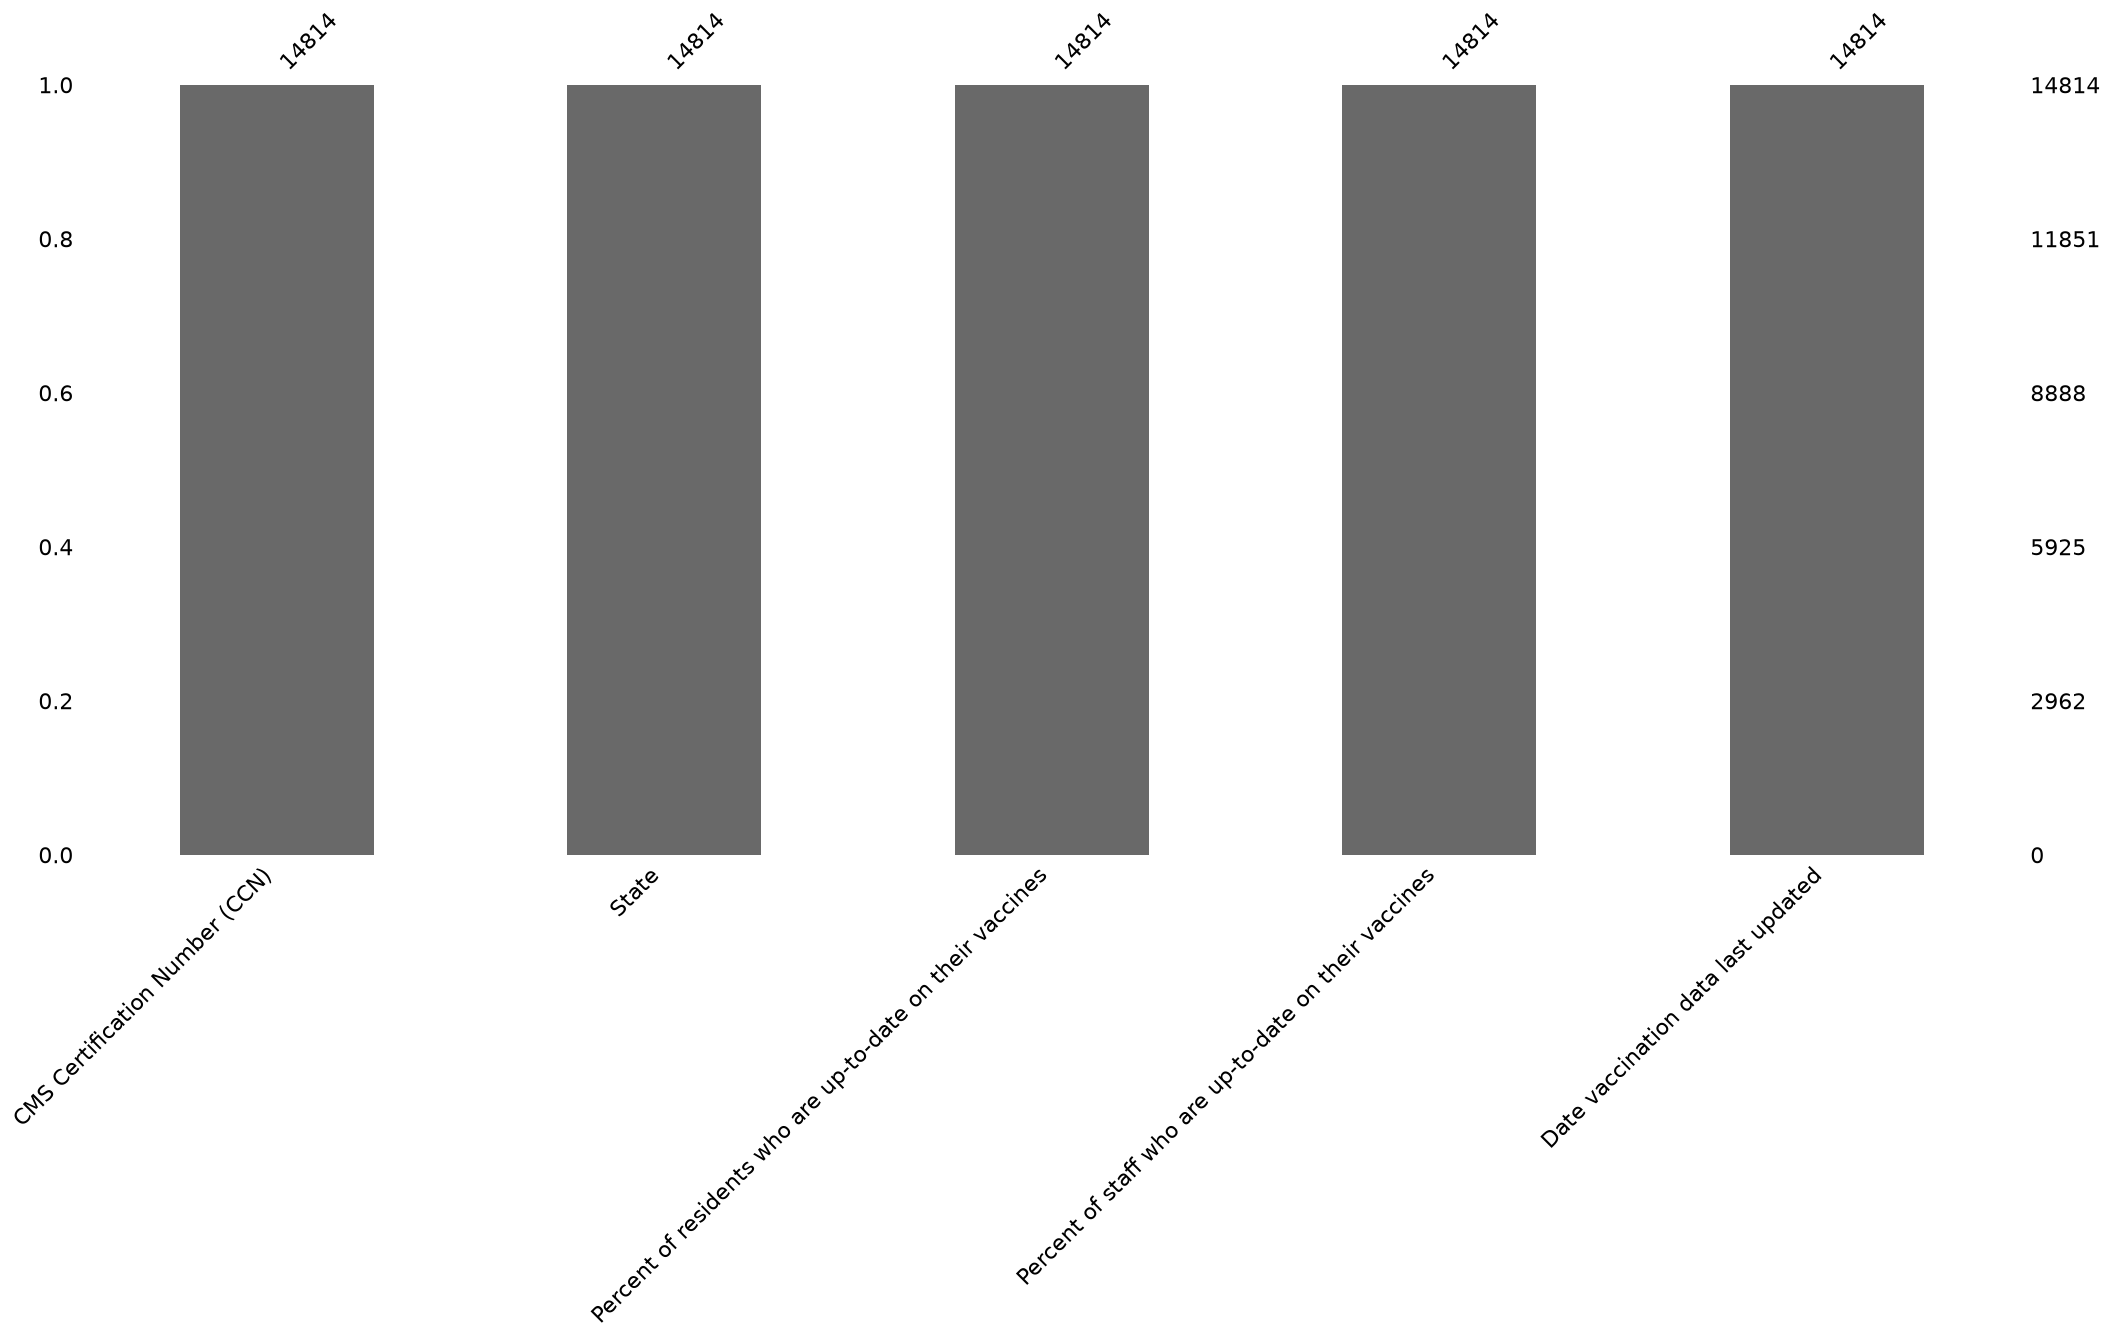

In [82]:
# Null Values (does not count 'Not Available' values)
msno.bar(NH_CovidVaxProvider_20241027)

In [83]:
# Duplicates
NH_CovidVaxProvider_20241027_duplicates = NH_CovidVaxProvider_20241027[NH_CovidVaxProvider_20241027.duplicated()]
print(NH_CovidVaxProvider_20241027_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), State, Percent of residents who are up-to-date on their vaccines, Percent of staff who are up-to-date on their vaccines, Date vaccination data last updated]
Index: []


#### Handling 'Not Available' Null Values

In [84]:
# How many 'Not Available' values exist in the Resident Vaccination Rates?
NH_CovidVaxProvider_20241027['Percent of residents who are up-to-date on their vaccines'].value_counts()

Percent of residents who are up-to-date on their vaccines
0.0              4935
Not Available    1041
50.0              108
0.9                81
1.1                79
1.3                72
0.8                68
1.6                59
66.7               58
1.5                58
1.0                57
1.7                57
1.8                56
1.4                56
1.9                50
1.2                48
33.3               46
0.7                45
100.0              45
2.4                43
2.1                42
2.0                41
2.5                38
60.0               36
2.2                36
40.0               35
0.6                34
2.6                34
2.7                33
2.8                32
2.3                32
3.4                31
3.2                30
4.3                30
2.9                27
57.1               27
44.4               26
75.0               26
42.9               25
25.0               25
45.5               25
3.7                25
3.1               

In [85]:
# Any non-numeric string will become NaN
CovidVaxProvider_copy = NH_CovidVaxProvider_20241027.copy()
CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'] = CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'].replace("Not Available", np.nan)
print(CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'].head(10))

0     3.8
1     0.0
2    37.0
3     NaN
4    65.6
5     NaN
6     1.0
7    32.2
8    13.6
9     NaN
Name: Percent of residents who are up-to-date on their vaccines, dtype: str


In [86]:
# Bin Resident Vaccine Rates into Quartiles
bins = [0.0, 25.0, 50.0, 75.0, 100.0]
labels = ['Very Low (0.0-25.0)', 'Low (25.1-50.0)', 'Medium (50.1-75.0)', 'High (75.1-100.0)']

CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'] = pd.to_numeric(CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'], errors="coerce")

CovidVaxProvider_copy['Resident_Vaccine_Ranges'] = pd.cut(
    CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'],
    bins=bins,
    labels=labels,
    include_lowest=True
).astype(str)

resident_counts = CovidVaxProvider_copy['Resident_Vaccine_Ranges'].value_counts().reset_index()
resident_counts.columns = ['Range', 'Row_Count']
print(resident_counts)

                 Range  Row_Count
0  Very Low (0.0-25.0)       8299
1      Low (25.1-50.0)       2428
2   Medium (50.1-75.0)       2314
3    High (75.1-100.0)        732


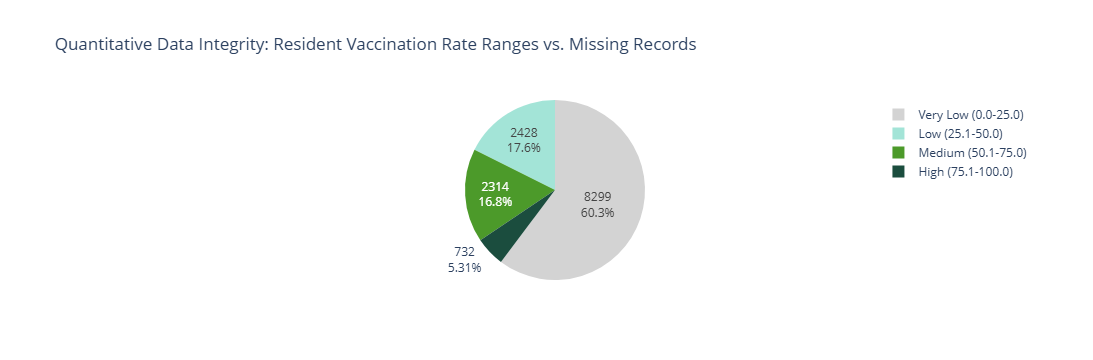

In [87]:
color_map = {
    'High (75.1-100.0)': '#1B4D3E',   # Dark Green
    'Medium (50.1-75.0)': '#4C9A2A', # Medium Green
    'Low (25.1-50.0)': '#A3E4D7', # Light Green
    'Very Low (0.0-25.0)': '#D3D3D3', # Neutral Muted Gray
    'nan': '#050505' # Gray
}

fig = px.pie(
    resident_counts,
    values='Row_Count',
    names='Range',
    color='Range',
    color_discrete_map=color_map,
    title='Quantitative Data Integrity: Resident Vaccination Rate Ranges vs. Missing Records'
)

fig.update_traces(textinfo='value+percent')
fig.show()

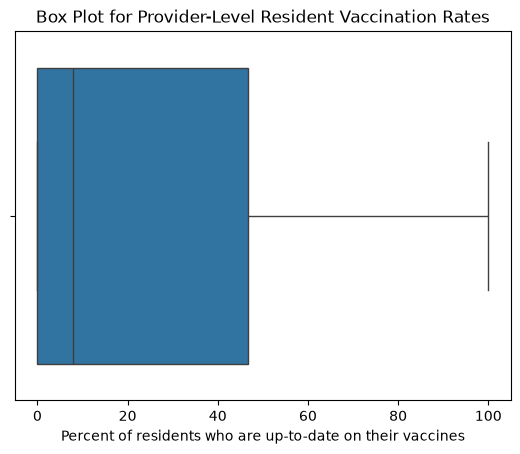

In [88]:
# Outlier Detection: Percent of residents who are up-to-date on their vaccines Boxplot
sns.boxplot(x=CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'])
plt.title("Box Plot for Provider-Level Resident Vaccination Rates")
plt.show()

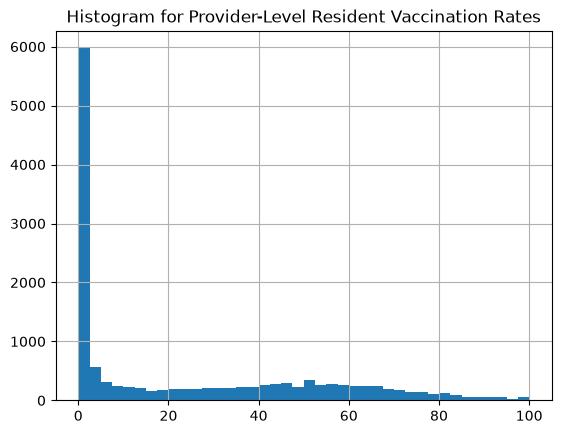

In [89]:
# Outlier Detection: Percent of residents who are up-to-date on their vaccines Histogram
CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines'].hist(bins=40)
plt.title("Histogram for Provider-Level Resident Vaccination Rates")
plt.show()

In [90]:
# Outlier Detection: Percent of residents who are up-to-date on their vaccines Z-Scores
z = np.abs(stats.zscore(CovidVaxProvider_copy['Percent of residents who are up-to-date on their vaccines']))
outliers = CovidVaxProvider_copy[z > 3]

print("Outliers:\n", outliers.loc[:,['CMS Certification Number (CCN)','State','Percent of residents who are up-to-date on their vaccines']])

Outliers:
 Empty DataFrame
Columns: [CMS Certification Number (CCN), State, Percent of residents who are up-to-date on their vaccines]
Index: []


In [91]:
# How many 'Not Available' values exist in the Staff Vaccination Rates?
NH_CovidVaxProvider_20241027['Percent of staff who are up-to-date on their vaccines'].value_counts()

Percent of staff who are up-to-date on their vaccines
0.0              7025
Not Available     962
0.7               176
1.1               163
0.8               155
0.9               153
1.4               152
0.6               151
1.0               145
1.2               145
0.5               139
1.3               137
1.7               109
0.4               109
1.5               103
1.6               103
2.1               101
2.2                96
1.9                92
2.0                89
1.8                89
100.0              88
2.4                78
2.6                76
2.7                68
3.0                68
2.5                67
2.9                60
3.4                58
0.3                58
3.8                55
2.8                55
3.1                55
3.3                54
4.3                54
3.2                51
4.0                48
2.3                46
3.6                46
4.2                43
3.9                43
4.1                43
5.7                42


In [92]:
# Any non-numeric string will become NaN
CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'] = CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'].replace("Not Available", np.nan)
print(CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'].head(10))

0    12.3
1     0.0
2     0.0
3     NaN
4     0.0
5     NaN
6    11.1
7     0.0
8     0.0
9     NaN
Name: Percent of staff who are up-to-date on their vaccines, dtype: str


In [93]:
# Bin Staff Vaccine Rates into Quartiles
bins = [0.0, 25.0, 50.0, 75.0, 100.0]
labels = ['Very Low (0.0-25.0)', 'Low (25.1-50.0)', 'Medium (50.1-75.0)', 'High (75.1-100.0)']

CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'] = pd.to_numeric(CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'], errors="coerce")

CovidVaxProvider_copy['Staff_Vaccine_Ranges'] = pd.cut(
    CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'],
    bins=bins,
    labels=labels,
    include_lowest=True
).astype(str)

staff_counts = CovidVaxProvider_copy['Staff_Vaccine_Ranges'].value_counts().reset_index()
staff_counts.columns = ['Range', 'Row_Count']
print(staff_counts)

                 Range  Row_Count
0  Very Low (0.0-25.0)      13062
1      Low (25.1-50.0)        330
2    High (75.1-100.0)        304
3   Medium (50.1-75.0)        156


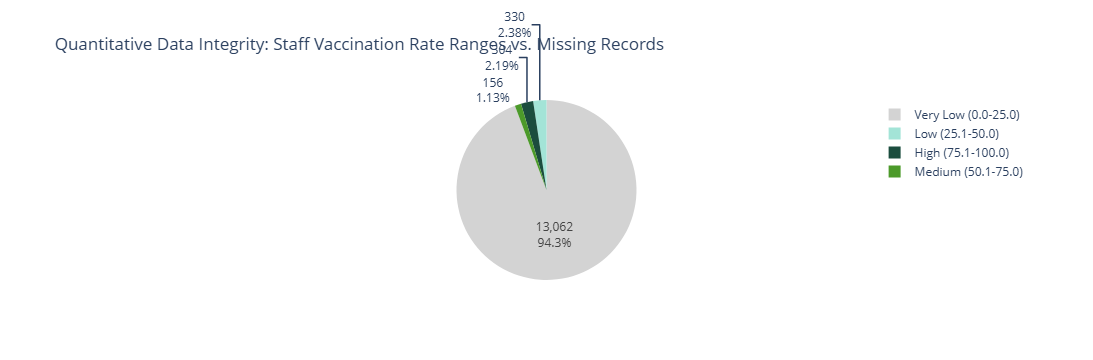

In [94]:
color_map = {
    'High (75.1-100.0)': '#1B4D3E',   # Dark Green
    'Medium (50.1-75.0)': '#4C9A2A', # Medium Green
    'Low (25.1-50.0)': '#A3E4D7', # Light Green
    'Very Low (0.0-25.0)': '#D3D3D3', # Neutral Muted Gray
    'nan': '#050505' # Gray
}

fig = px.pie(
    staff_counts,
    values='Row_Count',
    names='Range',
    color='Range',
    color_discrete_map=color_map,
    title='Quantitative Data Integrity: Staff Vaccination Rate Ranges vs. Missing Records'
)

fig.update_traces(textinfo='value+percent')
fig.show()

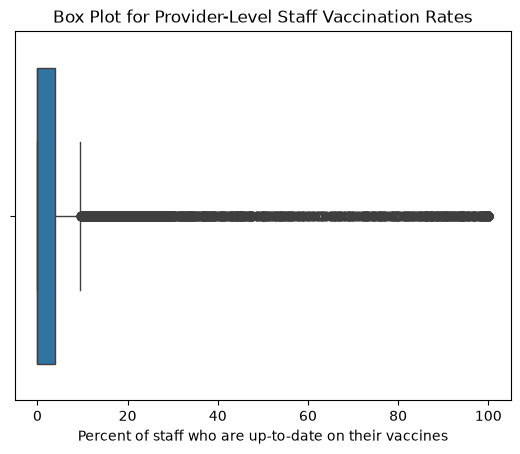

In [95]:
# Outlier Detection: Percent of staff who are up-to-date on their vaccines Boxplot
sns.boxplot(x=CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'])
plt.title("Box Plot for Provider-Level Staff Vaccination Rates")
plt.show()

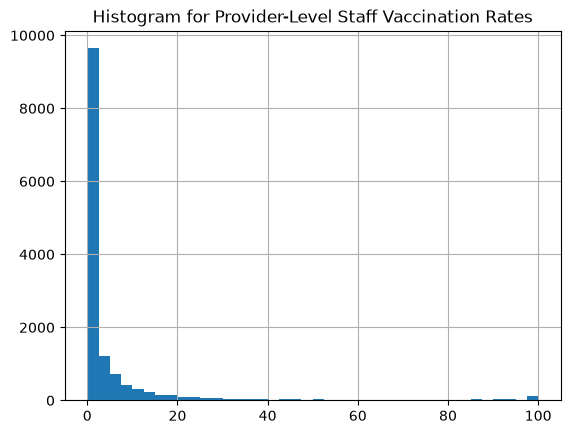

In [96]:
# Outlier Detection: Percent of staff who are up-to-date on their vaccines Histogram
CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines'].hist(bins=40)
plt.title("Histogram for Provider-Level Staff Vaccination Rates")
plt.show()

In [97]:
# Outlier Detection: Percent of staff who are up-to-date on their vaccines Z-Scores
z = np.abs(stats.zscore(CovidVaxProvider_copy['Percent of staff who are up-to-date on their vaccines']))
outliers = CovidVaxProvider_copy[z > 3]

print("Outliers:\n", outliers.loc[:,['CMS Certification Number (CCN)','State','Percent of staff who are up-to-date on their vaccines']])

Outliers:
 Empty DataFrame
Columns: [CMS Certification Number (CCN), State, Percent of staff who are up-to-date on their vaccines]
Index: []


<Axes: >

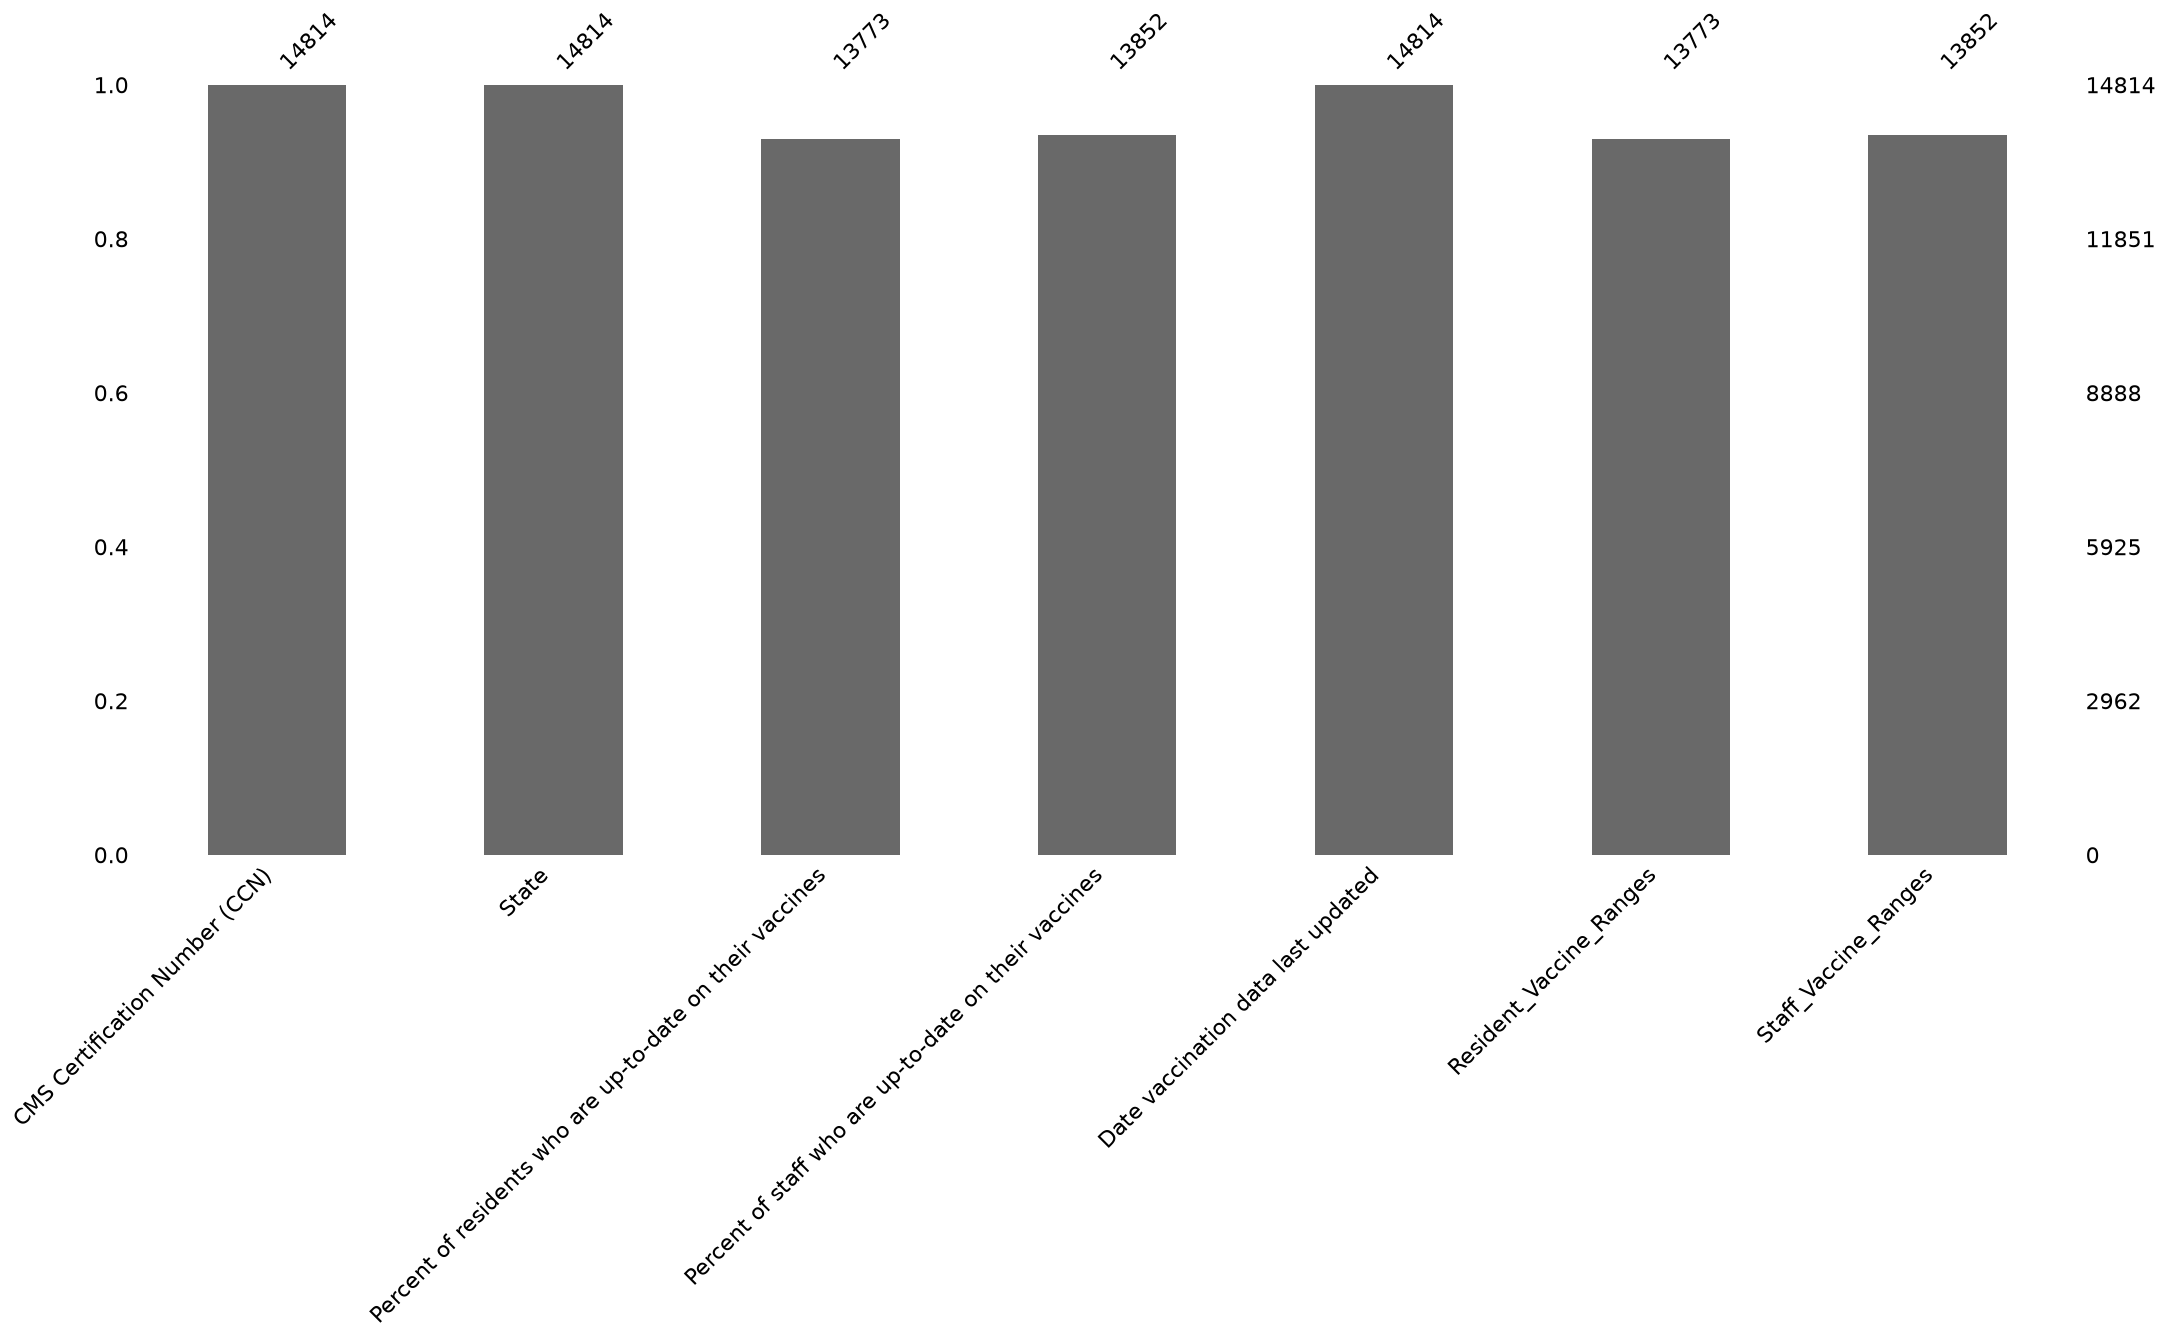

In [98]:
# Final updated non-null value counts
msno.bar(CovidVaxProvider_copy)

### Nursing Home Data Collection Intervals
- Lists data collection periods for the quality measures displayed for nursing homes.
    - Includes Rehab Services and intervals for complaint citations on focused infection control inspections.
    - Also includes the data collection period for the nursing home staffing measures.
- Note: The data collection periods for some short-stay measures differ slightly from the measure periods in the MDS Quality Measure file due to the look-back periods for these measures.

In [99]:
NH_DataCollectionIntervals_Oct2024.head(45)

,Measure Code,Measure Description,Data Collection Period From Date,Data Collection Period Through Date,Measure Date Range,Processing Date
0,004,Rate of potentially preventable hospital readmissions 30 days after discharge from a SNF,10/01/2021,09/30/2023,NaN,20241001
1,005,Rate of successful return to home or community from a SNF,10/01/2021,09/30/2023,NaN,20241001
2,006,Medicare spending per beneficiary (MSPB) for residents in SNFs,10/01/2021,09/30/2023,NaN,20241001
3,007,Percentage of SNF residents whose medications were reviewed and who received follow-up care when medication issues were identified,01/01/2023,12/31/2023,NaN,20241001
4,013,Percentage of SNF residents who experience one or more falls with major injury during their SNF stay,01/01/2023,12/31/2023,NaN,20241001
5,024,Percentage of SNF residents who achieve or exceed a self-care ability expected for their condition at discharge,01/01/2023,12/31/2023,NaN,20241001
6,025,Percentage of SNF residents who achieve or exceed the level of movement expected for their condition at discharge,01/01/2023,12/31/2023,NaN,20241001
7,038,Percentage of residents with pressure ulcers/injuries that are new or worsened,01/01/2023,12/31/2023,NaN,20241001
8,039,Rate of healthcare associated infections acquired during the SNF stay that resulted in hospitalization,10/01/2022,09/30/2023,NaN,20241001
9,040,Percentage of healthcare workers vaccinated for COVID-19,10/01/2023,12/31/2023,NaN,20241001


In [100]:
NH_DataCollectionIntervals_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Measure Code                         45 non-null     str    
 1   Measure Description                  45 non-null     str    
 2   Data Collection Period From Date     45 non-null     str    
 3   Data Collection Period Through Date  45 non-null     str    
 4   Measure Date Range                   0 non-null      float64
 5   Processing Date                      45 non-null     int64  
dtypes: float64(1), int64(1), str(4)
memory usage: 7.0 KB


<Axes: >

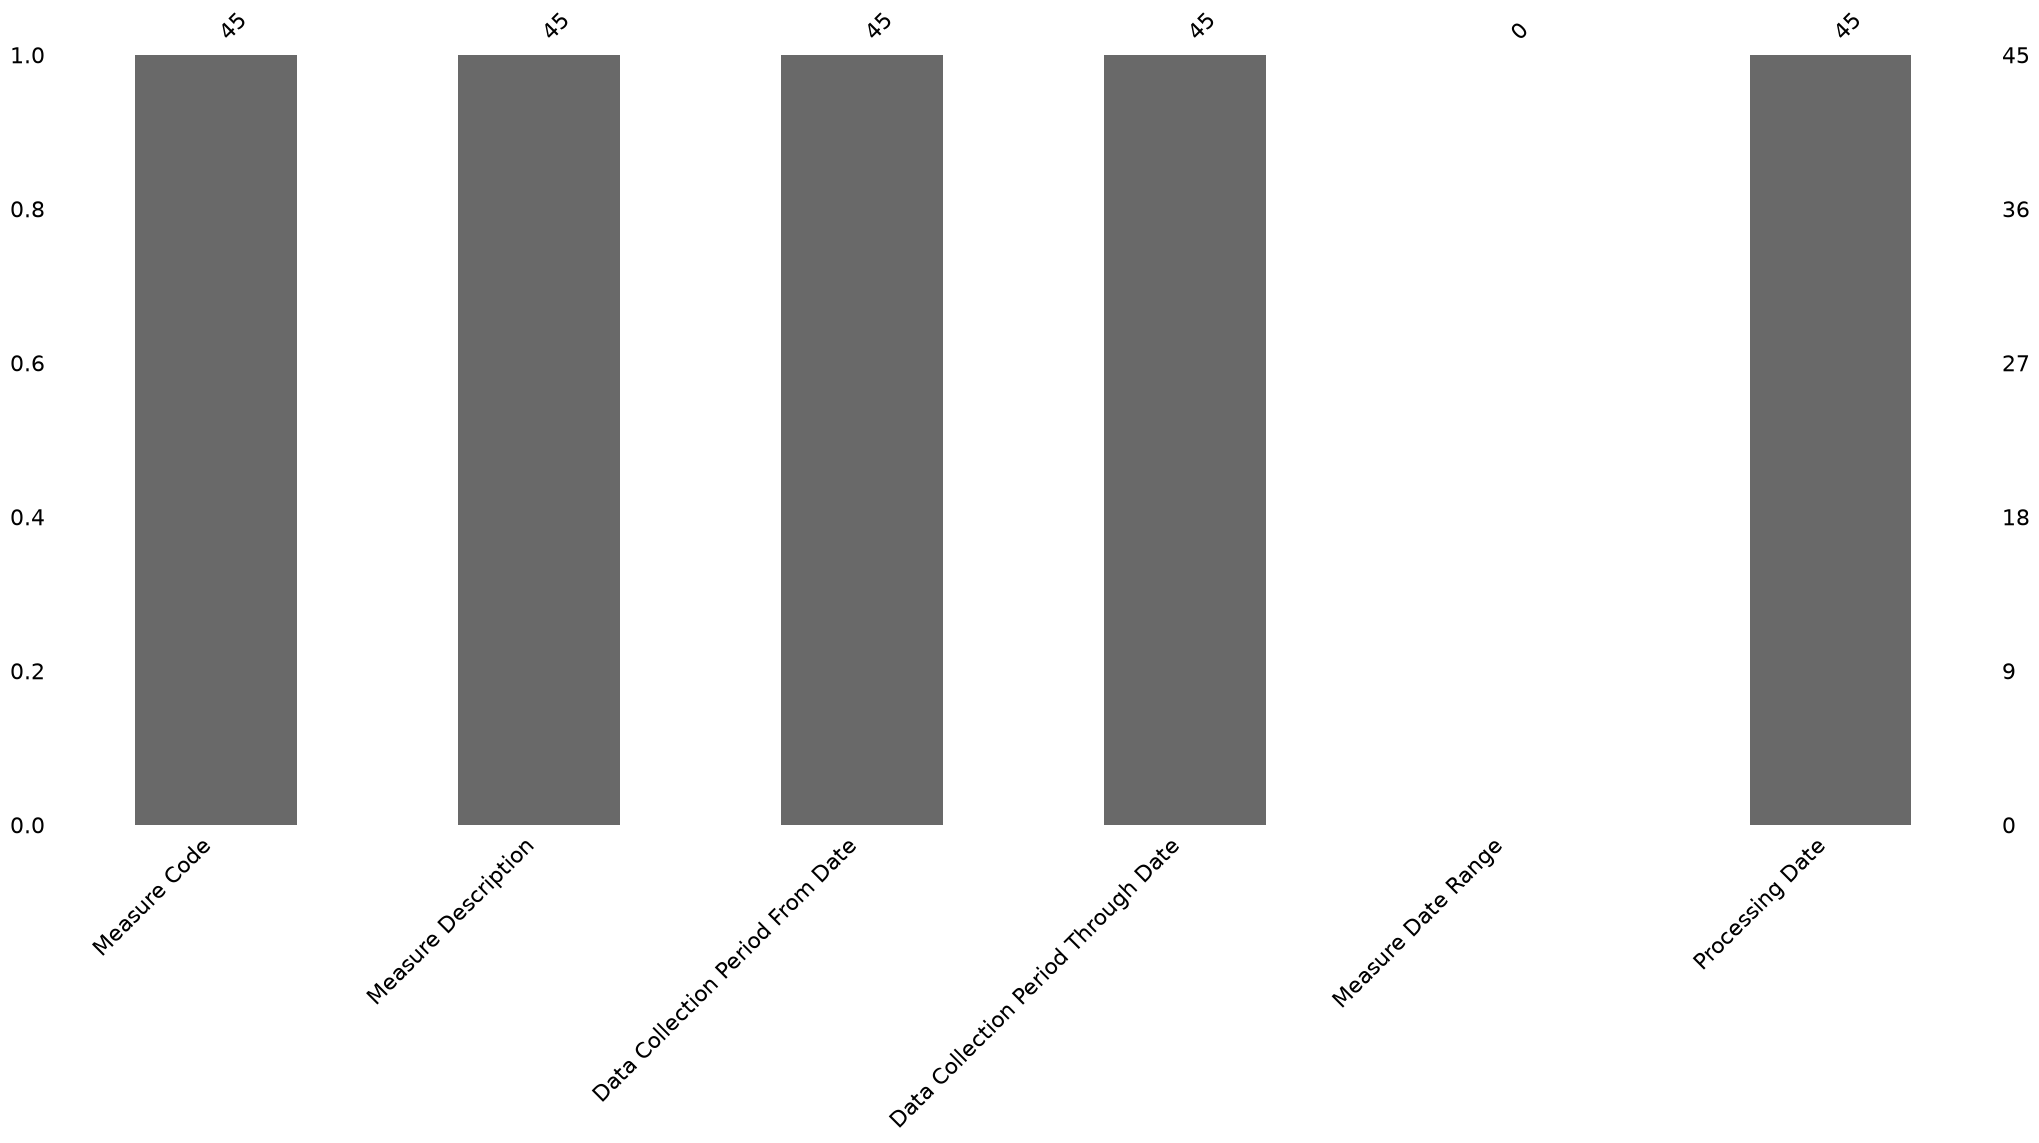

In [101]:
# Null Values
msno.bar(NH_DataCollectionIntervals_Oct2024)

In [102]:
# Duplicates
NH_DataCollectionIntervals_Oct2024_duplicates = NH_DataCollectionIntervals_Oct2024[NH_DataCollectionIntervals_Oct2024.duplicated()]
print(NH_DataCollectionIntervals_Oct2024_duplicates)

Empty DataFrame
Columns: [Measure Code, Measure Description, Data Collection Period From Date, Data Collection Period Through Date, Measure Date Range, Processing Date]
Index: []


### Fire Safety Deficiencies
- Nursing home fire safety citations in the last three years.
    - Includes nursing homes that received the citation, associated inspection date, citation tag number & description, scope and severity, current status, and correction date.
- One citation per row.

In [103]:
NH_FireSafetyCitations_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Survey Date,Survey Type,Deficiency Prefix,Deficiency Category,Deficiency Tag Number,Tag Version,Deficiency Description,Scope Severity Code,Deficiency Corrected,Correction Date,Inspection Cycle,Standard Deficiency,Complaint Deficiency,Infection Control Inspection Deficiency,Citation under IDR,Citation under IIDR,Location,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-02-15,Fire Safety,K,Egress Deficiencies,226,New,Have horizontal exits used in accordance with safety requirements.,E,"Deficient, Provider has date of correction",2023-02-16,1,Y,N,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
1,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-02-15,Fire Safety,K,Smoke Deficiencies,324,New,Provide properly protected cooking facilities.,D,"Deficient, Provider has date of correction",2023-02-16,1,Y,N,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
2,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-02-15,Fire Safety,K,Smoke Deficiencies,345,New,"Have approved installation, maintenance and testing program for fire alarm systems.",F,"Deficient, Provider has date of correction",2023-02-25,1,Y,N,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
3,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-02-15,Fire Safety,K,Smoke Deficiencies,353,New,"Inspect, test, and maintain automatic sprinkler systems.",E,"Deficient, Provider has date of correction",2023-03-22,1,Y,N,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
4,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-02-15,Fire Safety,K,Smoke Deficiencies,374,New,Install smoke barrier doors that can resist smoke for at least 20 minutes.,E,"Deficient, Provider has date of correction",2023-02-22,1,Y,N,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01


In [104]:
NH_FireSafetyCitations_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 200003 entries, 0 to 200002
Data columns (total 24 columns):
 #   Column                                   Non-Null Count   Dtype 
---  ------                                   --------------   ----- 
 0   CMS Certification Number (CCN)           200003 non-null  object
 1   Provider Name                            200003 non-null  str   
 2   Provider Address                         200003 non-null  str   
 3   City/Town                                200003 non-null  str   
 4   State                                    200003 non-null  str   
 5   ZIP Code                                 200003 non-null  int64 
 6   Survey Date                              200003 non-null  str   
 7   Survey Type                              200003 non-null  str   
 8   Deficiency Prefix                        200003 non-null  str   
 9   Deficiency Category                      200003 non-null  str   
 10  Deficiency Tag Number                    200003 non-nul

<Axes: >

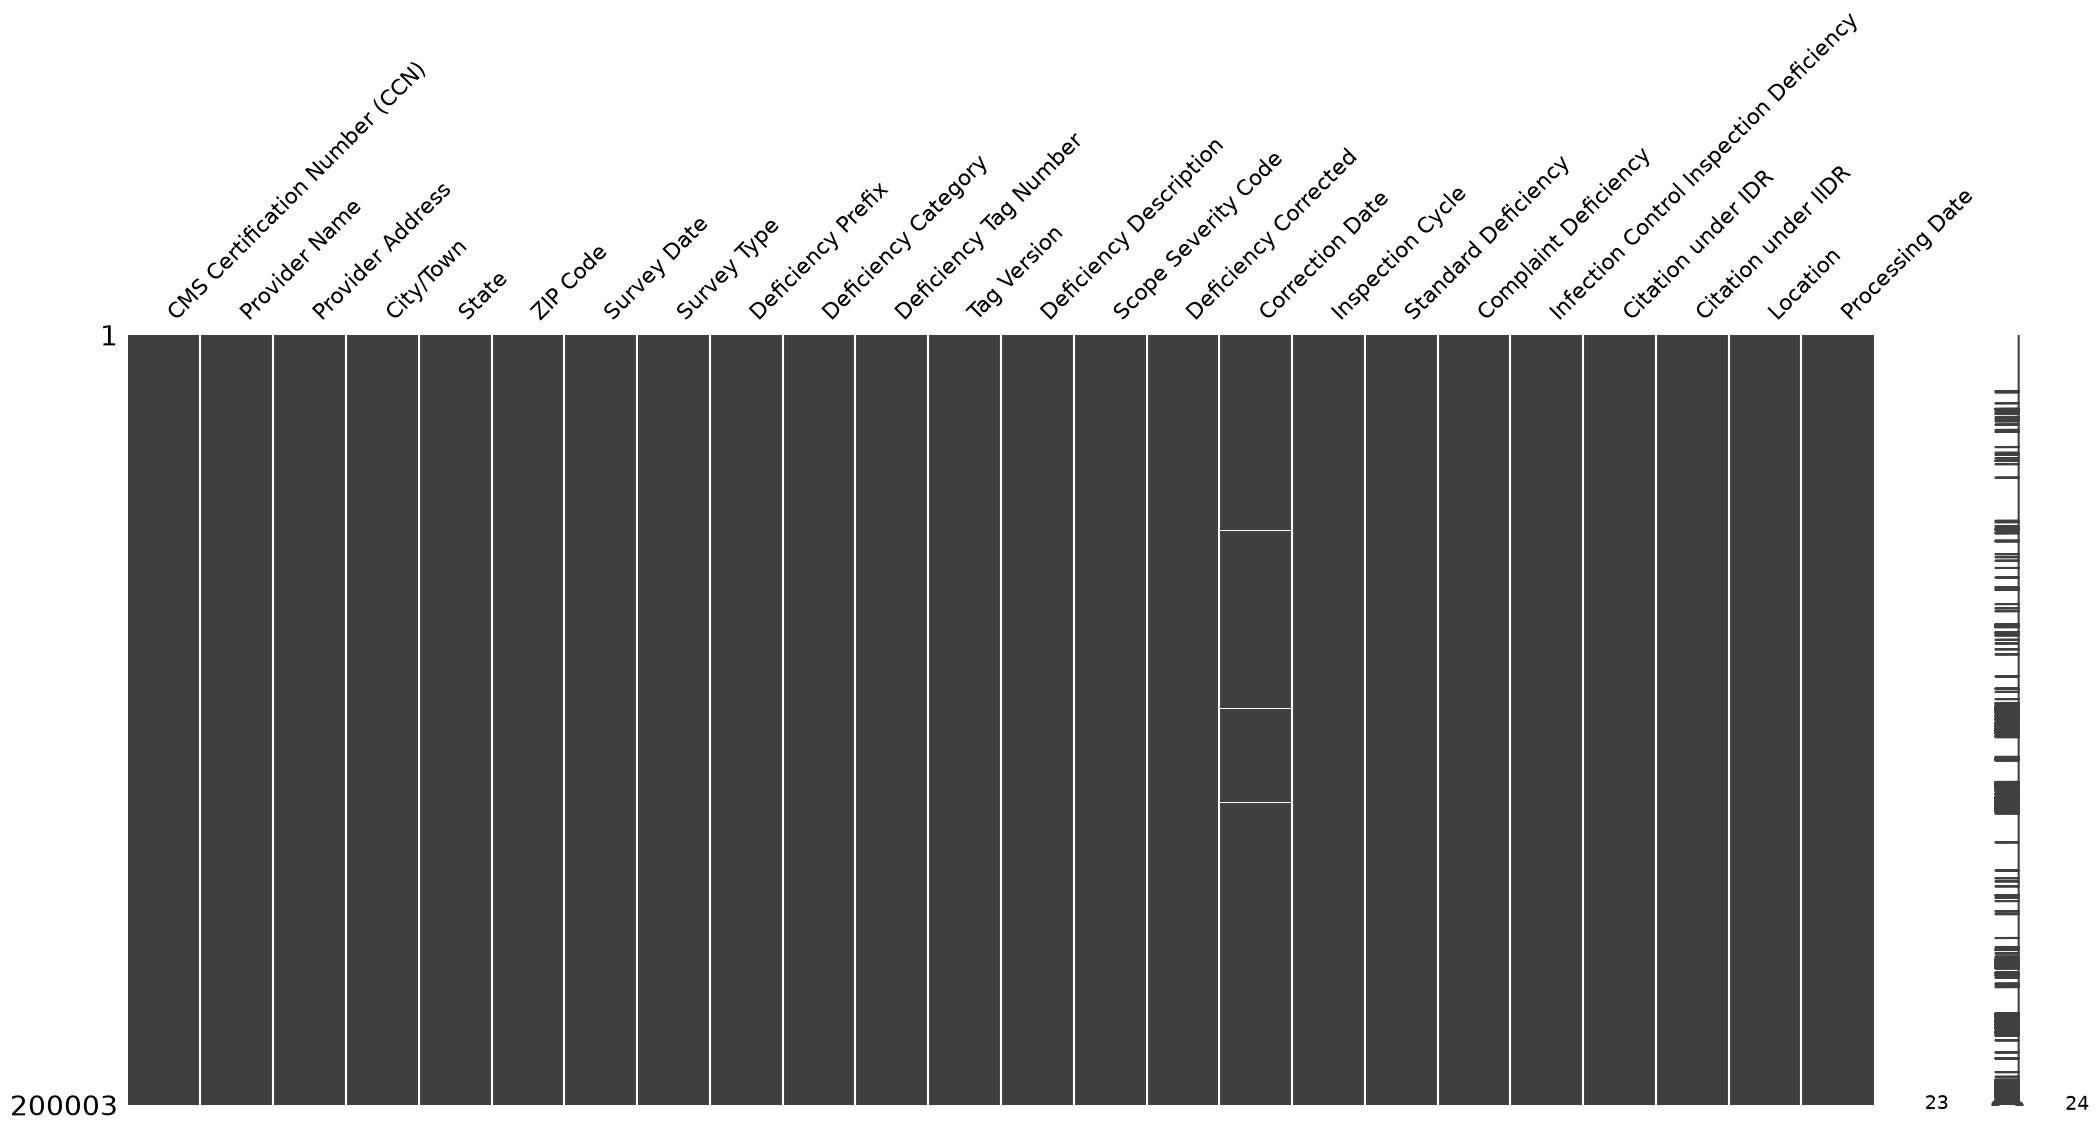

In [105]:
# Null Values
msno.matrix(NH_FireSafetyCitations_Oct2024)

In [106]:
# Duplicates
NH_FireSafetyCitations_Oct2024_duplicates = NH_FireSafetyCitations_Oct2024[NH_FireSafetyCitations_Oct2024.duplicated()]
print(NH_FireSafetyCitations_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Survey Date, Survey Type, Deficiency Prefix, Deficiency Category, Deficiency Tag Number, Tag Version, Deficiency Description, Scope Severity Code, Deficiency Corrected, Correction Date, Inspection Cycle, Standard Deficiency, Complaint Deficiency, Infection Control Inspection Deficiency, Citation under IDR, Citation under IIDR, Location, Processing Date]
Index: []


### Health Deficiencies
- Nursing home health citations in the last three years.
    - Includes nursing home that received the citation, associated inspection date, citation tag number & description, scope and severity, current status, and correction date.
- One citation per row.

In [107]:
NH_HealthCitations_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Survey Date,Survey Type,Deficiency Prefix,Deficiency Category,Deficiency Tag Number,Deficiency Description,Scope Severity Code,Deficiency Corrected,Correction Date,Inspection Cycle,Standard Deficiency,Complaint Deficiency,Infection Control Inspection Deficiency,Citation under IDR,Citation under IIDR,Location,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-03-02,Health,F,Infection Control Deficiencies,880,Provide and implement an infection prevention and control program.,F,"Deficient, Provider has date of correction",2023-04-06,1,Y,N,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
1,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-03-02,Health,F,Resident Assessment and Care Planning Deficiencies,656,"Develop and implement a complete care plan that meets all the resident's needs, with timetables and actions that can be measured.",J,Past Non-Compliance,2023-01-13,1,Y,Y,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
2,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-03-02,Health,F,Quality of Life and Care Deficiencies,689,Ensure that a nursing home area is free from accident hazards and provides adequate supervision to prevent accidents.,J,Past Non-Compliance,2023-01-13,1,Y,Y,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
3,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-03-02,Health,F,Administration Deficiencies,851,"Electronically submit to CMS complete and accurate direct care staffing information, based on payroll and other verifiable and auditable data.",C,"Deficient, Provider has date of correction",2023-03-17,1,Y,Y,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
4,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2019-08-21,Health,F,Resident Rights Deficiencies,554,Allow residents to self-administer drugs if determined clinically appropriate.,D,"Deficient, Provider has date of correction",2019-09-16,2,Y,N,N,N,N,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01


In [108]:
NH_HealthCitations_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 402424 entries, 0 to 402423
Data columns (total 23 columns):
 #   Column                                   Non-Null Count   Dtype 
---  ------                                   --------------   ----- 
 0   CMS Certification Number (CCN)           402424 non-null  object
 1   Provider Name                            402424 non-null  str   
 2   Provider Address                         402424 non-null  str   
 3   City/Town                                402424 non-null  str   
 4   State                                    402424 non-null  str   
 5   ZIP Code                                 402424 non-null  int64 
 6   Survey Date                              402424 non-null  str   
 7   Survey Type                              402424 non-null  str   
 8   Deficiency Prefix                        402424 non-null  str   
 9   Deficiency Category                      402424 non-null  str   
 10  Deficiency Tag Number                    402424 non-nul

<Axes: >

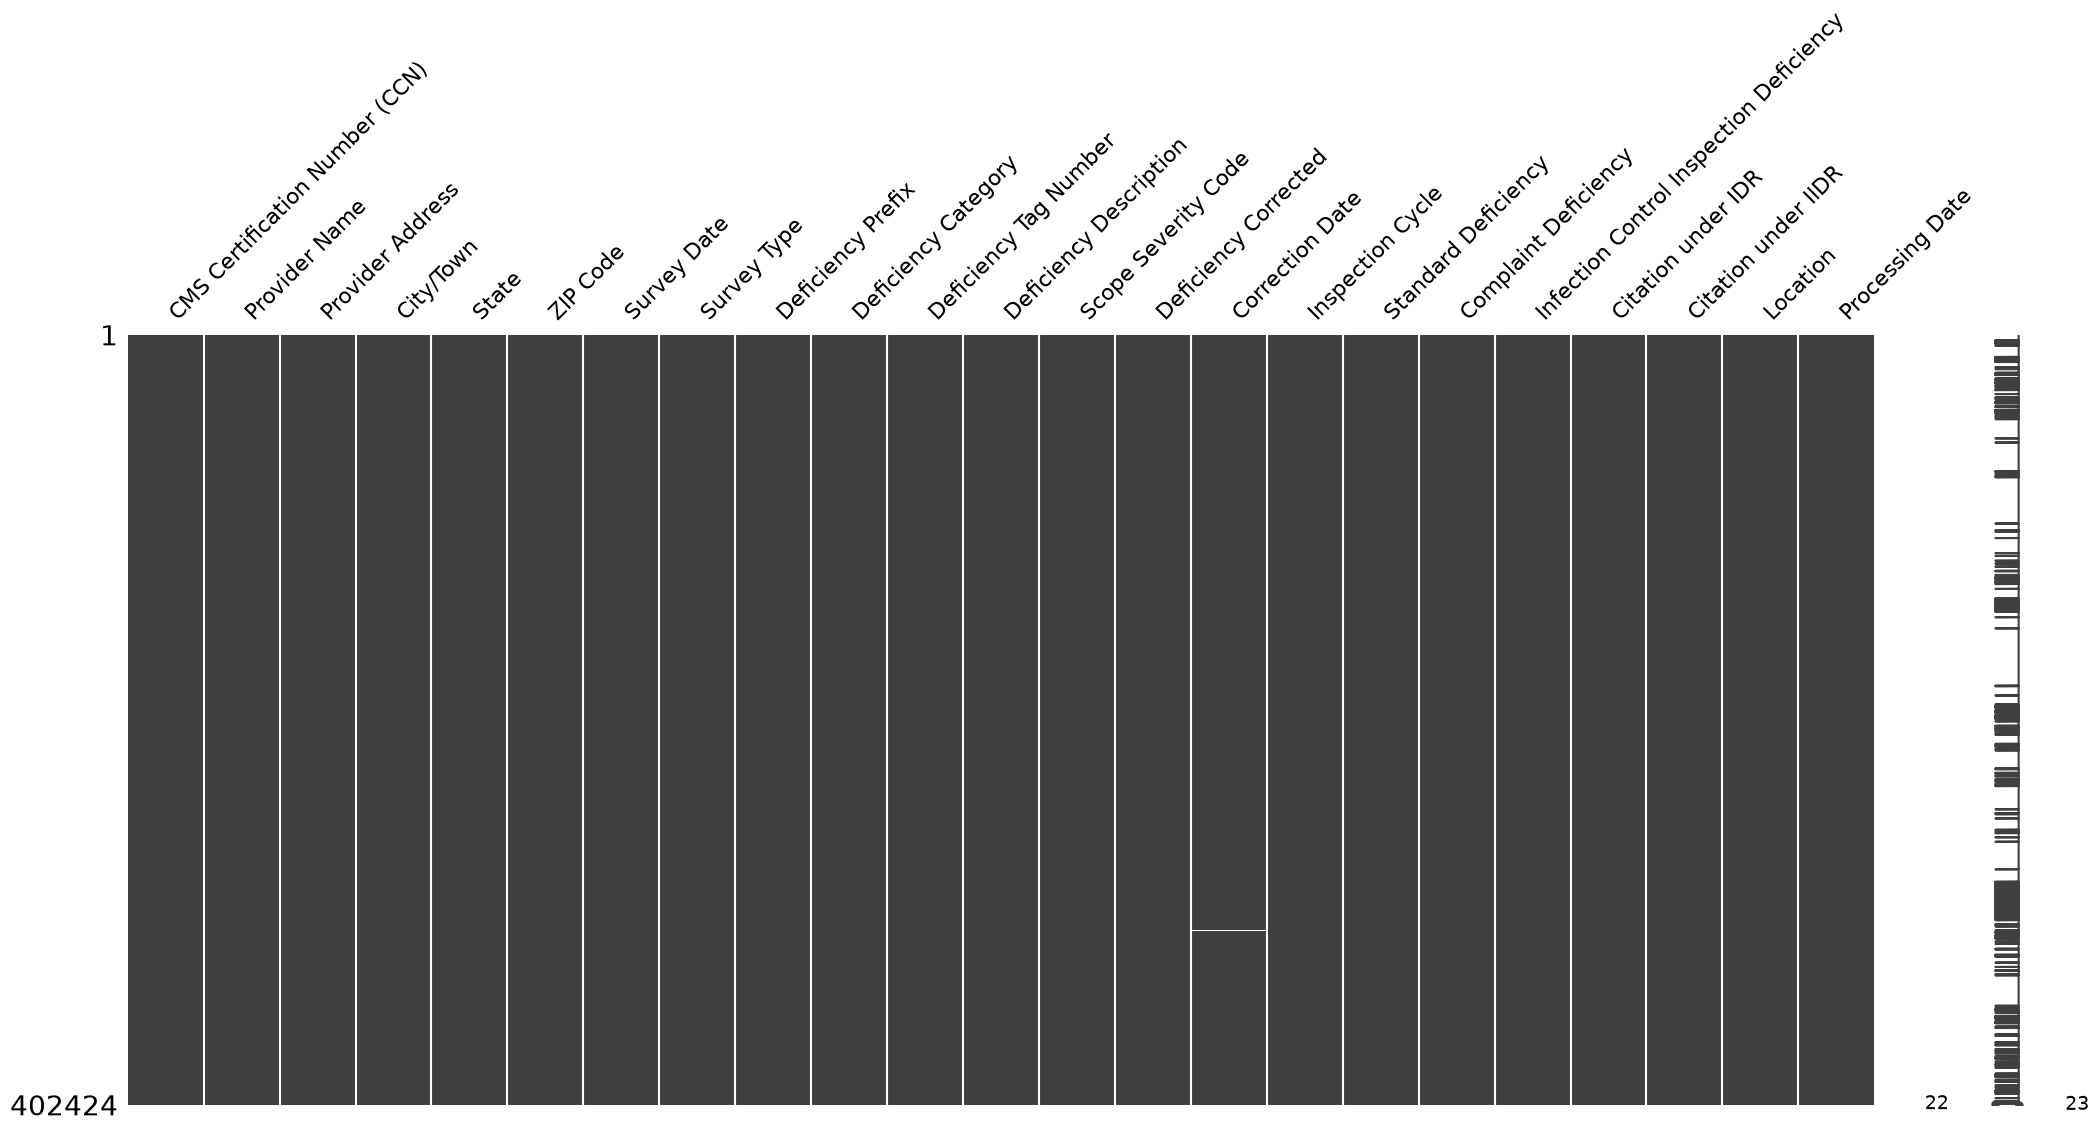

In [109]:
# Null Values
msno.matrix(NH_HealthCitations_Oct2024)

In [110]:
# Duplicates
NH_HealthCitations_Oct2024_duplicates = NH_HealthCitations_Oct2024[NH_HealthCitations_Oct2024.duplicated()]
print(NH_HealthCitations_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Survey Date, Survey Type, Deficiency Prefix, Deficiency Category, Deficiency Tag Number, Deficiency Description, Scope Severity Code, Deficiency Corrected, Correction Date, Inspection Cycle, Standard Deficiency, Complaint Deficiency, Infection Control Inspection Deficiency, Citation under IDR, Citation under IIDR, Location, Processing Date]
Index: []


### State-Level Health Inspection Cut Points
- State-specific ranges for the weighted health inspection score for each health inspection star rating category.
- One row per state/territory.

In [111]:
NH_HlthInspecCutpointsState_Oct2024.head()

,State,5 Stars,4 Stars,3 Stars,2 Stars,1 Star
0,AK,0.000-19.333,19.334-37.333,37.334-75.833,75.834-105.583,>105.583
1,AL,0.000-6.000,6.001-14.667,14.668-22.667,22.668-38.000,>38.000
2,AR,0.000-29.333,29.334-50.667,50.668-66.000,66.001-86.000,>86.000
3,AZ,0.000-12.000,12.001-22.667,22.668-35.000,35.001-57.333,>57.333
4,CA,0.000-36.667,36.668-66.667,66.668-99.000,99.001-158.833,>158.833


In [112]:
NH_HlthInspecCutpointsState_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   State    53 non-null     str  
 1   5 Stars  53 non-null     str  
 2   4 Stars  53 non-null     str  
 3   3 Stars  53 non-null     str  
 4   2 Stars  53 non-null     str  
 5   1 Star   53 non-null     str  
dtypes: str(6)
memory usage: 5.8 KB


<Axes: >

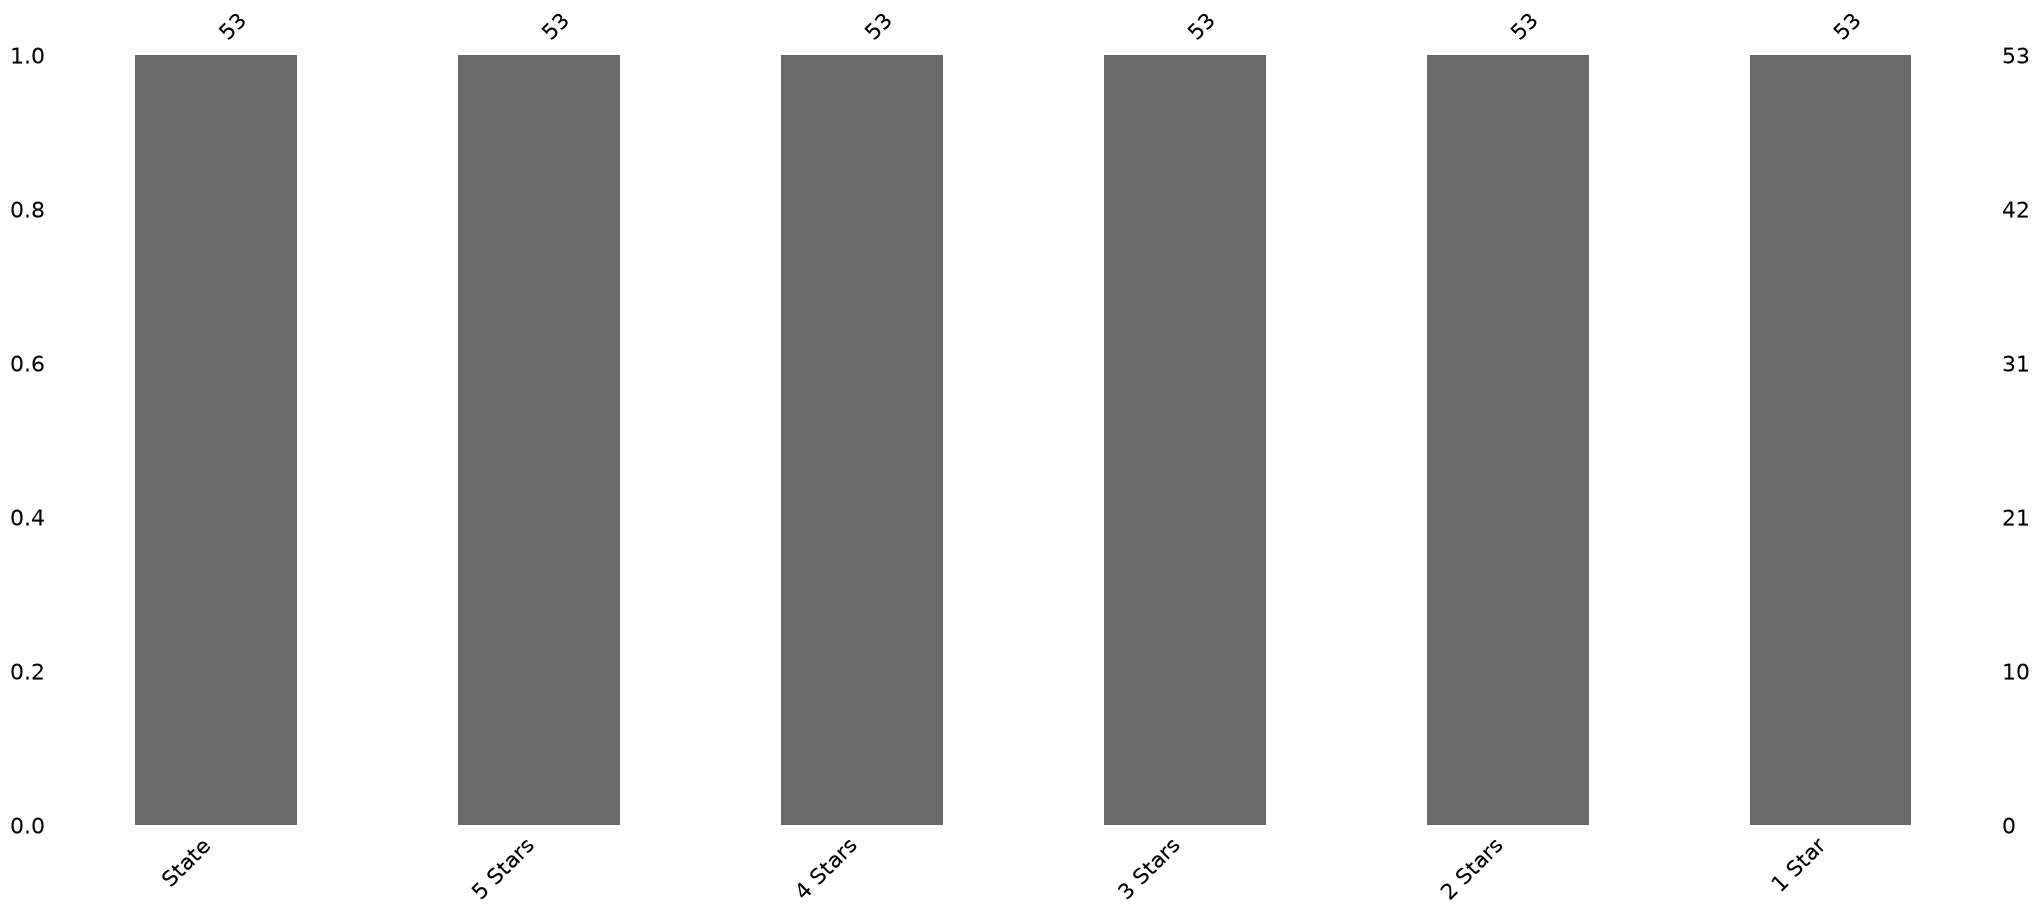

In [113]:
# Null Values
msno.bar(NH_HlthInspecCutpointsState_Oct2024)

In [114]:
# Duplicates
NH_HlthInspecCutpointsState_Oct2024_duplicates = NH_HlthInspecCutpointsState_Oct2024[NH_HlthInspecCutpointsState_Oct2024.duplicated()]
print(NH_HlthInspecCutpointsState_Oct2024_duplicates)

Empty DataFrame
Columns: [State, 5 Stars, 4 Stars, 3 Stars, 2 Stars, 1 Star]
Index: []


### Ownership
- Ownership info for currently active nursing homes

In [115]:
NH_Ownership_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Role played by Owner or Manager in Facility,Owner Type,Owner Name,Ownership Percentage,Association Date,Location,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,5% OR GREATER DIRECT OWNERSHIP INTEREST,Individual,"DEARMAN, CAMERON",5%,since 01/25/2012,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
1,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,5% OR GREATER DIRECT OWNERSHIP INTEREST,Individual,"DEARMAN, MARTHA",81%,since 09/01/1969,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
2,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,DIRECTOR,Individual,"DEARMAN, MARTHA",NOT APPLICABLE,since 09/07/1969,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
3,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,OFFICER,Individual,"DEARMAN, CAMERON",NOT APPLICABLE,since 12/26/2019,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
4,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,OFFICER,Individual,"DEARMAN, MARK",NOT APPLICABLE,since 12/26/2019,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01


In [116]:
NH_Ownership_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 145354 entries, 0 to 145353
Data columns (total 13 columns):
 #   Column                                       Non-Null Count   Dtype
---  ------                                       --------------   -----
 0   CMS Certification Number (CCN)               145354 non-null  str  
 1   Provider Name                                145354 non-null  str  
 2   Provider Address                             145354 non-null  str  
 3   City/Town                                    145354 non-null  str  
 4   State                                        145354 non-null  str  
 5   ZIP Code                                     145354 non-null  int64
 6   Role played by Owner or Manager in Facility  145354 non-null  str  
 7   Owner Type                                   144811 non-null  str  
 8   Owner Name                                   144811 non-null  str  
 9   Ownership Percentage                         144811 non-null  str  
 10  Association Date   

<Axes: >

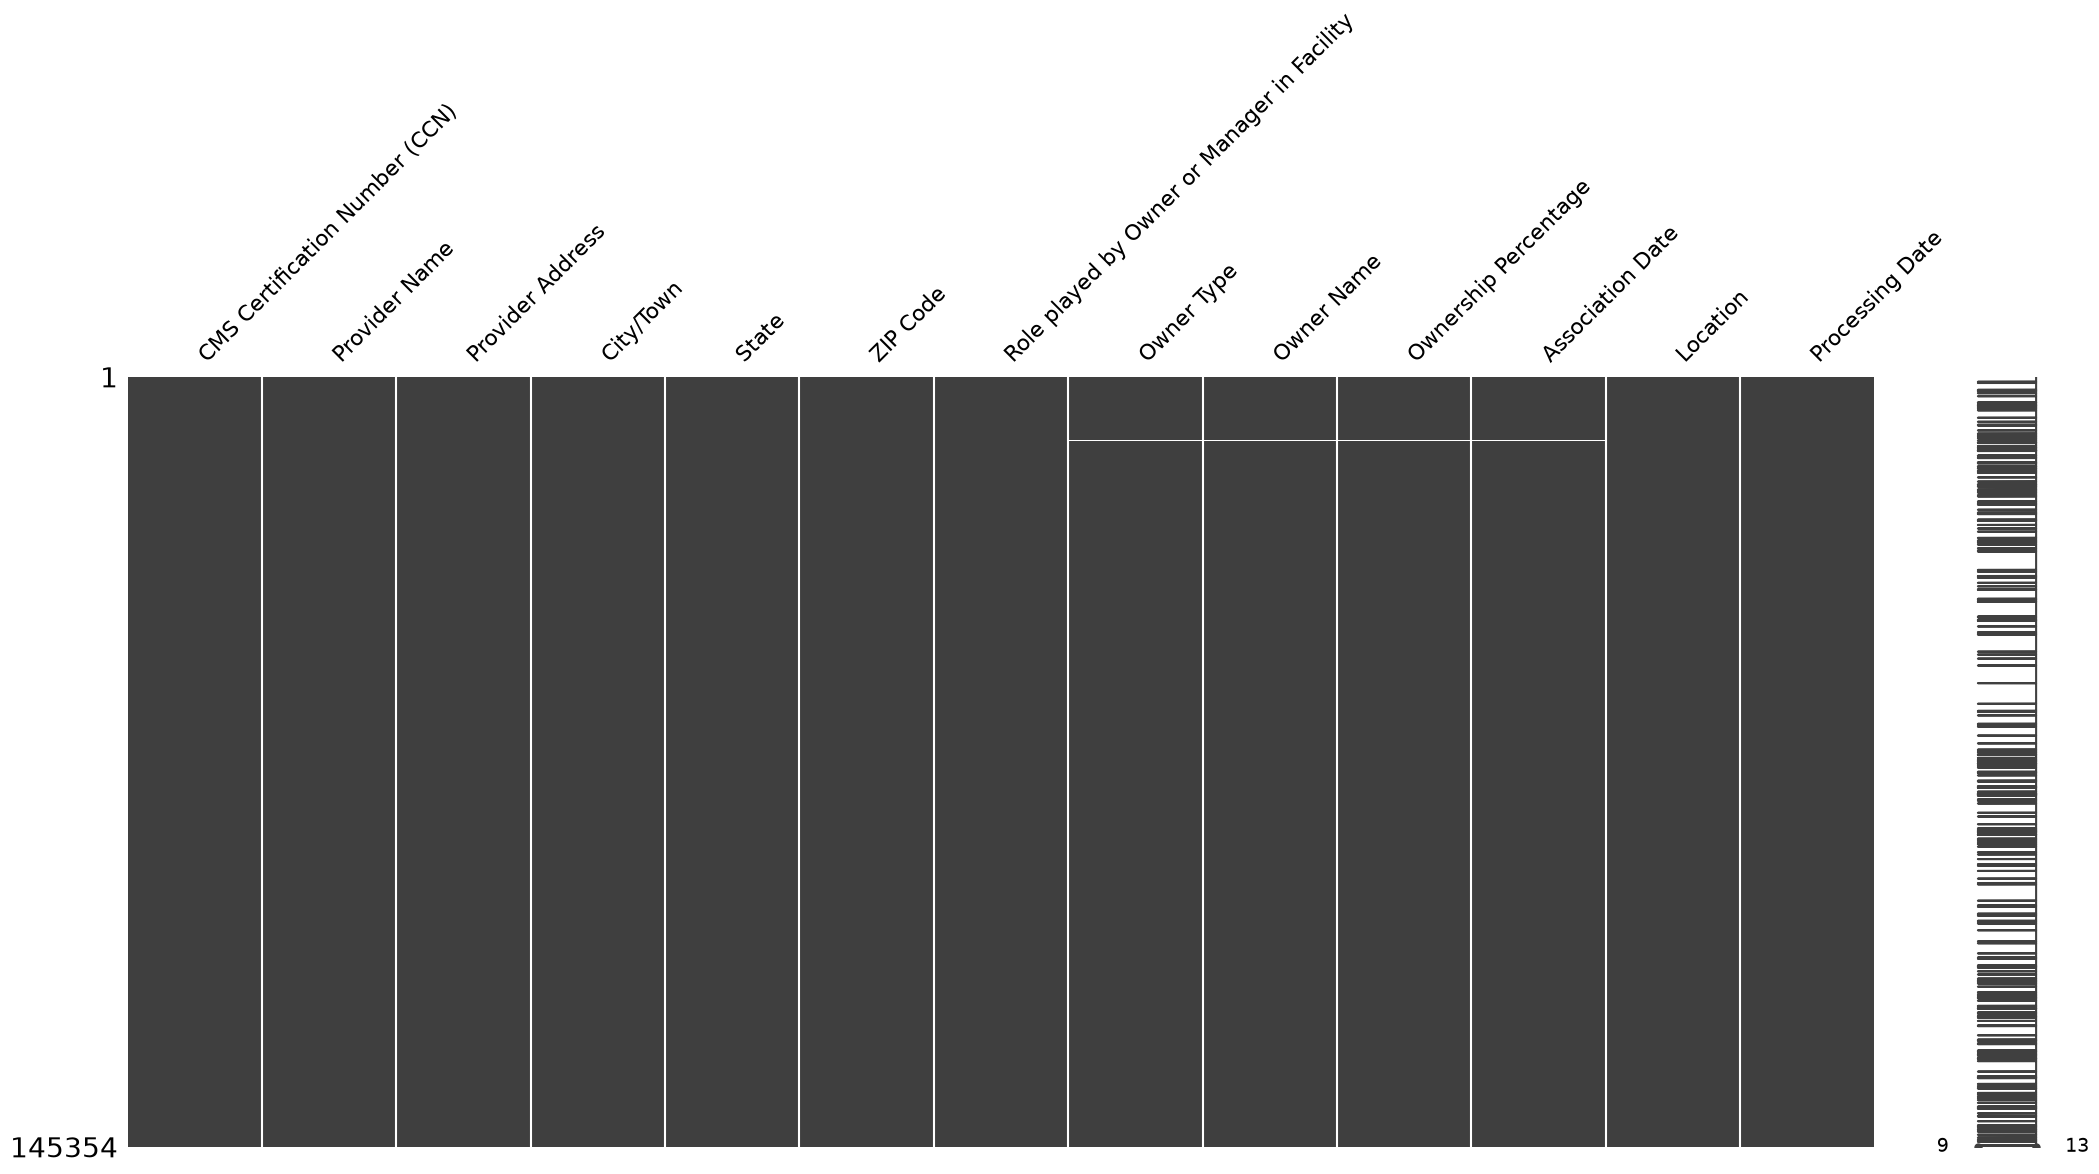

In [117]:
# Null Values
msno.matrix(NH_Ownership_Oct2024)

In [118]:
# Duplicates
NH_Ownership_Oct2024_duplicates = NH_Ownership_Oct2024[NH_Ownership_Oct2024.duplicated()]
print(NH_Ownership_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Role played by Owner or Manager in Facility, Owner Type, Owner Name, Ownership Percentage, Association Date, Location, Processing Date]
Index: []


In [119]:
# How many 'NA' values exist in the Owner Types?
# NH_Ownership_Oct2024['Owner Type'].value_counts()
summary = NH_Ownership_Oct2024.groupby('Owner Type', dropna=False)['Owner Type'].count()
print(summary)

Owner Type
Individual      104821
Organization     39990
NaN                  0
Name: Owner Type, dtype: int64


In [120]:
# How many 'NA' values exist in the Ownership Percentages?
# NH_Ownership_Oct2024['Owner Type'].value_counts()
summary2 = NH_Ownership_Oct2024.groupby('Ownership Percentage', dropna=False)['Ownership Percentage'].count()
print(summary2)

Ownership Percentage
10%                         923
100%                       8565
11%                         222
12%                         177
13%                         320
14%                         184
15%                         424
16%                         177
17%                         232
18%                         220
19%                         140
20%                         754
21%                         225
22%                          85
23%                         198
24%                         165
25%                         777
26%                         114
27%                          55
28%                         221
29%                          30
30%                         388
31%                          68
32%                         136
33%                         519
34%                          41
35%                          83
36%                          37
37%                          38
38%                          60
39%                

In [121]:
# Any non-numeric string will become NaN
NH_Ownership_Oct2024_copy = NH_Ownership_Oct2024.copy()
NH_Ownership_Oct2024_copy['Ownership Percentage'] = NH_Ownership_Oct2024_copy['Ownership Percentage'].replace(["NO PERCENTAGE PROVIDED","NOT APPLICABLE"], np.nan)
print(NH_Ownership_Oct2024_copy['Ownership Percentage'].head(10))

0      5%
1     81%
2     NaN
3     NaN
4     NaN
5     NaN
6     NaN
7    100%
8     NaN
9     NaN
Name: Ownership Percentage, dtype: str


In [122]:
# Remove '%' on all non-null values to convert dtype to int
NH_Ownership_Oct2024_copy['Ownership Percentage'] = NH_Ownership_Oct2024_copy['Ownership Percentage'].str.replace("%", "", regex=False)
print(NH_Ownership_Oct2024_copy['Ownership Percentage'].head(10))

0      5
1     81
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    100
8    NaN
9    NaN
Name: Ownership Percentage, dtype: str


In [123]:
# Bin Ownership Percentages into groups
own_bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
own_labels = ['0-10%', '11-20%', '21-30%', '31-40%', '41-50%', '51-60%', '61-70%', '71-80%', '81-90%', '91-100%']

NH_Ownership_Oct2024_copy['Ownership Percentage'] = pd.to_numeric(NH_Ownership_Oct2024_copy['Ownership Percentage'], errors="coerce")

NH_Ownership_Oct2024_copy['Ownership_Ranges'] = pd.cut(
    NH_Ownership_Oct2024_copy['Ownership Percentage'],
    bins=own_bins,
    labels=own_labels,
    include_lowest=True
).astype(str)

ownership_percentages = NH_Ownership_Oct2024_copy['Ownership_Ranges'].value_counts().reset_index()
ownership_percentages.columns = ['Range', 'Row_Count']
print(ownership_percentages)

     Range  Row_Count
0  91-100%       9129
1    0-10%       3413
2   11-20%       2850
3   41-50%       2632
4   21-30%       2258
5   31-40%       1289
6   51-60%        324
7   71-80%        242
8   81-90%        213
9   61-70%        210


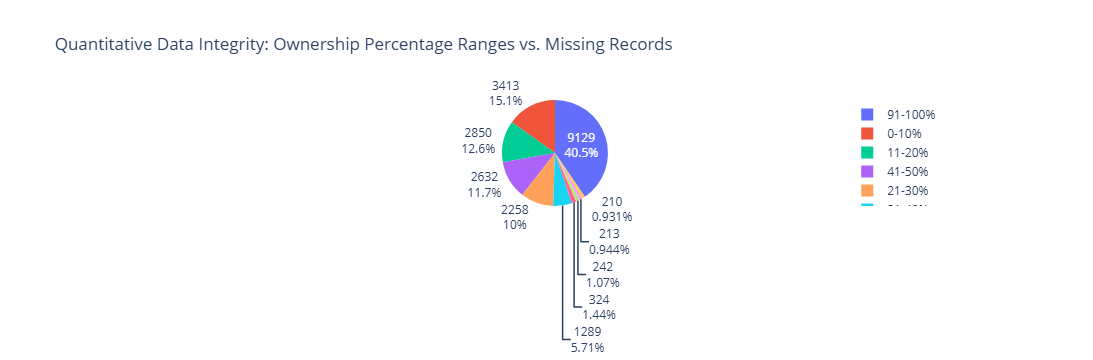

In [124]:
own_fig = px.pie(
    ownership_percentages,
    values='Row_Count',
    names='Range',
    color='Range',
    title='Quantitative Data Integrity: Ownership Percentage Ranges vs. Missing Records'
)

own_fig.update_traces(textinfo='value+percent')
own_fig.show()

In [125]:
# Exclude null values
NH_Ownership_Oct2024_copy2 = NH_Ownership_Oct2024_copy.copy()
NH_Ownership_Oct2024_copy2 = NH_Ownership_Oct2024_copy2.dropna(subset=['Ownership Percentage'])
print(NH_Ownership_Oct2024_copy2.head(10))

   CMS Certification Number (CCN)  \
0                          015009   
1                          015009   
7                          015010   
24                         015014   
28                         015015   
29                         015015   
32                         015016   
33                         015016   
34                         015016   
35                         015016   

                                  Provider Name             Provider Address  \
0                      BURNS NURSING HOME, INC.         701 MONROE STREET NW   
1                      BURNS NURSING HOME, INC.         701 MONROE STREET NW   
7                COOSA VALLEY HEALTHCARE CENTER       260 WEST WALNUT STREET   
24  EASTVIEW REHABILITATION & HEALTHCARE CENTER     7755 FOURTH AVENUE SOUTH   
28                PLANTATION MANOR NURSING HOME  6450 OLD TUSCALOOSA HIGHWAY   
29                PLANTATION MANOR NURSING HOME  6450 OLD TUSCALOOSA HIGHWAY   
32         ATHENS HEALTH AND REH

In [126]:
# Bins excluding nulls
ownership_percentages_non_null = NH_Ownership_Oct2024_copy2['Ownership_Ranges'].value_counts().reset_index()
ownership_percentages_non_null.columns = ['Range', 'Row_Count']
print(ownership_percentages_non_null)

     Range  Row_Count
0  91-100%       9129
1    0-10%       3413
2   11-20%       2850
3   41-50%       2632
4   21-30%       2258
5   31-40%       1289
6   51-60%        324
7   71-80%        242
8   81-90%        213
9   61-70%        210


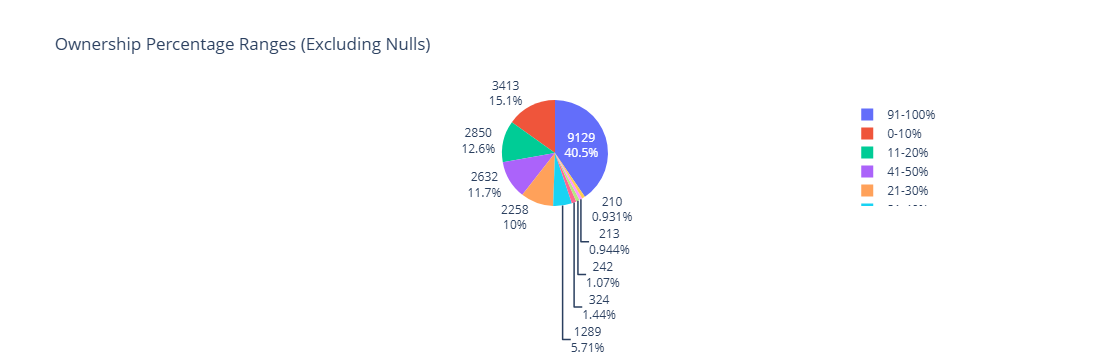

In [127]:
own_non_null_fig = px.pie(
    ownership_percentages_non_null,
    values='Row_Count',
    names='Range',
    color='Range',
    title='Ownership Percentage Ranges (Excluding Nulls)'
)

own_non_null_fig.update_traces(textinfo='value+percent')
own_non_null_fig.show()

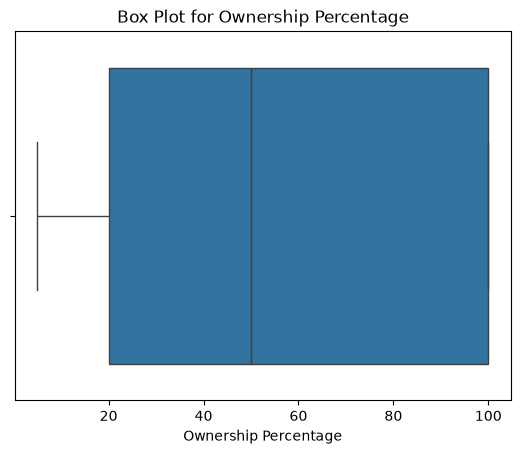

In [128]:
# Outlier Detection: Ownership Percentage Boxplot
sns.boxplot(x=NH_Ownership_Oct2024_copy2['Ownership Percentage'])
plt.title("Box Plot for Ownership Percentage")
plt.show()

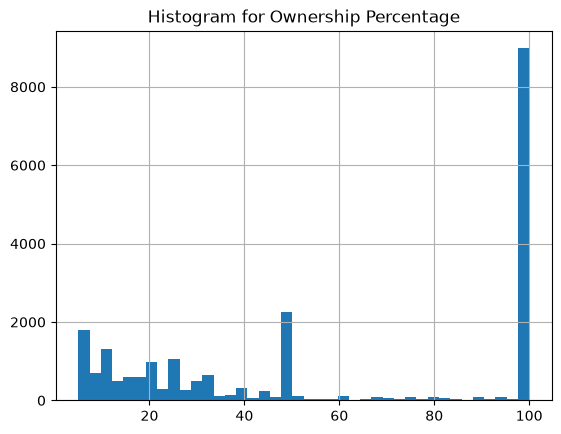

In [129]:
# Outlier Detection: Ownership Percentage Histogram
NH_Ownership_Oct2024_copy2['Ownership Percentage'].hist(bins=40)
plt.title("Histogram for Ownership Percentage")
plt.show()

In [130]:
# Outlier Detection: Ownership Percentage Z-Scores
z = np.abs(stats.zscore(NH_Ownership_Oct2024_copy2['Ownership Percentage']))
outliers = NH_Ownership_Oct2024_copy2[z > 3]

print("Outliers:\n", outliers.loc[:,['CMS Certification Number (CCN)','State','Owner Name','Ownership Percentage']])

Outliers:
 Empty DataFrame
Columns: [CMS Certification Number (CCN), State, Owner Name, Ownership Percentage]
Index: []


### Penalties
- Fines and payment details received by nursing homes in the last three years.

In [131]:
NH_Penalties_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Penalty Date,Penalty Type,Fine Amount,Payment Denial Start Date,Payment Denial Length in Days,Location,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2023-03-02,Fine,23989.0,NaN,NaN,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
1,015032,DIVERSICARE OF FOLEY,1701 NORTH ALSTON STREET,FOLEY,AL,36535,2023-06-19,Fine,10065.0,NaN,NaN,"1701 NORTH ALSTON STREET,FOLEY,AL,36535",2024-10-01
2,015045,EAMC LANIER NURSING HOME,4800 48TH STREET,VALLEY,AL,36854,2021-11-15,Fine,650.0,NaN,NaN,"4800 48TH STREET,VALLEY,AL,36854",2024-10-01
3,015048,CULLMAN HEALTH CARE CENTER,1607 MAIN AVE NE,CULLMAN,AL,35055,2023-10-19,Fine,26982.0,NaN,NaN,"1607 MAIN AVE NE,CULLMAN,AL,35055",2024-10-01
4,015050,OAK CREST HEALTH & WELLNESS,325 SELMA ROAD,BESSEMER,AL,35020,2021-11-29,Fine,655.0,NaN,NaN,"325 SELMA ROAD,BESSEMER,AL,35020",2024-10-01


In [132]:
NH_Penalties_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 28505 entries, 0 to 28504
Data columns (total 13 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   CMS Certification Number (CCN)  28505 non-null  str    
 1   Provider Name                   28505 non-null  str    
 2   Provider Address                28505 non-null  str    
 3   City/Town                       28505 non-null  str    
 4   State                           28505 non-null  str    
 5   ZIP Code                        28505 non-null  int64  
 6   Penalty Date                    28505 non-null  str    
 7   Penalty Type                    28505 non-null  str    
 8   Fine Amount                     25338 non-null  float64
 9   Payment Denial Start Date       3167 non-null   str    
 10  Payment Denial Length in Days   3167 non-null   float64
 11  Location                        28505 non-null  str    
 12  Processing Date                 28505 non-n

<Axes: >

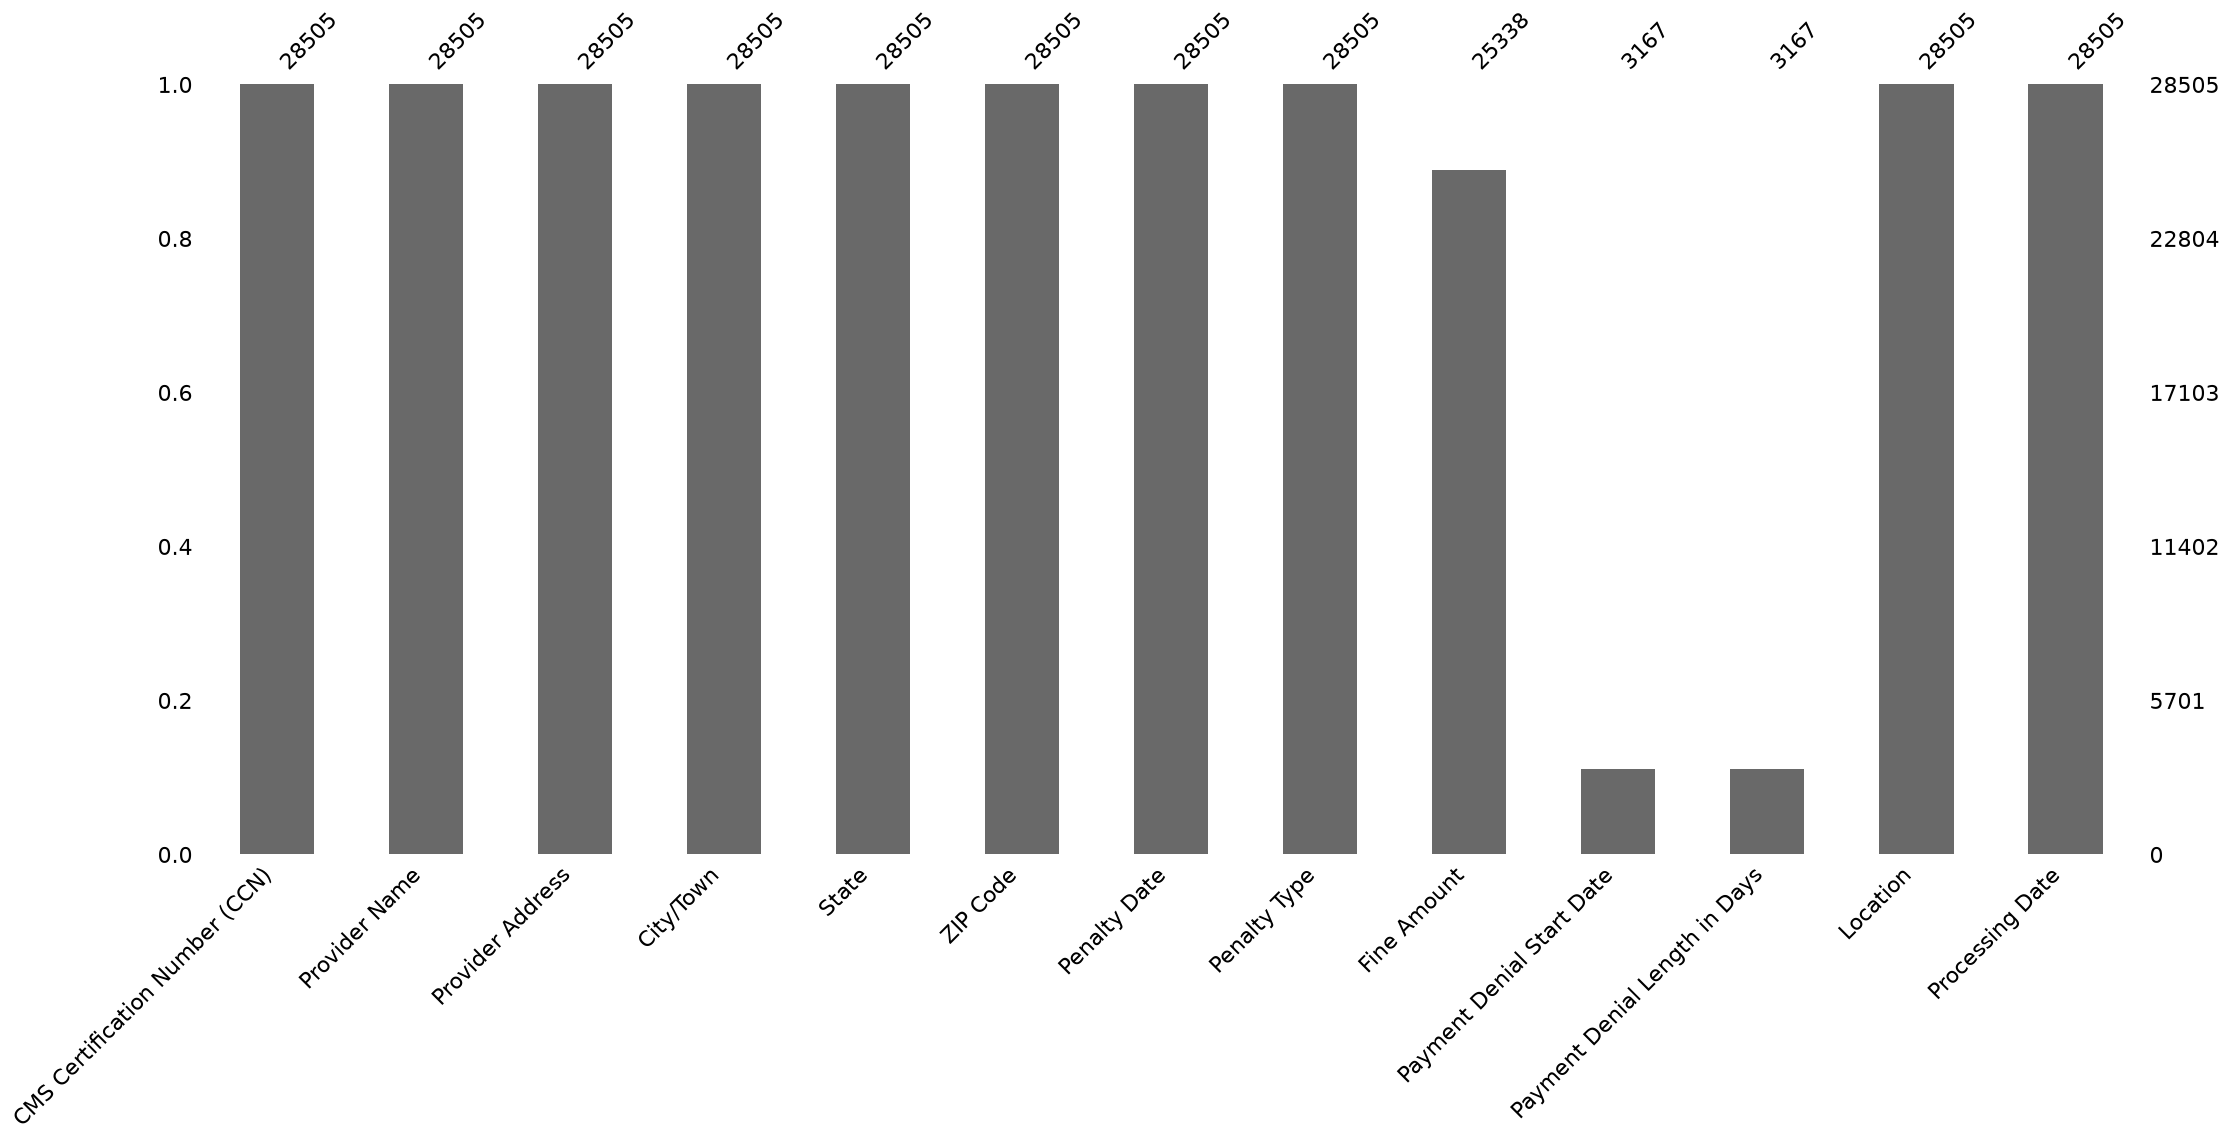

In [133]:
# Null Values
msno.bar(NH_Penalties_Oct2024)

In [134]:
# Duplicates
NH_Penalties_Oct2024_duplicates = NH_Penalties_Oct2024[NH_Penalties_Oct2024.duplicated()]
print(NH_Penalties_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Penalty Date, Penalty Type, Fine Amount, Payment Denial Start Date, Payment Denial Length in Days, Location, Processing Date]
Index: []


### Provider Info
- General info on currently active nursing homes. One row per nursing home. 
- Info included as part of the Five-Star Rating System

In [135]:
NH_ProviderInfo_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Telephone Number,Provider SSA County Code,County/Parish,Ownership Type,Number of Certified Beds,Average Number of Residents per Day,Average Number of Residents per Day Footnote,Provider Type,Provider Resides in Hospital,Legal Business Name,Date First Approved to Provide Medicare and Medicaid Services,Affiliated Entity Name,Affiliated Entity ID,Continuing Care Retirement Community,Special Focus Status,Abuse Icon,Most Recent Health Inspection More Than 2 Years Ago,Provider Changed Ownership in Last 12 Months,With a Resident and Family Council,Automatic Sprinkler Systems in All Required Areas,Overall Rating,Overall Rating Footnote,Health Inspection Rating,Health Inspection Rating Footnote,QM Rating,QM Rating Footnote,Long-Stay QM Rating,Long-Stay QM Rating Footnote,Short-Stay QM Rating,Short-Stay QM Rating Footnote,Staffing Rating,Staffing Rating Footnote,Reported Staffing Footnote,Physical Therapist Staffing Footnote,Reported Nurse Aide Staffing Hours per Resident per Day,Reported LPN Staffing Hours per Resident per Day,Reported RN Staffing Hours per Resident per Day,Reported Licensed Staffing Hours per Resident per Day,Reported Total Nurse Staffing Hours per Resident per Day,Total number of nurse staff hours per resident per day on the weekend,Registered Nurse hours per resident per day on the weekend,Reported Physical Therapist Staffing Hours per Resident Per Day,Total nursing staff turnover,Total nursing staff turnover footnote,Registered Nurse turnover,Registered Nurse turnover footnote,Number of administrators who have left the nursing home,Administrator turnover footnote,Nursing Case-Mix Index,Nursing Case-Mix Index Ratio,Case-Mix Nurse Aide Staffing Hours per Resident per Day,Case-Mix LPN Staffing Hours per Resident per Day,Case-Mix RN Staffing Hours per Resident per Day,Case-Mix Total Nurse Staffing Hours per Resident per Day,Case-Mix Weekend Total Nurse Staffing Hours per Resident per Day,Adjusted Nurse Aide Staffing Hours per Resident per Day,Adjusted LPN Staffing Hours per Resident per Day,Adjusted RN Staffing Hours per Resident per Day,Adjusted Total Nurse Staffing Hours per Resident per Day,Adjusted Weekend Total Nurse Staffing Hours per Resident per Day,Rating Cycle 1 Standard Survey Health Date,Rating Cycle 1 Total Number of Health Deficiencies,Rating Cycle 1 Number of Standard Health Deficiencies,Rating Cycle 1 Number of Complaint Health Deficiencies,Rating Cycle 1 Health Deficiency Score,Rating Cycle 1 Number of Health Revisits,Rating Cycle 1 Health Revisit Score,Rating Cycle 1 Total Health Score,Rating Cycle 2 Standard Health Survey Date,Rating Cycle 2 Total Number of Health Deficiencies,Rating Cycle 2 Number of Standard Health Deficiencies,Rating Cycle 2 Number of Complaint Health Deficiencies,Rating Cycle 2 Health Deficiency Score,Rating Cycle 2 Number of Health Revisits,Rating Cycle 2 Health Revisit Score,Rating Cycle 2 Total Health Score,Rating Cycle 3 Standard Health Survey Date,Rating Cycle 3 Total Number of Health Deficiencies,Rating Cycle 3 Number of Standard Health Deficiencies,Rating Cycle 3 Number of Complaint Health Deficiencies,Rating Cycle 3 Health Deficiency Score,Rating Cycle 3 Number of Health Revisits,Rating Cycle 3 Health Revisit Score,Rating Cycle 3 Total Health Score,Total Weighted Health Survey Score,Number of Facility Reported Incidents,Number of Substantiated Complaints,Number of Citations from Infection Control Inspections,Number of Fines,Total Amount of Fines in Dollars,Number of Payment Denials,Total Number of Penalties,Location,Latitude,Longitude,Geocoding Footnote,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2563324110,290,Franklin,For profit - Corporation,57,53.3,NaN,Medicare and Medicaid,N,"BURNS NURSING HOME, INC.",1969-09-01,NaN,NaN,N,NaN,N,N,N,Resident,Yes,2.0,NaN,2.0,NaN,4.0,NaN,4.0,NaN,4.0,NaN,4.0,NaN,NaN,NaN,2.58352,0.42259,1.28749,1.71009

In [136]:
NH_ProviderInfo_Oct2024.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 14814 entries, 0 to 14813
Data columns (total 103 columns):
 #    Column                                                                 Non-Null Count  Dtype  
---   ------                                                                 --------------  -----  
 0    CMS Certification Number (CCN)                                         14814 non-null  str    
 1    Provider Name                                                          14814 non-null  str    
 2    Provider Address                                                       14814 non-null  str    
 3    City/Town                                                              14814 non-null  str    
 4    State                                                                  14814 non-null  str    
 5    ZIP Code                                                               14814 non-null  int64  
 6    Telephone Number                                                       14814 non-null  

<Axes: >

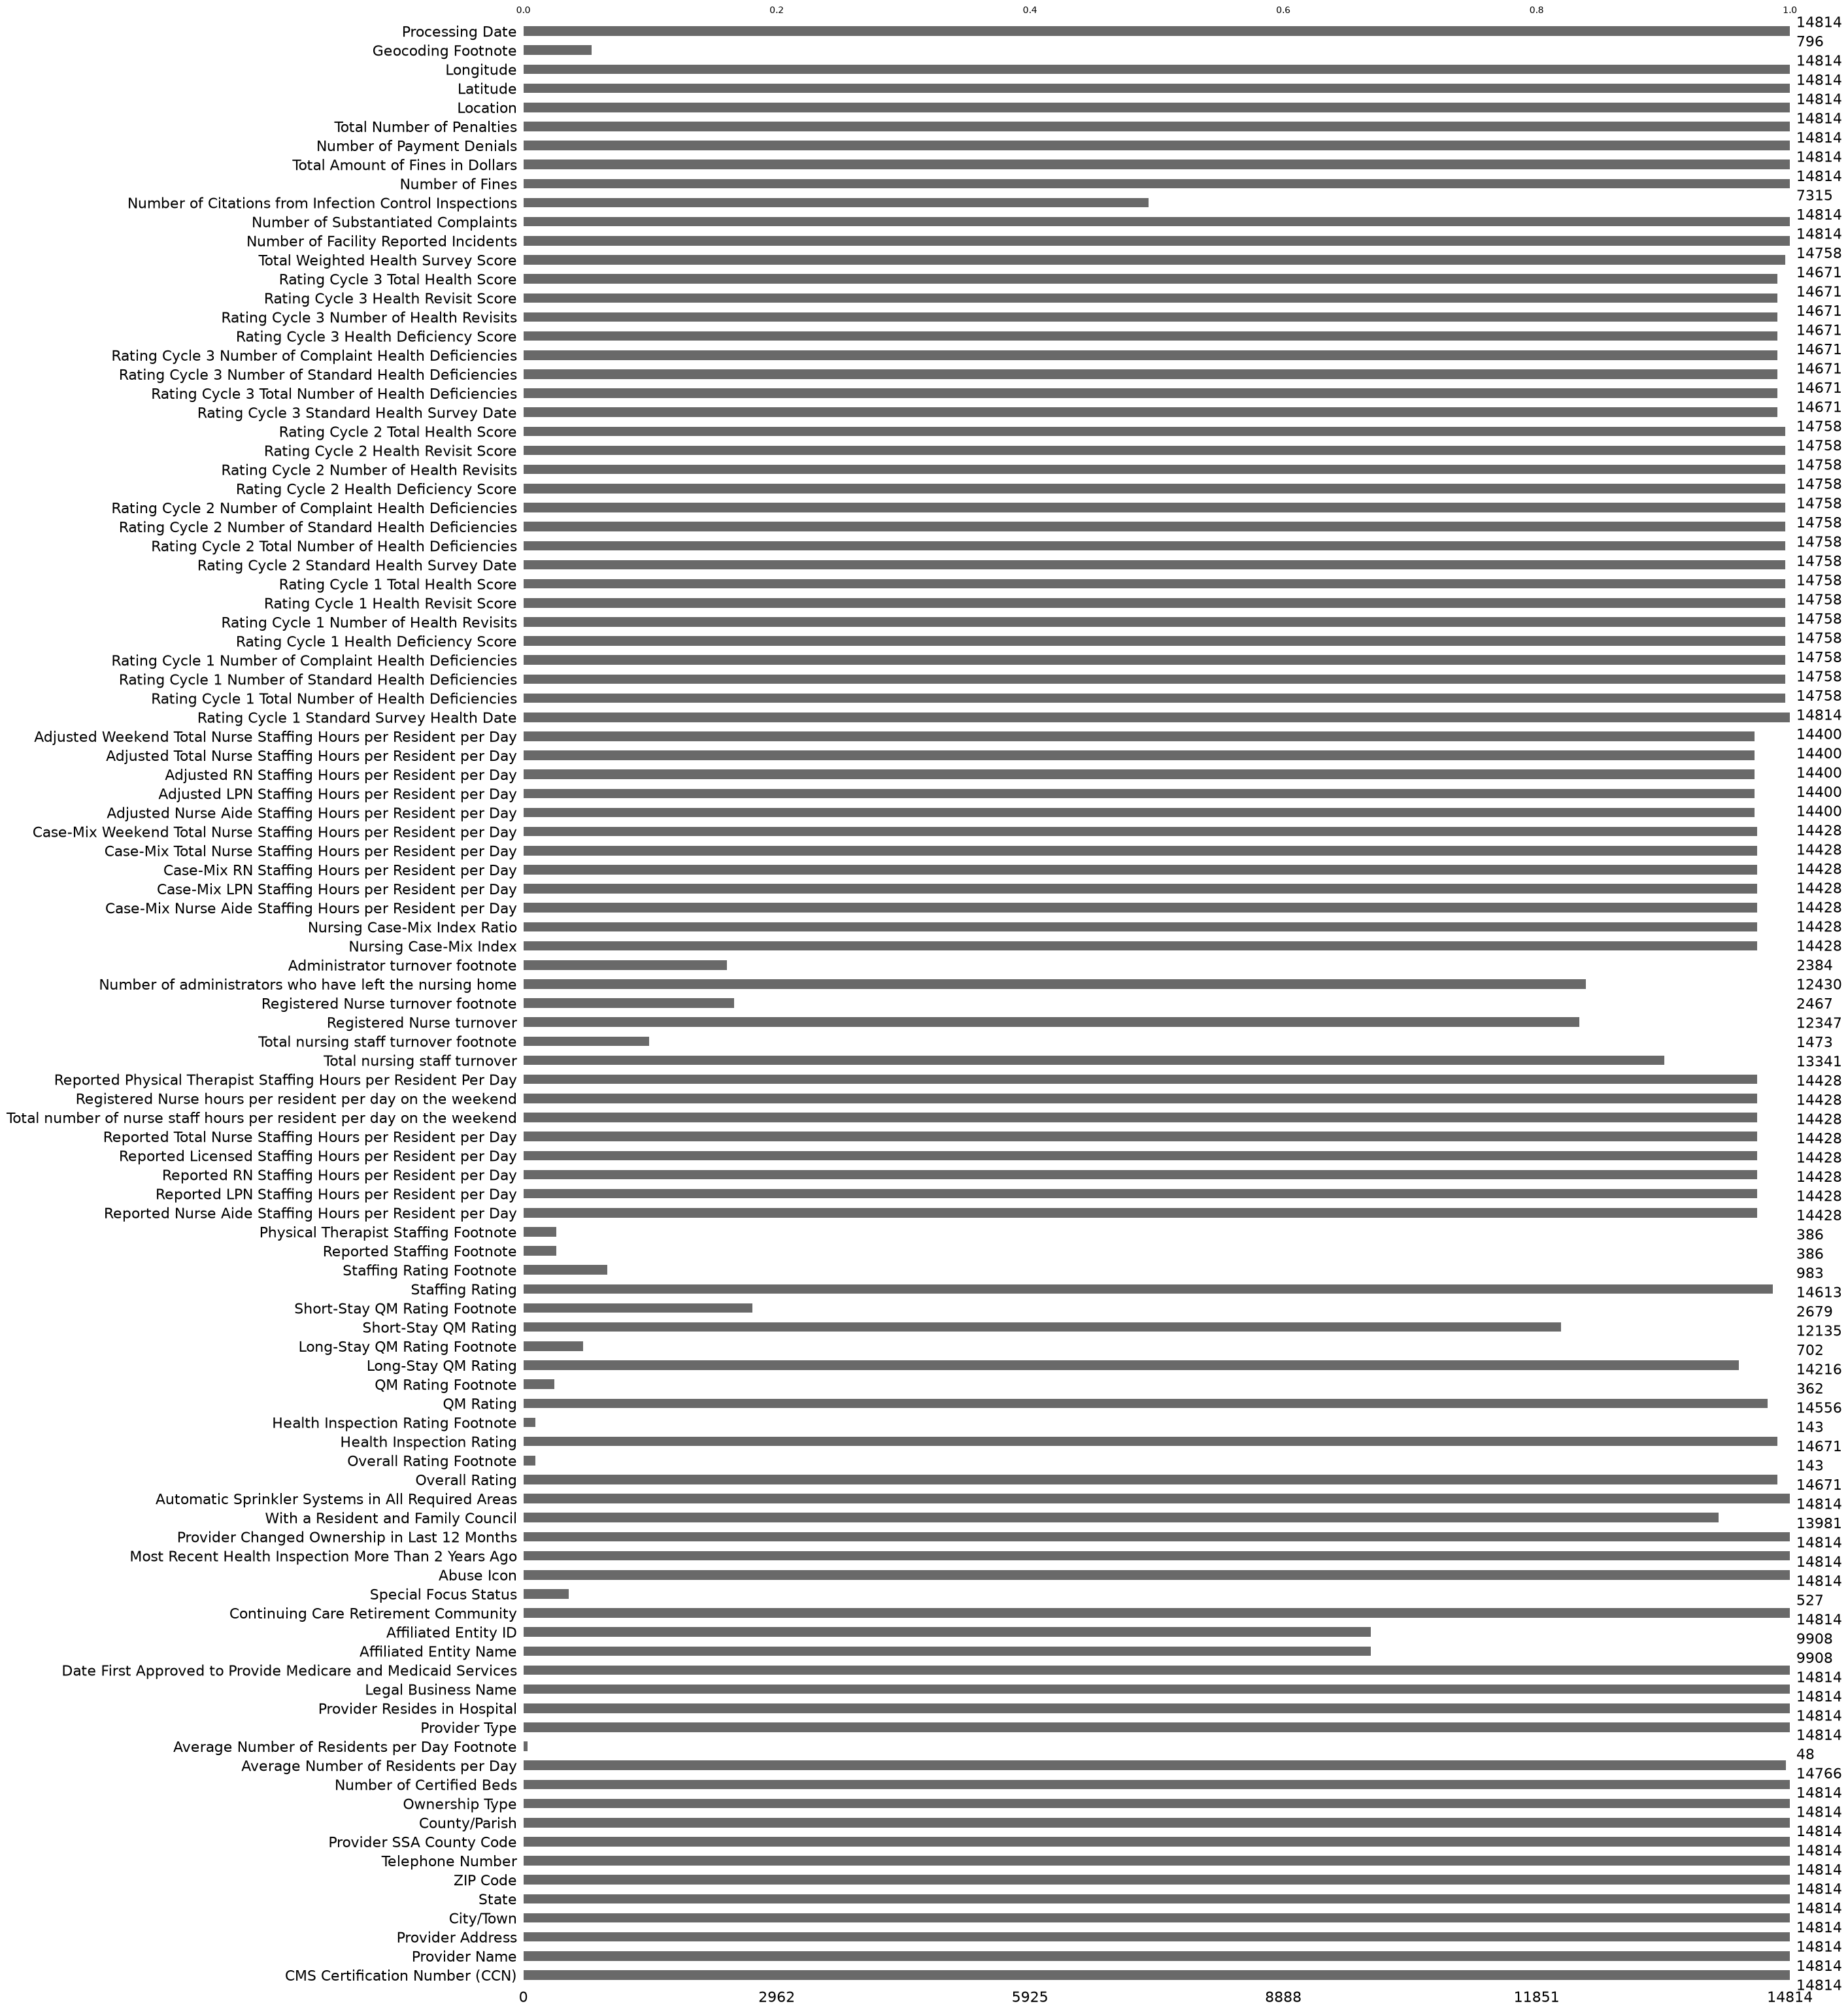

In [137]:
# Null Values
msno.bar(NH_ProviderInfo_Oct2024)

In [138]:
# Duplicates
NH_ProviderInfo_Oct2024_duplicates = NH_ProviderInfo_Oct2024[NH_ProviderInfo_Oct2024.duplicated()]
print(NH_ProviderInfo_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Telephone Number, Provider SSA County Code, County/Parish, Ownership Type, Number of Certified Beds, Average Number of Residents per Day, Average Number of Residents per Day Footnote, Provider Type, Provider Resides in Hospital, Legal Business Name, Date First Approved to Provide Medicare and Medicaid Services, Affiliated Entity Name, Affiliated Entity ID, Continuing Care Retirement Community, Special Focus Status, Abuse Icon, Most Recent Health Inspection More Than 2 Years Ago, Provider Changed Ownership in Last 12 Months, With a Resident and Family Council, Automatic Sprinkler Systems in All Required Areas, Overall Rating, Overall Rating Footnote, Health Inspection Rating, Health Inspection Rating Footnote, QM Rating, QM Rating Footnote, Long-Stay QM Rating, Long-Stay QM Rating Footnote, Short-Stay QM Rating, Short-Stay QM Rating Footnote, Staffing Rating, Staffing R

In [139]:
# All nulls in the "Average Number of Residents per Day" are represented by a '10' footnote code, which, per the data dictionary, translates to:
# "The data for this measure is missing or was not submitted. Call the facility to discuss this quality measure."

residents_per_day_nulls = NH_ProviderInfo_Oct2024.loc[NH_ProviderInfo_Oct2024["Average Number of Residents per Day"].isna(), ["CMS Certification Number (CCN)", "Provider Name", "State", "Average Number of Residents per Day Footnote"]]
residents_per_day_nulls

,CMS Certification Number (CCN),Provider Name,State,Average Number of Residents per Day Footnote
385,035303,ARIZONA STATE VETERAN HOME - YUMA,AZ,10.0
856,055658,TWILIGHT HAVEN,CA,10.0
1070,056182,GOLDEN HILL POST ACUTE,CA,10.0
2259,105974,LIFE CARE CENTER OF ORLANDO,FL,10.0
2293,106027,AVANTE AT ORLANDO INC,FL,10.0
2763,115777,PRUITTHEALTH - CREEKSIDE,GA,10.0
3548,146199,THREE CROWNS PARK,IL,10.0
3672,155231,RANDOLPH NURSING HOME,IN,10.0
4252,165356,VALLEY VIEW COMMUNITY,IA,10.0
4457,165788,PRAIRIE GATE,IA,10.0


In [140]:
# Proportion of nulls in Average Number of Residents per Day compared to state total
# Nulls make up less than 2% of all state-level totals. Okay to delete nulls?

summary = (
    NH_ProviderInfo_Oct2024.groupby('State', dropna=False)["Average Number of Residents per Day"]
        .agg(
            null_count=lambda x: x.isna().sum(),
            total_count='size',
            null_proportion=lambda x: x.isna().mean()
        )
    .reset_index()
)

print(summary)

   State  null_count  total_count  null_proportion
0     AK           0           20         0.000000
1     AL           0          224         0.000000
2     AR           0          219         0.000000
3     AZ           1          142         0.007042
4     CA           5         1164         0.004296
5     CO           0          211         0.000000
6     CT           0          196         0.000000
7     DC           0           17         0.000000
8     DE           0           44         0.000000
9     FL           2          696         0.002874
10    GA           1          357         0.002801
11    GU           0            1         0.000000
12    HI           0           42         0.000000
13    IA           3          403         0.007444
14    ID           0           80         0.000000
15    IL           1          680         0.001471
16    IN           1          510         0.001961
17    KS           1          304         0.003289
18    KY           1          2

In [179]:
# Provider Types

provider_types = NH_ProviderInfo_Oct2024["Provider Type"].value_counts()
print(provider_types)

Provider Type
Medicare and Medicaid    13988
Medicare                   565
Medicaid                   261
Name: count, dtype: int64


### Medicare Claims Quality Measures
- Quality measures based on the resident assessments that make up the nursing home Minimum Data Set (MDS).
- Each row contains a specific quality measure for a specific nursing home and includes the 4-quarter score average and scores for each individual quarter.

In [141]:
NH_QualityMsr_Claims_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Measure Code,Measure Description,Resident type,Adjusted Score,Observed Score,Expected Score,Footnote for Score,Used in Quality Measure Five Star Rating,Measure Period,Location,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,521,Percentage of short-stay residents who were rehospitalized after a nursing home admission,Short Stay,16.990363,16.129032,21.306542,NaN,Y,20230401-20240331,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
1,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,522,Percentage of short-stay residents who had an outpatient emergency department visit,Short Stay,4.596690,4.838710,11.714163,NaN,Y,20230401-20240331,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
2,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,551,Number of hospitalizations per 1000 long-stay resident days,Long Stay,1.421487,1.415428,1.717587,NaN,Y,20230401-20240331,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
3,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,552,Number of outpatient emergency department visits per 1000 long-stay resident days,Long Stay,0.732786,0.808816,1.785995,NaN,Y,20230401-20240331,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
4,015010,COOSA VALLEY HEALTHCARE CENTER,260 WEST WALNUT STREET,SYLACAUGA,AL,35150,521,Percentage of short-stay residents who were rehospitalized after a nursing home admission,Short Stay,24.096511,18.055556,16.817600,NaN,Y,20230401-20240331,"260 WEST WALNUT STREET, SYLACAUGA, AL, 35150",2024-10-01


In [142]:
NH_QualityMsr_Claims_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 59256 entries, 0 to 59255
Data columns (total 17 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   CMS Certification Number (CCN)            59256 non-null  str    
 1   Provider Name                             59256 non-null  str    
 2   Provider Address                          59256 non-null  str    
 3   City/Town                                 59256 non-null  str    
 4   State                                     59256 non-null  str    
 5   ZIP Code                                  59256 non-null  int64  
 6   Measure Code                              59256 non-null  int64  
 7   Measure Description                       59256 non-null  str    
 8   Resident type                             59256 non-null  str    
 9   Adjusted Score                            47132 non-null  float64
 10  Observed Score                            471

<Axes: >

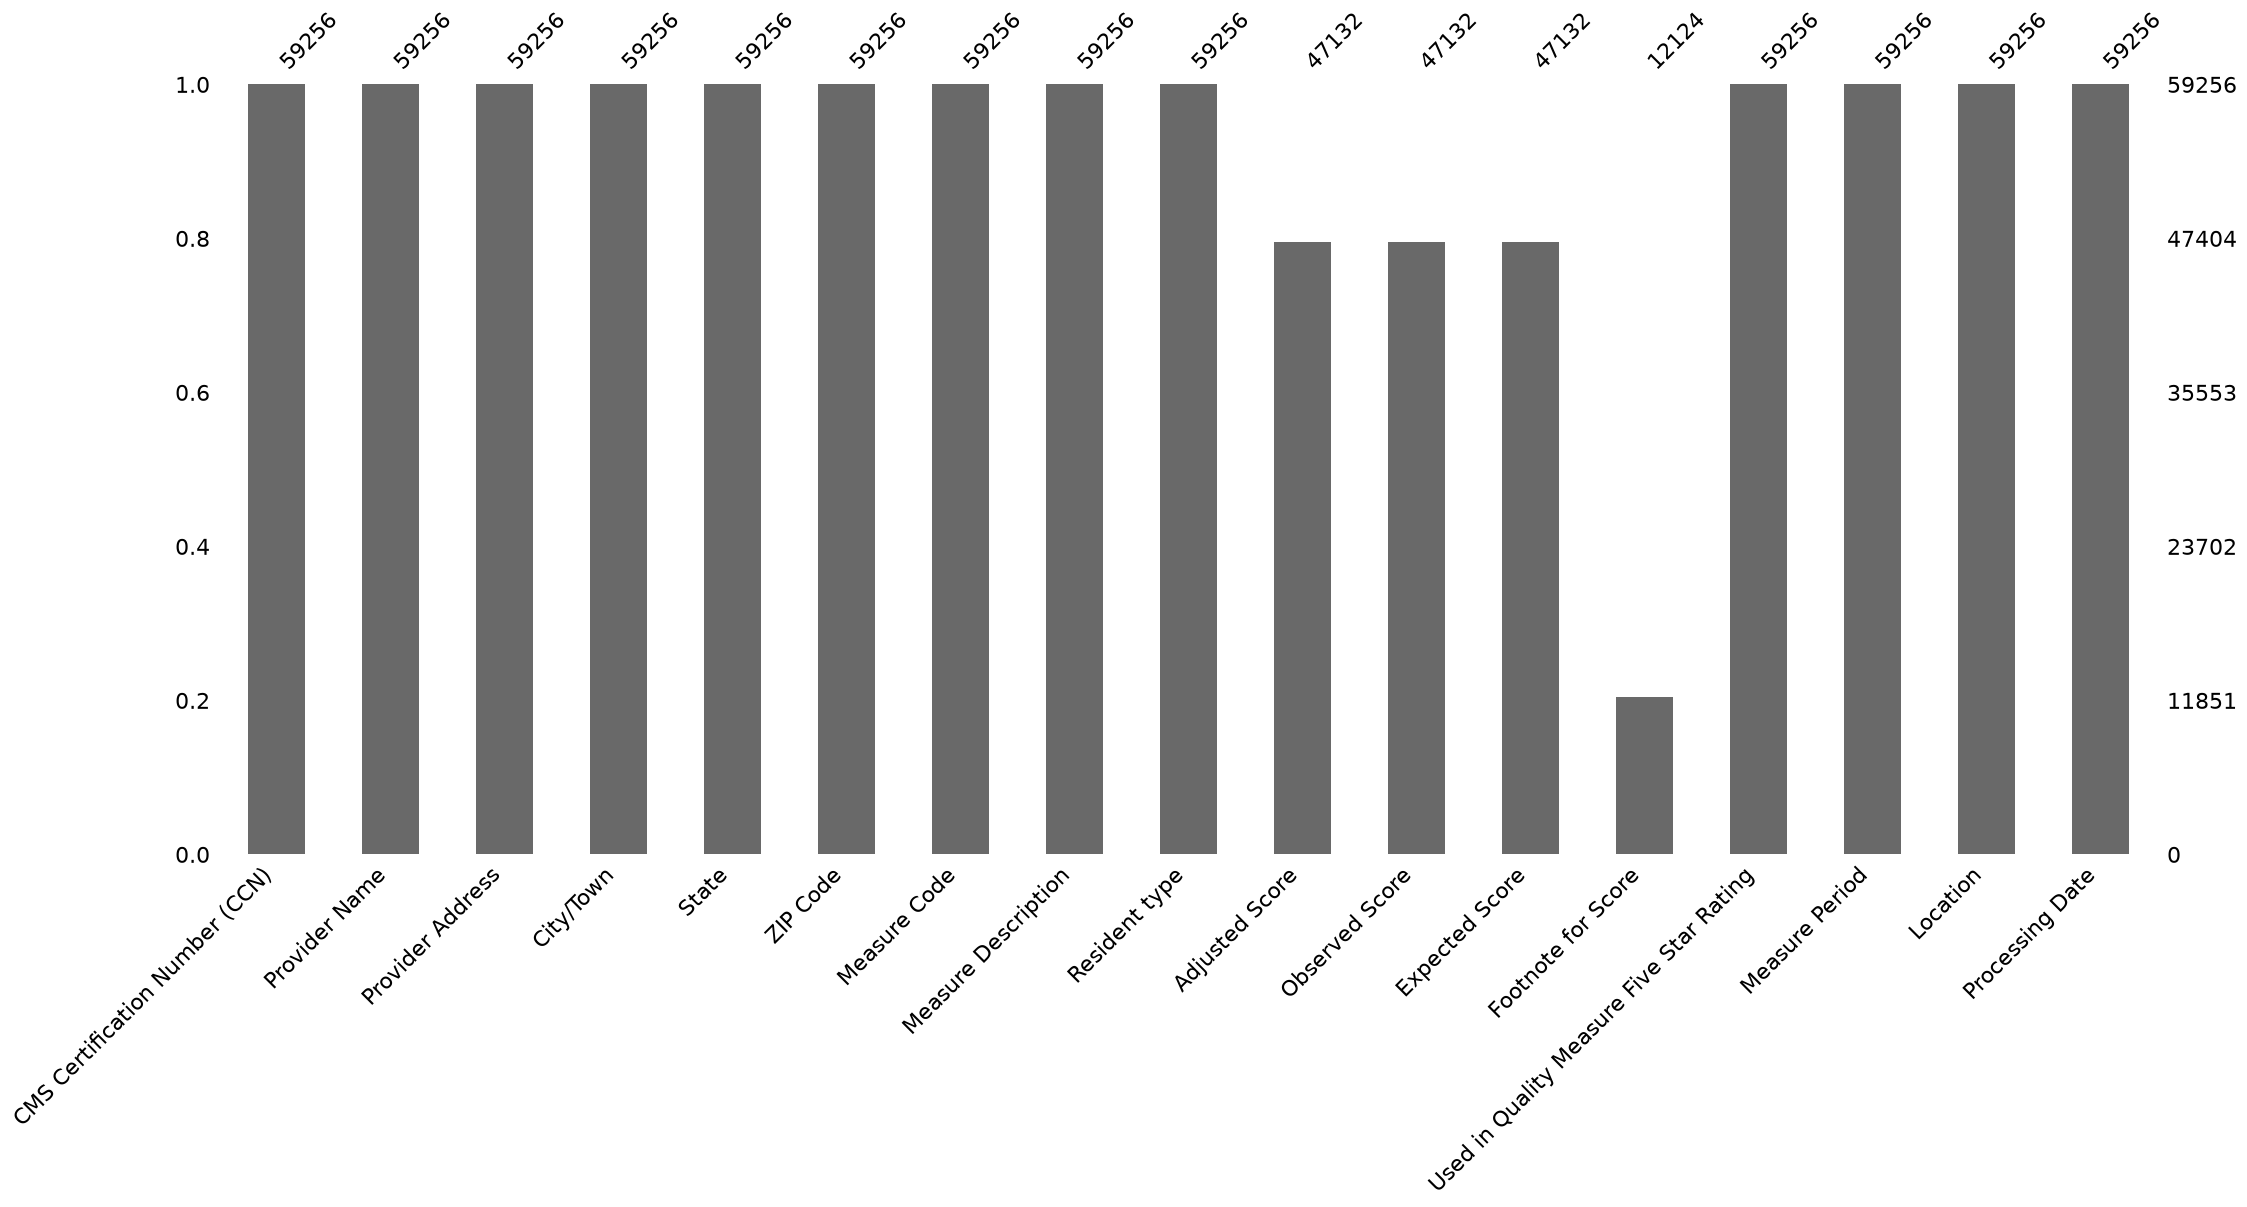

In [143]:
# Null Values
msno.bar(NH_QualityMsr_Claims_Oct2024)

In [144]:
# Duplicates
NH_QualityMsr_Claims_Oct2024_duplicates = NH_QualityMsr_Claims_Oct2024[NH_QualityMsr_Claims_Oct2024.duplicated()]
print(NH_QualityMsr_Claims_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Measure Code, Measure Description, Resident type, Adjusted Score, Observed Score, Expected Score, Footnote for Score, Used in Quality Measure Five Star Rating, Measure Period, Location, Processing Date]
Index: []


### MDS Quality Measures
- Quality Measures based on resident assessments that make up the nursing home Minimum Data Set (MDS).
- Each row contains a specific quality measure for a specific nursing home and includes the 4-quarter score average and scores for each individual quarter.

In [145]:
NH_QualityMsr_MDS_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Measure Code,Measure Description,Resident type,Q1 Measure Score,Footnote for Q1 Measure Score,Q2 Measure Score,Footnote for Q2 Measure Score,Q3 Measure Score,Footnote for Q3 Measure Score,Q4 Measure Score,Footnote for Q4 Measure Score,Four Quarter Average Score,Footnote for Four Quarter Average Score,Used in Quality Measure Five Star Rating,Measure Period,Location,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,401,Percentage of long-stay residents whose need for help with daily activities has increased,Long Stay,4.347830,NaN,6.666667,NaN,11.363636,NaN,6.976744,NaN,7.303372,NaN,Y,2022Q4-2023Q3,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
1,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,404,Percentage of long-stay residents who lose too much weight,Long Stay,2.325581,NaN,0.000000,NaN,5.000000,NaN,14.285714,NaN,5.389222,NaN,N,2023Q3-2024Q2,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
2,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,405,Percentage of low risk long-stay residents who lose control of their bowels or bladder,Long Stay,NaN,9.0,NaN,9.0,NaN,9.0,NaN,9.0,56.451613,NaN,N,2022Q4-2023Q3,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
3,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,406,Percentage of long-stay residents with a catheter inserted and left in their bladder,Long Stay,2.594192,NaN,3.924880,NaN,3.584012,NaN,4.926641,NaN,3.758490,NaN,Y,2023Q3-2024Q2,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01
4,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,407,Percentage of long-stay residents with a urinary tract infection,Long Stay,0.000000,NaN,0.000000,NaN,0.000000,NaN,2.173913,NaN,0.561798,NaN,Y,2023Q3-2024Q2,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653",2024-10-01


In [146]:
NH_QualityMsr_MDS_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 266652 entries, 0 to 266651
Data columns (total 23 columns):
 #   Column                                    Non-Null Count   Dtype  
---  ------                                    --------------   -----  
 0   CMS Certification Number (CCN)            266652 non-null  object 
 1   Provider Name                             266652 non-null  str    
 2   Provider Address                          266652 non-null  str    
 3   City/Town                                 266652 non-null  str    
 4   State                                     266652 non-null  str    
 5   ZIP Code                                  266652 non-null  int64  
 6   Measure Code                              266652 non-null  int64  
 7   Measure Description                       266652 non-null  str    
 8   Resident type                             266652 non-null  str    
 9   Q1 Measure Score                          227817 non-null  float64
 10  Footnote for Q1 Measure Score  

<Axes: >

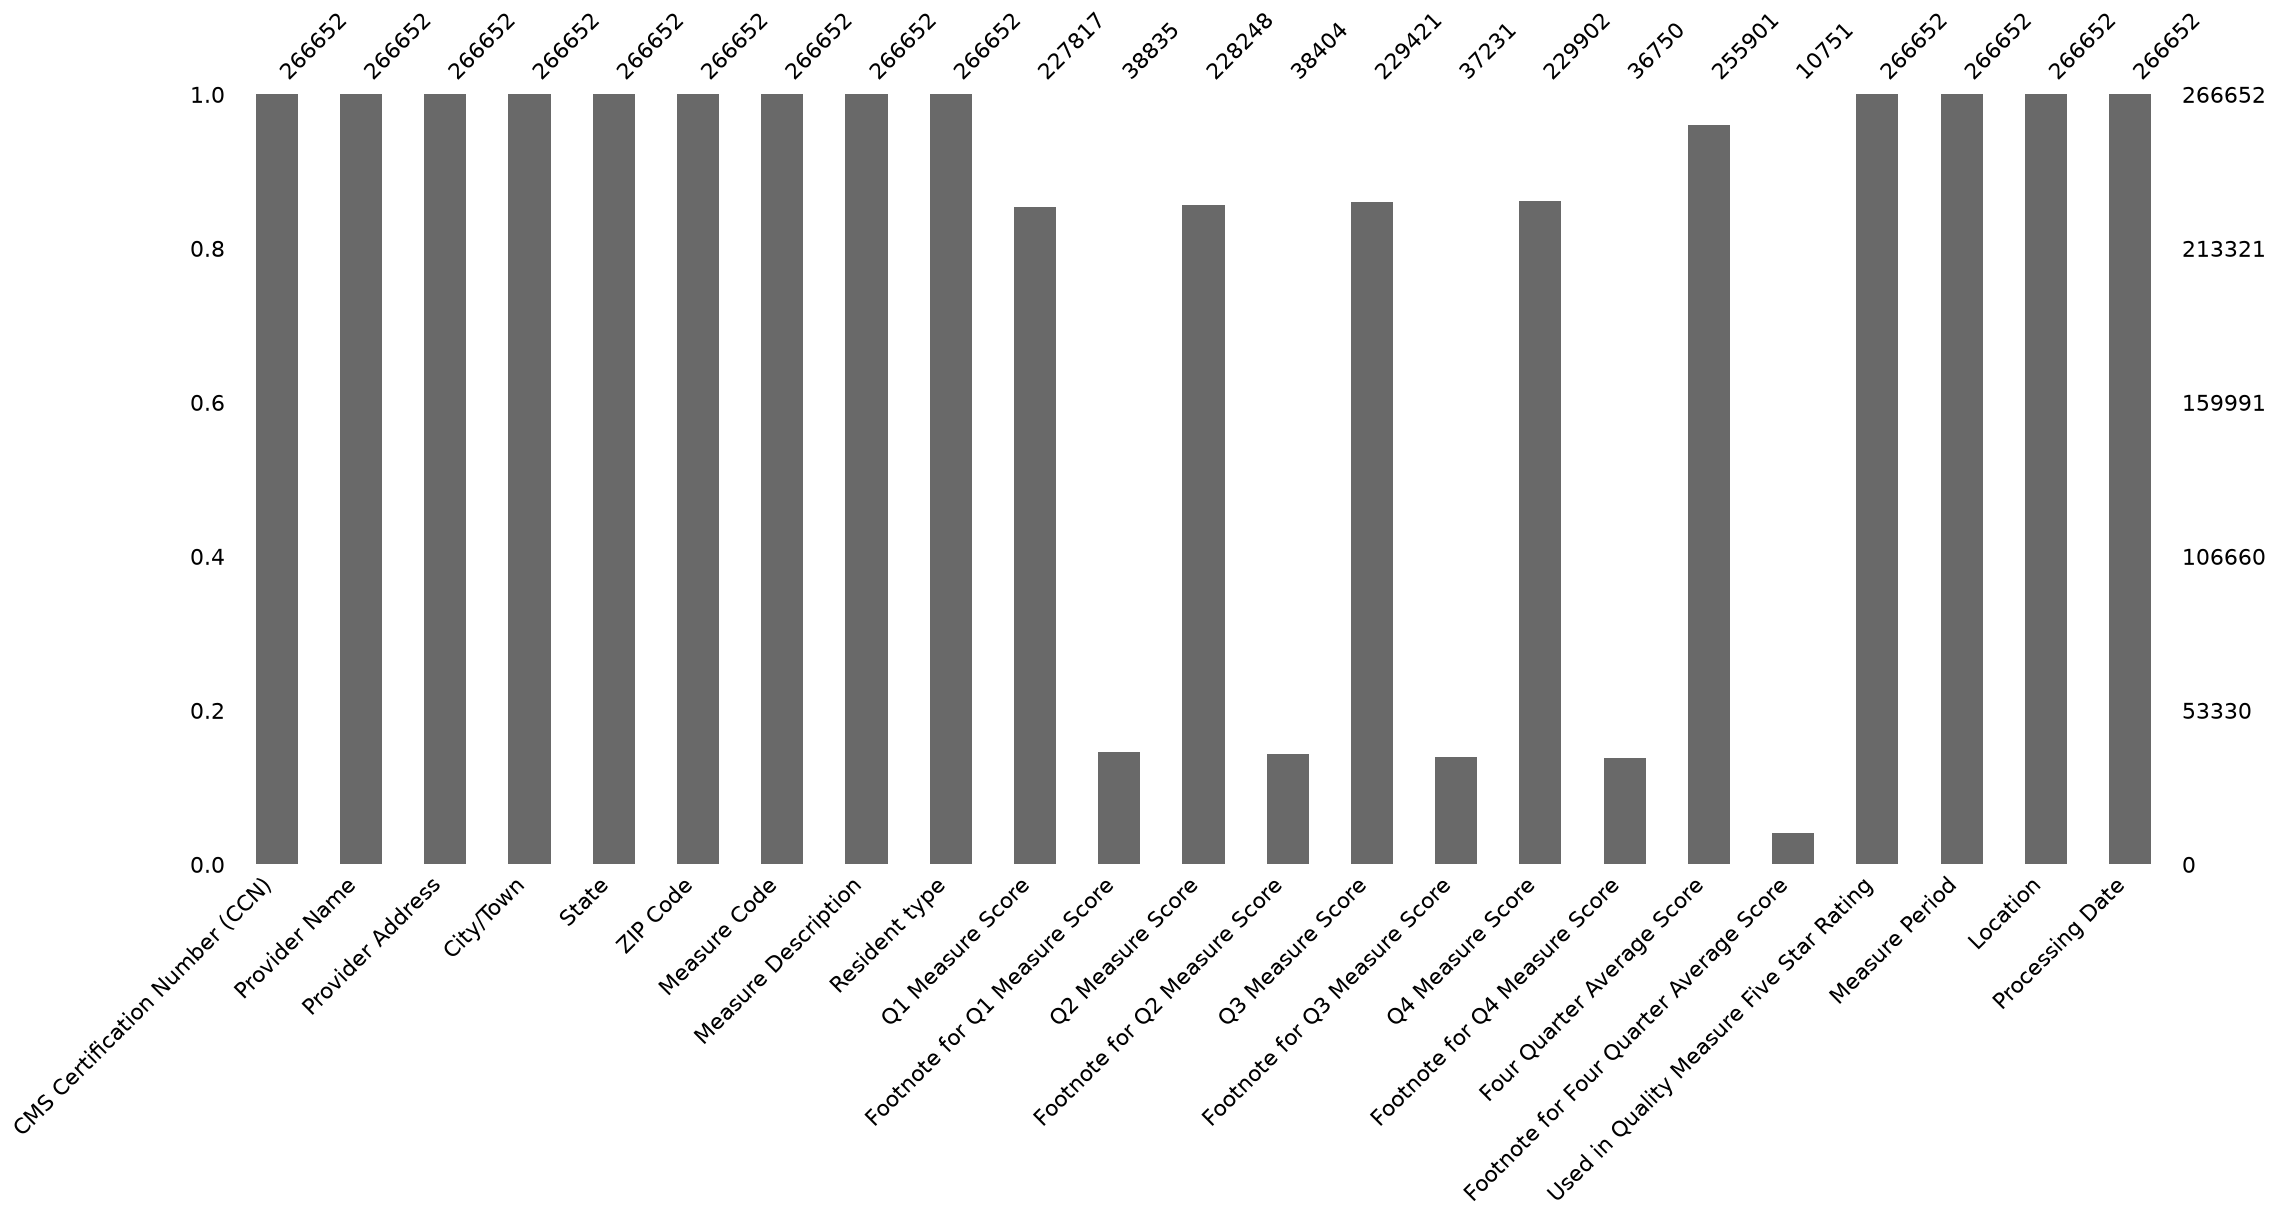

In [147]:
# Null Values
msno.bar(NH_QualityMsr_MDS_Oct2024)

In [148]:
# Duplicates
NH_QualityMsr_MDS_Oct2024_duplicates = NH_QualityMsr_MDS_Oct2024[NH_QualityMsr_MDS_Oct2024.duplicated()]
print(NH_QualityMsr_MDS_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Measure Code, Measure Description, Resident type, Q1 Measure Score, Footnote for Q1 Measure Score, Q2 Measure Score, Footnote for Q2 Measure Score, Q3 Measure Score, Footnote for Q3 Measure Score, Q4 Measure Score, Footnote for Q4 Measure Score, Four Quarter Average Score, Footnote for Four Quarter Average Score, Used in Quality Measure Five Star Rating, Measure Period, Location, Processing Date]
Index: []


In [149]:
NH_QualityMsr_MDS_Oct2024['Measure Description'].value_counts()

Measure Description
Percentage of long-stay residents whose need for help with daily activities has increased                      14814
Percentage of long-stay residents who lose too much weight                                                     14814
Percentage of low risk long-stay residents who lose control of their bowels or bladder                         14814
Percentage of long-stay residents with a catheter inserted and left in their bladder                           14814
Percentage of long-stay residents with a urinary tract infection                                               14814
Percentage of long-stay residents who have depressive symptoms                                                 14814
Percentage of long-stay residents who were physically restrained                                               14814
Percentage of long-stay residents experiencing one or more falls with major injury                             14814
Percentage of long-stay residents assessed a

### State US Averages
- Variety of state/territory averages as well as the national average.
- Each row displays a specific state/territory

In [150]:
NH_StateUSAverages_Oct2024.head()

,State or Nation,Cycle 1 Total Number of Health Deficiencies,Cycle 1 Total Number of Fire Safety Deficiencies,Cycle 2 Total Number of Health Deficiencies,Cycle 2 Total Number of Fire Safety Deficiencies,Cycle 3 Total Number of Health Deficiencies,Cycle 3 Total Number of Fire Safety Deficiencies,Average Number of Residents per Day,Reported Nurse Aide Staffing Hours per Resident per Day,Reported LPN Staffing Hours per Resident per Day,Reported RN Staffing Hours per Resident per Day,Reported Licensed Staffing Hours per Resident per Day,Reported Total Nurse Staffing Hours per Resident per Day,Total number of nurse staff hours per resident per day on the weekend,Registered Nurse hours per resident per day on the weekend,Reported Physical Therapist Staffing Hours per Resident Per Day,Total nursing staff turnover,Registered Nurse turnover,Number of administrators who have left the nursing home,Nursing Case-Mix Index,Case-Mix RN Staffing Hours per Resident per Day,Case-Mix Total Nurse Staffing Hours per Resident per Day,Case-Mix Weekend Total Nurse Staffing Hours per Resident per Day,Number of Fines,Fine Amount in Dollars,Percentage of long stay residents whose need for help with daily activities has increased,Percentage of long stay residents who lose too much weight,Percentage of low risk long stay residents who lose control of their bowels or bladder,Percentage of long stay residents with a catheter inserted and left in their bladder,Percentage of long stay residents with a urinary tract infection,Percentage of long stay residents who have depressive symptoms,Percentage of long stay residents who were physically restrained,Percentage of long stay residents experiencing one or more falls with major injury,Percentage of long stay residents assessed and appropriately given the pneumococcal vaccine,Percentage of long stay residents who received an antipsychotic medication,Percentage of short stay residents assessed and appropriately given the pneumococcal vaccine,Percentage of short stay residents who newly received an antipsychotic medication,Percentage of long stay residents whose ability to move independently worsened,Percentage of long stay residents who received an antianxiety or hypnotic medication,Percentage of high risk long stay residents with pressure ulcers,Percentage of long stay residents assessed and appropriately given the seasonal influenza vaccine,Percentage of short stay residents who made improvements in function,Percentage of short stay residents who were assessed and appropriately given the seasonal influenza vaccine,Percentage of short stay residents who were rehospitalized after a nursing home admission,Percentage of short stay residents who had an outpatient emergency department visit,Number of hospitalizations per 1000 long-stay resident days,Number of outpatient emergency department visits per 1000 long-stay resident days,Processing Date
0,NATION,9.6,4.9,9.1,4.4,8.5,4.3,83.0,2.29,0.88,0.66807,1.55,3.83737,3.35315,0.46,0.07,48.8,45.5,0.6,1.35608,0.66435,3.81602,3.33449,1.7,37827,14.132348,5.807649,48.549600,1.287765,2.004204,9.136920,0.136807,3.337443,92.984238,14.685128,81.070836,1.700488,15.334538,19.828867,7.846335,94.947460,76.757423,77.321025,23.151112,12.214090,1.720334,1.652897,2024-10-01
1,AK,7.6,4.2,8.2,6.8,9.4,7.8,36.8,4.22,0.72,2.15047,2.87,7.09344,6.13148,1.57,0.08,46.7,42.2,0.3,1.29826,0.63958,3.67374,3.21017,1.8,32939,13.842748,6.526337,41.663249,1.432569,2.792480,4.575546,0.078947,4.526830,97.077573,17.658815,83.760546,0.795490,18.366430,16.622294,8.928272,97.887033,80.852506,74.512346,19.018400,13.303430,1.123771,1.498826,2024-10-01
2,AL,3.4,3.4,3.0,3.3,3.8,3.2,95.7,2.46,0.81,0.60125,1.41,3.86755,3.19727,0.33,0.04,49.1,42.1,0.5,1.23276,0.60731,3.48840,3.04821,0.8,11855,12.178572,6.162245,42.857826,1.555861,3.057801,1.052061,0.621200,3.304975,92.903004,20.510545,83.486173,2.008615,14.095574,24.252409,8.577385,94.932438,75.129261,79.413377,24.393145,12.955037,1.788046,1.649544,2024-10-01
3,AR,8.0,

In [151]:
NH_StateUSAverages_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 48 columns):
 #   Column                                                                                                       Non-Null Count  Dtype  
---  ------                                                                                                       --------------  -----  
 0   State or Nation                                                                                              54 non-null     str    
 1   Cycle 1 Total Number of Health Deficiencies                                                                  54 non-null     float64
 2   Cycle 1 Total Number of Fire Safety Deficiencies                                                             54 non-null     float64
 3   Cycle 2 Total Number of Health Deficiencies                                                                  54 non-null     float64
 4   Cycle 2 Total Number of Fire Safety Deficiencies                           

<Axes: >

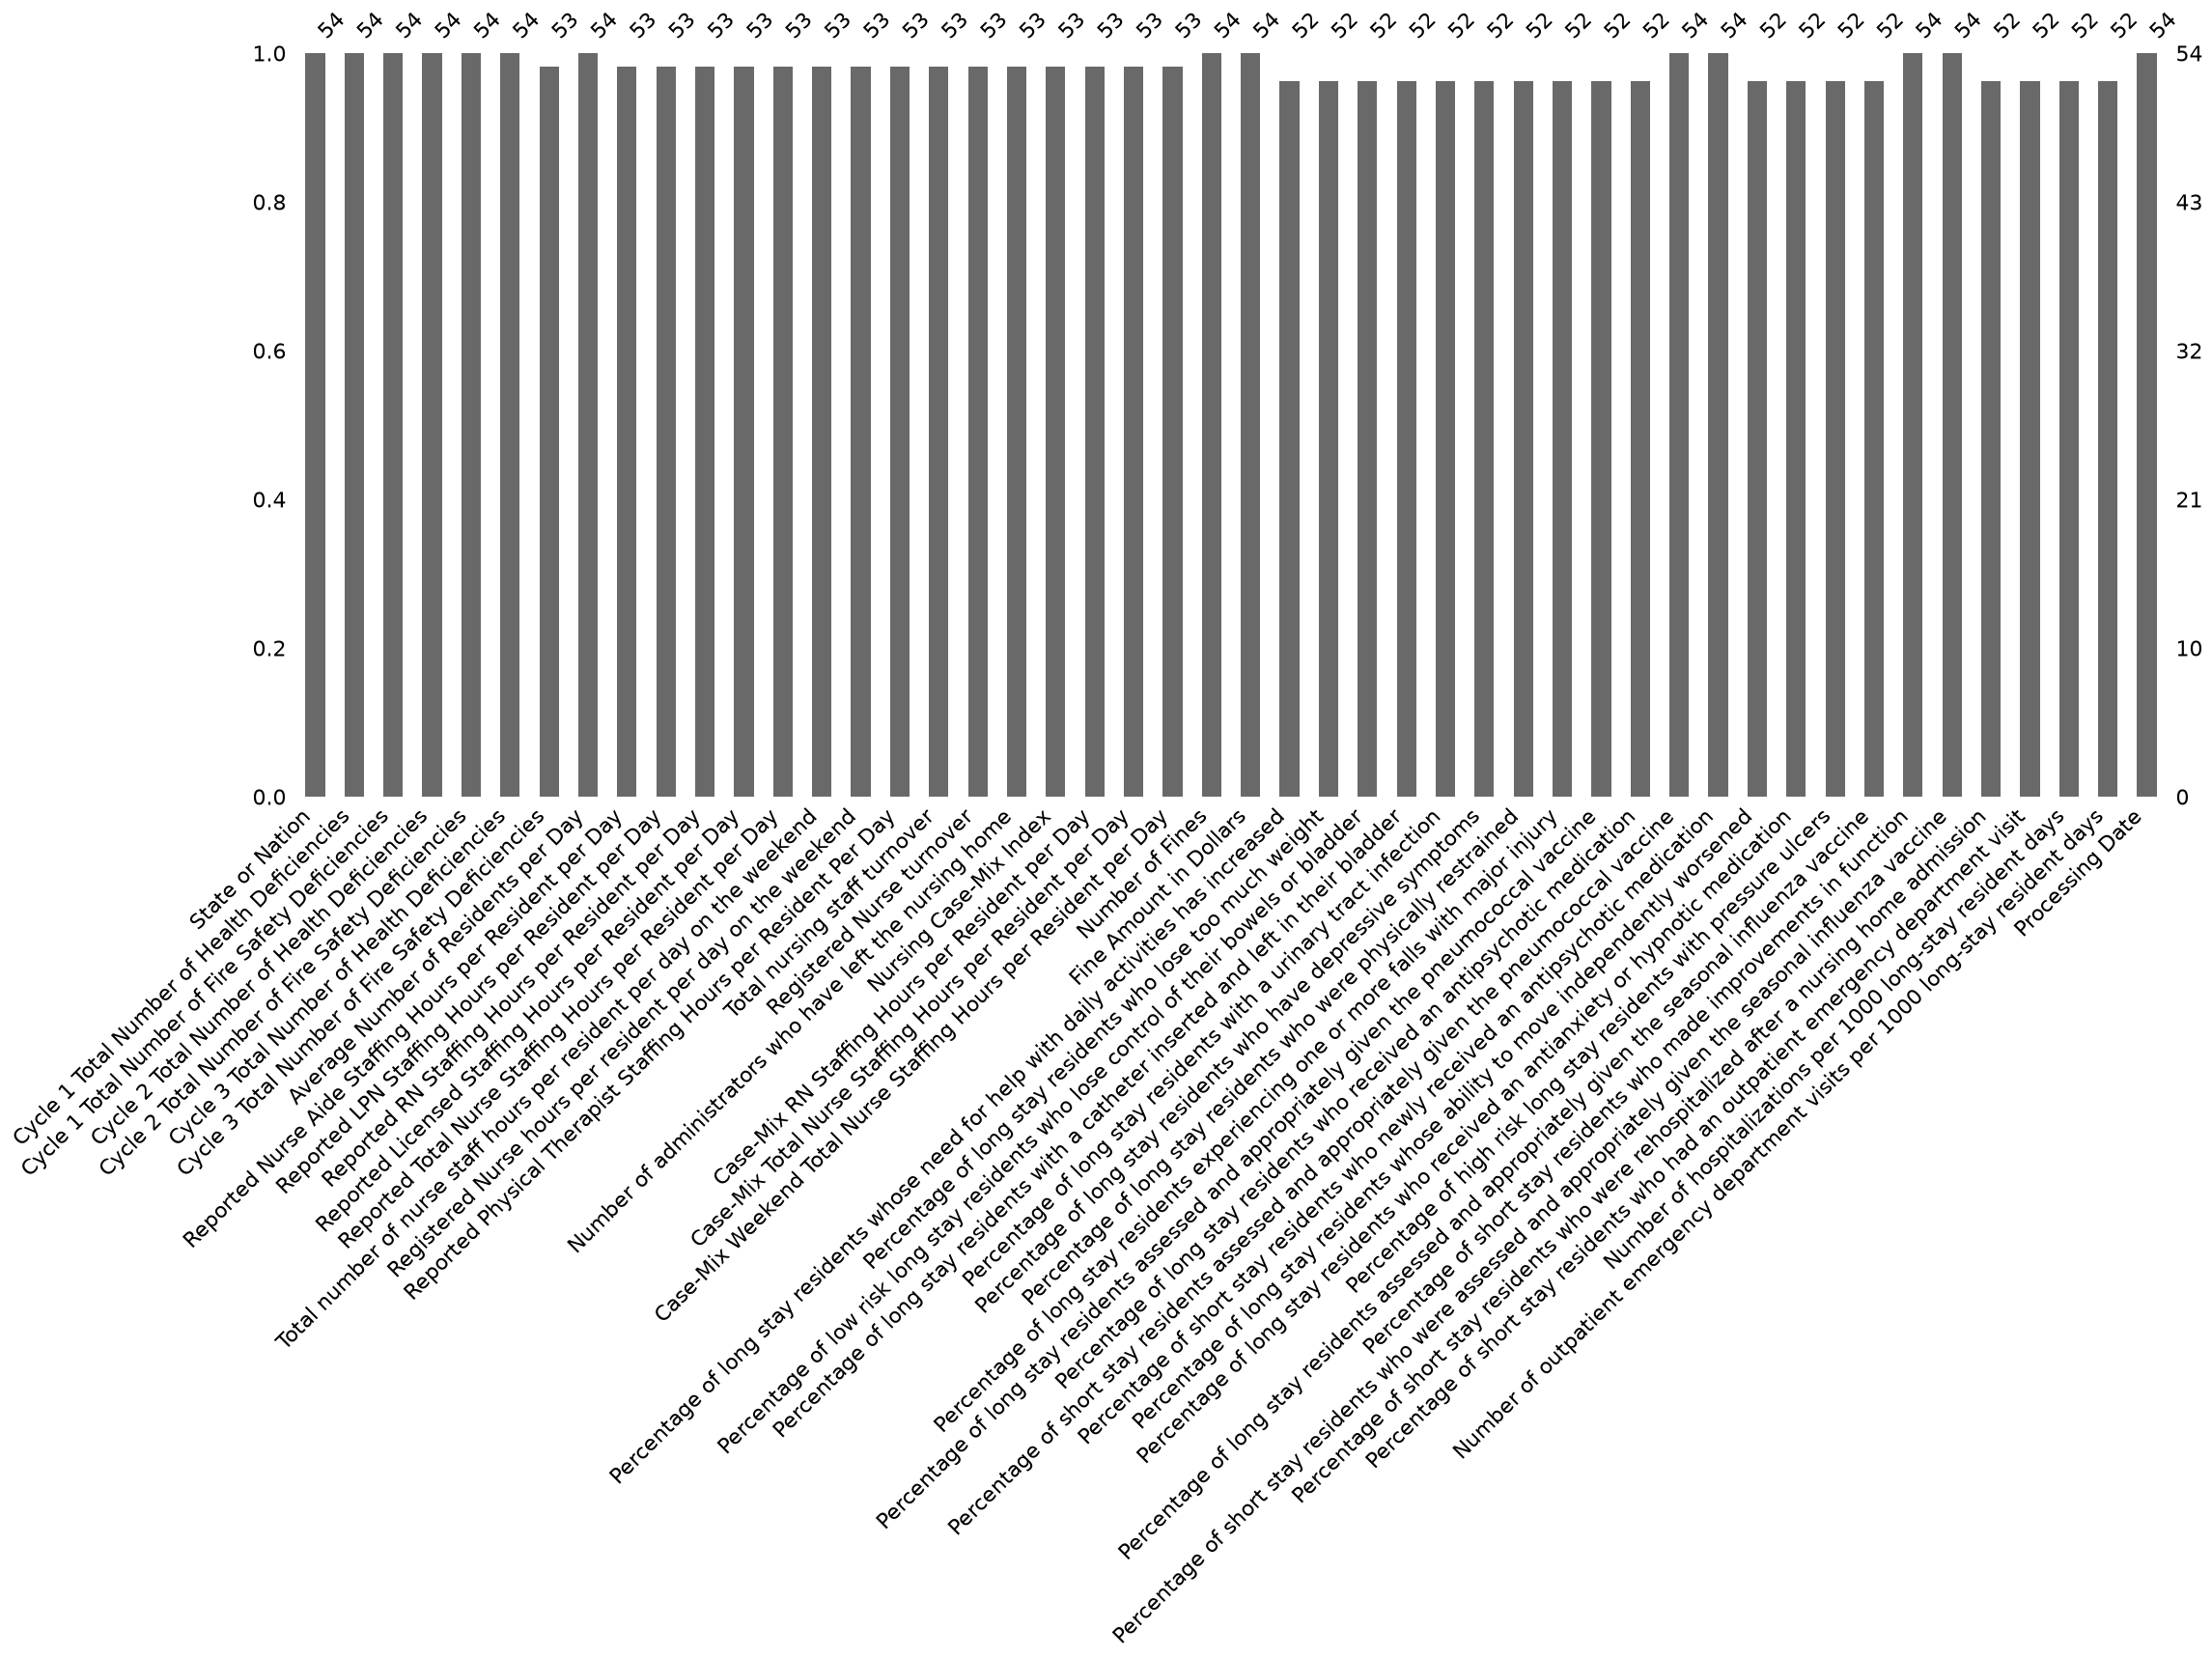

In [152]:
# Null Values
msno.bar(NH_StateUSAverages_Oct2024)

In [153]:
# Duplicates
NH_StateUSAverages_Oct2024_duplicates = NH_StateUSAverages_Oct2024[NH_StateUSAverages_Oct2024.duplicated()]
print(NH_StateUSAverages_Oct2024_duplicates)

Empty DataFrame
Columns: [State or Nation, Cycle 1 Total Number of Health Deficiencies, Cycle 1 Total Number of Fire Safety Deficiencies, Cycle 2 Total Number of Health Deficiencies, Cycle 2 Total Number of Fire Safety Deficiencies, Cycle 3 Total Number of Health Deficiencies, Cycle 3 Total Number of Fire Safety Deficiencies, Average Number of Residents per Day, Reported Nurse Aide Staffing Hours per Resident per Day, Reported LPN Staffing Hours per Resident per Day, Reported RN Staffing Hours per Resident per Day, Reported Licensed Staffing Hours per Resident per Day, Reported Total Nurse Staffing Hours per Resident per Day, Total number of nurse staff hours per resident per day on the weekend, Registered Nurse hours per resident per day on the weekend, Reported Physical Therapist Staffing Hours per Resident Per Day, Total nursing staff turnover, Registered Nurse turnover, Number of administrators who have left the nursing home, Nursing Case-Mix Index, Case-Mix RN Staffing Hours per R

In [154]:
# Pull any records with at least one null value
nulls_NH_StateUSAverages_Oct2024 = NH_StateUSAverages_Oct2024[NH_StateUSAverages_Oct2024.isnull().any(axis=1)]
print(nulls_NH_StateUSAverages_Oct2024)

   State or Nation  Cycle 1 Total Number of Health Deficiencies  \
12              GU                                         17.0   
41              PR                                         12.0   

    Cycle 1 Total Number of Fire Safety Deficiencies  \
12                                               1.0   
41                                              18.3   

    Cycle 2 Total Number of Health Deficiencies  \
12                                         17.0   
41                                          9.2   

    Cycle 2 Total Number of Fire Safety Deficiencies  \
12                                               6.0   
41                                               5.8   

    Cycle 3 Total Number of Health Deficiencies  \
12                                         20.0   
41                                          5.8   

    Cycle 3 Total Number of Fire Safety Deficiencies  \
12                                               8.0   
41                                      

### Inspection Dates
- Inspection dates in the past three years.
    - Inspection types include health, fire safety, complaints, and infection control.

In [155]:
NH_SurveyDates_Oct2024.head()

,CMS Certification Number (CCN),Survey Date,Type of Survey,Survey Cycle,Processing Date
0,015009,2023-03-02,Health Complaint,2,2024-10-01
1,015009,2023-03-02,Health Standard,1,2024-10-01
2,015009,2023-02-15,Fire Safety Standard,1,2024-10-01
3,015009,2019-08-21,Fire Safety Standard,2,2024-10-01
4,015009,2019-08-21,Health Standard,2,2024-10-01


In [156]:
NH_SurveyDates_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 159723 entries, 0 to 159722
Data columns (total 5 columns):
 #   Column                          Non-Null Count   Dtype
---  ------                          --------------   -----
 0   CMS Certification Number (CCN)  159723 non-null  str  
 1   Survey Date                     159723 non-null  str  
 2   Type of Survey                  159723 non-null  str  
 3   Survey Cycle                    159723 non-null  int64
 4   Processing Date                 159723 non-null  str  
dtypes: int64(1), str(4)
memory usage: 12.6 MB


<Axes: >

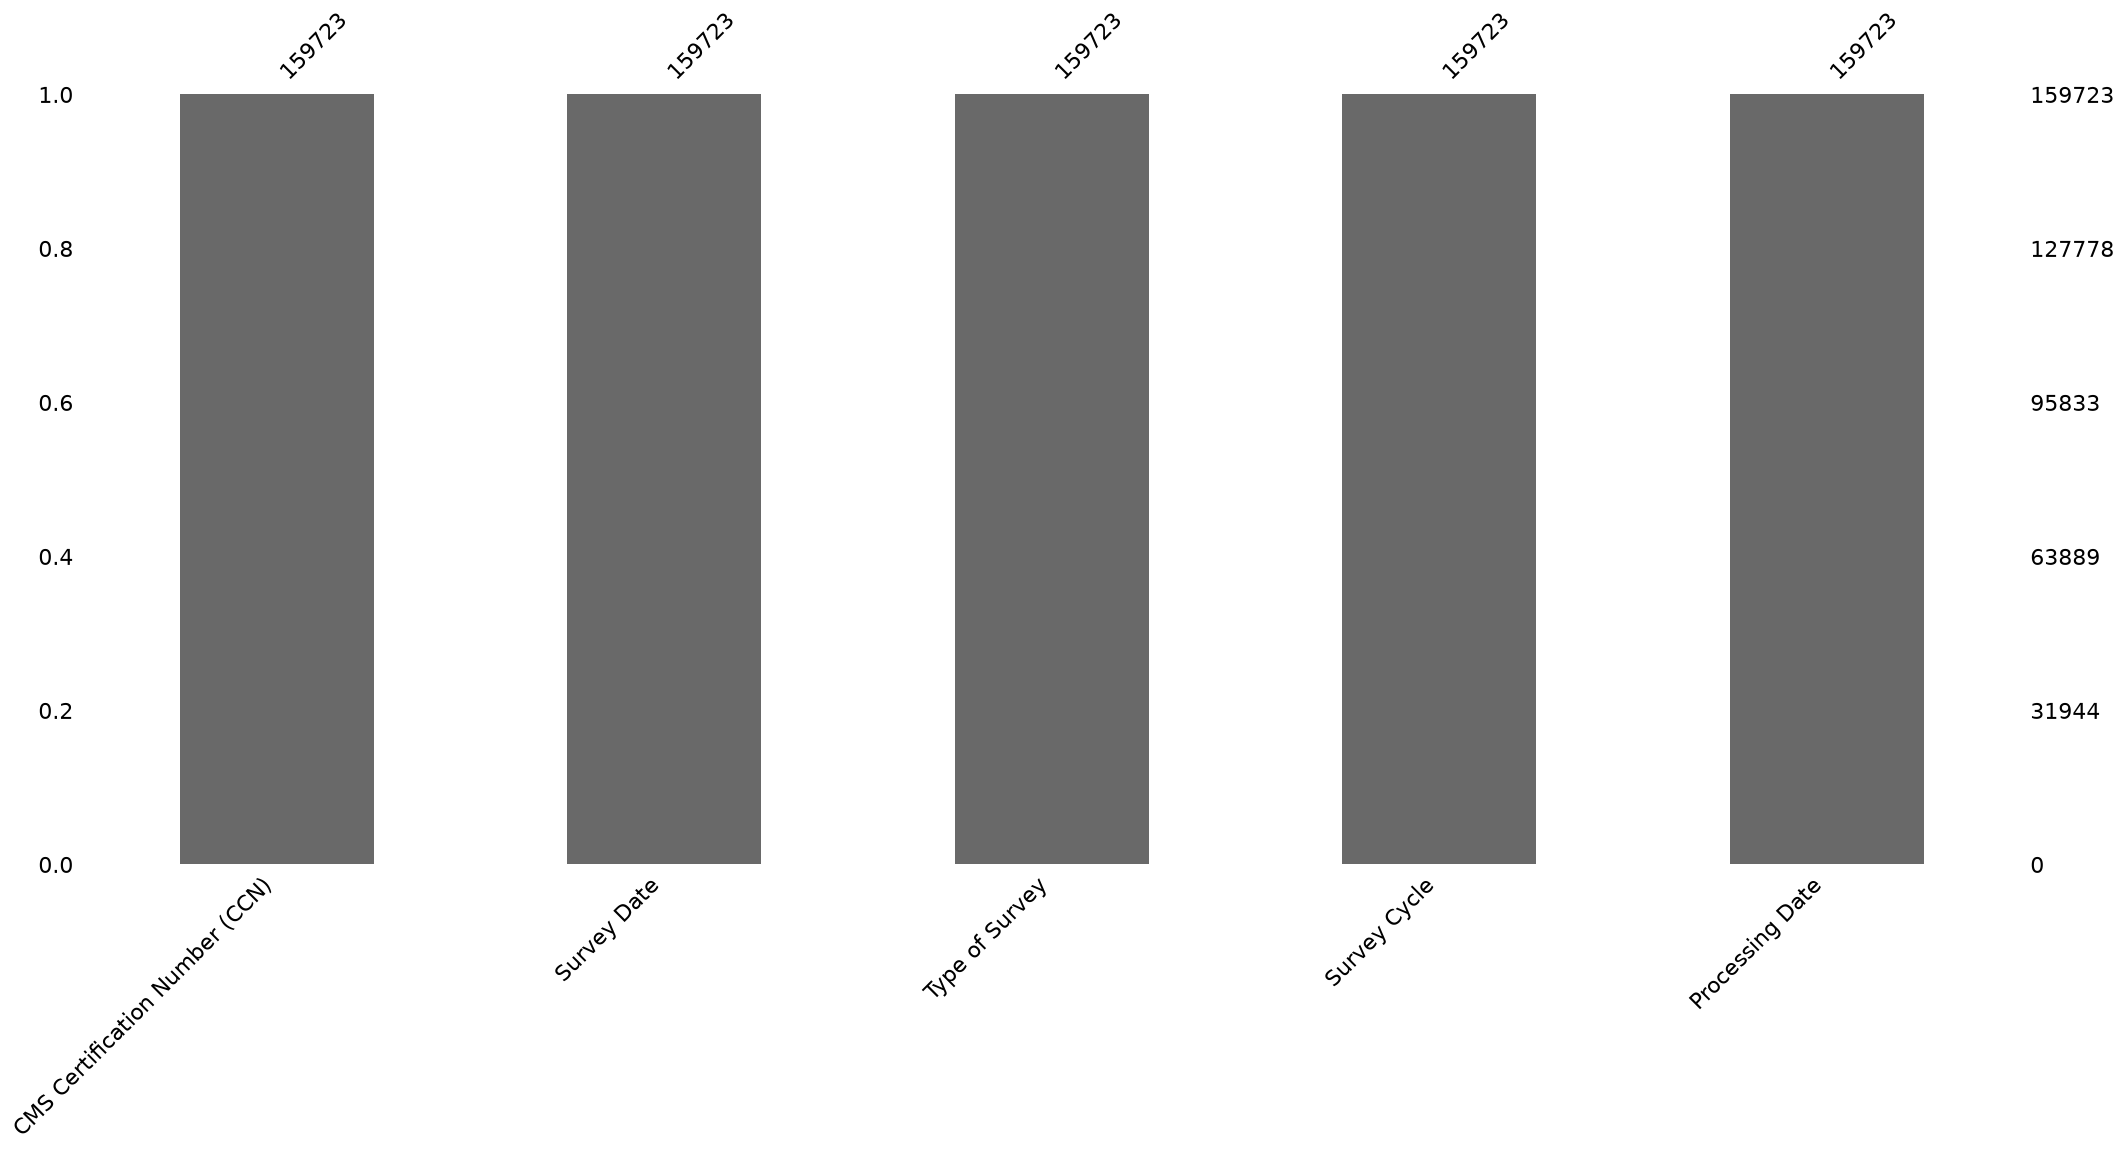

In [157]:
# Null Values
msno.bar(NH_SurveyDates_Oct2024)

In [158]:
# Duplicates
NH_SurveyDates_Oct2024_duplicates = NH_SurveyDates_Oct2024[NH_SurveyDates_Oct2024.duplicated()]
print(NH_SurveyDates_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Survey Date, Type of Survey, Survey Cycle, Processing Date]
Index: []


In [159]:
# Check on 'Type of Survey' columns for any non-registered null values
NH_SurveyDates_Oct2024["Type of Survey"].value_counts()

Type of Survey
Health Complaint         54640
Health Standard          44243
Fire Safety Standard     44210
Infection Control        16050
Fire Safety Complaint      580
Name: count, dtype: int64

In [160]:
# Check on 'Survey Cycle' columns for any non-registered null values
NH_SurveyDates_Oct2024["Survey Cycle"].value_counts()

Survey Cycle
3    57254
2    54010
1    48459
Name: count, dtype: int64

In [161]:
# Which facilities had the most inspections? 
inspection_counts = NH_SurveyDates_Oct2024["CMS Certification Number (CCN)"].value_counts()
print(inspection_counts.head(20))

CMS Certification Number (CCN)
056010    72
055293    67
555456    66
555852    66
555330    64
555738    63
555438    61
555583    59
056139    58
055870    57
056129    57
056487    57
056431    56
555256    56
056039    55
056333    55
055206    54
056334    54
555808    53
055376    51
Name: count, dtype: int64


### Survey Summary
- Nursing home summary info for nursing home health and fire safety inspections in the last three years.
    - Includes dates of the three most recent inspections (including those with no citations), and counts of citations, overall and within specified categories.
- Note: citation counts do not include citations from complaint inspections.

In [162]:
NH_SurveySummary_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Provider Address,City/Town,State,ZIP Code,Inspection Cycle,Health Survey Date,Fire Safety Survey Date,Total Number of Health Deficiencies,Total Number of Fire Safety Deficiencies,Count of Freedom from Abuse and Neglect and Exploitation Deficiencies,Count of Quality of Life and Care Deficiencies,Count of Resident Assessment and Care Planning Deficiencies,Count of Nursing and Physician Services Deficiencies,Count of Resident Rights Deficiencies,Count of Nutrition and Dietary Deficiencies,Count of Pharmacy Service Deficiencies,Count of Environmental Deficiencies,Count of Administration Deficiencies,Count of Infection Control Deficiencies,Count of Emergency Preparedness Deficiencies,Count of Automatic Sprinkler Systems Deficiencies,Count of Construction Deficiencies,Count of Services Deficiencies,Count of Corridor Walls and Doors Deficiencies,Count of Egress Deficiencies,Count of Electrical Deficiencies,Count of Emergency Plans and Fire Drills Deficiencies,Count of Fire Alarm Systems Deficiencies,Count of Smoke Deficiencies,Count of Interior Deficiencies,Count of Gas and Vacuum and Electrical Systems Deficiencies,Count of Hazardous Area Deficiencies,Count of Illumination and Emergency Power Deficiencies,Count of Laboratories Deficiencies,Count of Medical Gases and Anaesthetizing Areas Deficiencies,Count of Smoking Regulations Deficiencies,Count of Miscellaneous Deficiencies,Location,Processing Date
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,1,2023-03-02,2023-02-15,4,6.0,0,1,1,0,0,0,0,0,1,1,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
1,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,2,2019-08-21,2019-08-21,2,0.0,0,0,0,0,1,0,0,0,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
2,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,3,2018-08-01,2018-08-09,1,2.0,0,0,0,0,0,0,0,0,0,1,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653",2024-10-01
3,015010,COOSA VALLEY HEALTHCARE CENTER,260 WEST WALNUT STREET,SYLACAUGA,AL,35150,1,2022-04-09,2022-04-13,0,3.0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"260 WEST WALNUT STREET,SYLACAUGA,AL,35150",2024-10-01
4,015010,COOSA VALLEY HEALTHCARE CENTER,260 WEST WALNUT STREET,SYLACAUGA,AL,35150,2,2019-06-13,2019-06-18,1,4.0,0,0,0,0,0,0,0,0,0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,"260 WEST WALNUT STREET,SYLACAUGA,AL,35150",2024-10-01


In [163]:
NH_SurveySummary_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 44243 entries, 0 to 44242
Data columns (total 41 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   CMS Certification Number (CCN)                                         44243 non-null  str    
 1   Provider Name                                                          44243 non-null  str    
 2   Provider Address                                                       44243 non-null  str    
 3   City/Town                                                              44243 non-null  str    
 4   State                                                                  44243 non-null  str    
 5   ZIP Code                                                               44243 non-null  int64  
 6   Inspection Cycle                                                       44243 non-null  int64  
 7

<Axes: >

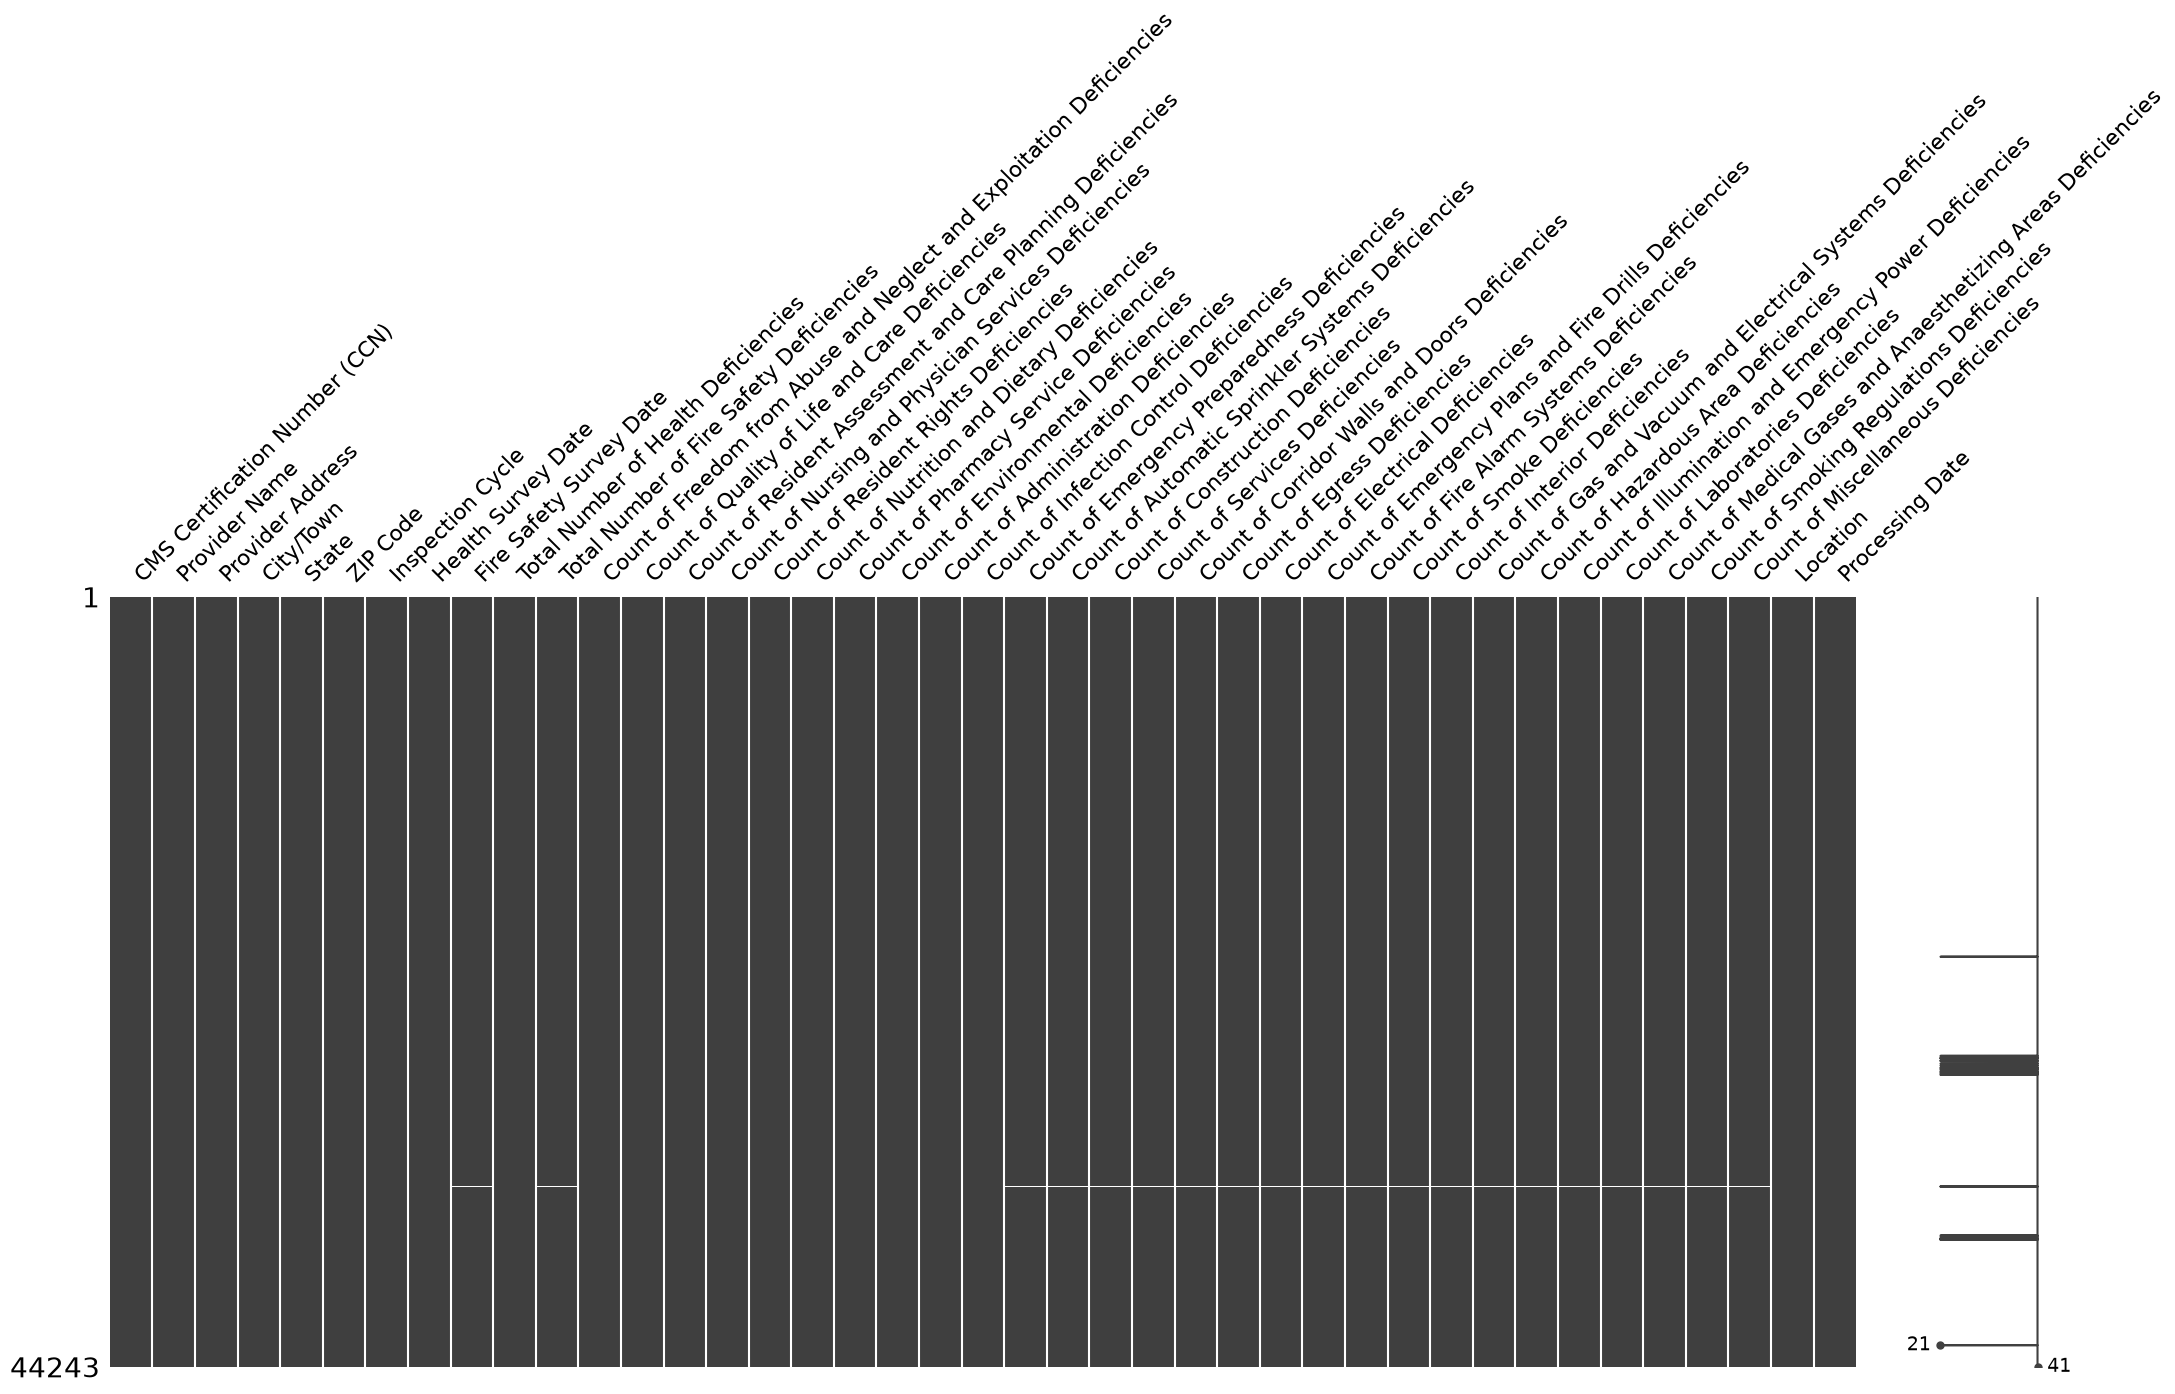

In [164]:
# Null Values
msno.matrix(NH_SurveySummary_Oct2024)

In [165]:
# Duplicates
NH_SurveySummary_Oct2024_duplicates = NH_SurveySummary_Oct2024[NH_SurveySummary_Oct2024.duplicated()]
print(NH_SurveySummary_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Provider Address, City/Town, State, ZIP Code, Inspection Cycle, Health Survey Date, Fire Safety Survey Date, Total Number of Health Deficiencies, Total Number of Fire Safety Deficiencies, Count of Freedom from Abuse and Neglect and Exploitation Deficiencies, Count of Quality of Life and Care Deficiencies, Count of Resident Assessment and Care Planning Deficiencies, Count of Nursing and Physician Services Deficiencies, Count of Resident Rights Deficiencies, Count of Nutrition and Dietary Deficiencies, Count of Pharmacy Service Deficiencies, Count of Environmental Deficiencies, Count of Administration Deficiencies, Count of Infection Control Deficiencies, Count of Emergency Preparedness Deficiencies, Count of Automatic Sprinkler Systems Deficiencies, Count of Construction Deficiencies, Count of Services Deficiencies, Count of Corridor Walls and Doors Deficiencies, Count of Egress Deficiencies, Count of Electrical De

### Skilled Nursing Facility Quality Reporting Program (SNF QRP) – National Data
- Skilled Nursing Facilities (SNFs) provide Medicare Part A SNF services to beneficiaries and must report data on certain measures of quality to Medicare through the Skilled Nursing Facility Quality Reporting Program (SNF QRP).
- Contains national averages on quality measures implemented under the IMPACT Act.

In [166]:
Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024.head(25)

,CMS Certification Number (CCN),Measure Code,Score,Footnote,Start Date,End Date,Measure Date Range
0,NATION,S_004_01_PPR_PD_NAT_UNADJUST_AVG,10.51,-,10/01/2021,09/30/2023,-
1,NATION,S_004_01_PPR_PD_N_BETTER_NAT,93.00,-,10/01/2021,09/30/2023,-
2,NATION,S_004_01_PPR_PD_N_NO_DIFF_NAT,12962.00,-,10/01/2021,09/30/2023,-
3,NATION,S_004_01_PPR_PD_N_TOO_SMALL,1630.00,-,10/01/2021,09/30/2023,-
4,NATION,S_004_01_PPR_PD_N_WORSE_NAT,360.00,-,10/01/2021,09/30/2023,-
5,NATION,S_005_02_DTC_NAT_OBS_RATE,49.90,-,10/01/2021,09/30/2023,-
6,NATION,S_005_02_DTC_N_BETTER_NAT,3014.00,-,10/01/2021,09/30/2023,-
7,NATION,S_005_02_DTC_N_NO_DIFF_NAT,7878.00,-,10/01/2021,09/30/2023,-
8,NATION,S_005_02_DTC_N_TOO_SMALL,2699.00,-,10/01/2021,09/30/2023,-
9,NATION,S_005_02_DTC_N_WORSE_NAT,1366.00,-,10/01/2021,09/30/2023,-


In [167]:
Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   CMS Certification Number (CCN)  24 non-null     str    
 1   Measure Code                    24 non-null     str    
 2   Score                           24 non-null     float64
 3   Footnote                        24 non-null     str    
 4   Start Date                      24 non-null     str    
 5   End Date                        24 non-null     str    
 6   Measure Date Range              24 non-null     str    
dtypes: float64(1), str(6)
memory usage: 2.7 KB


<Axes: >

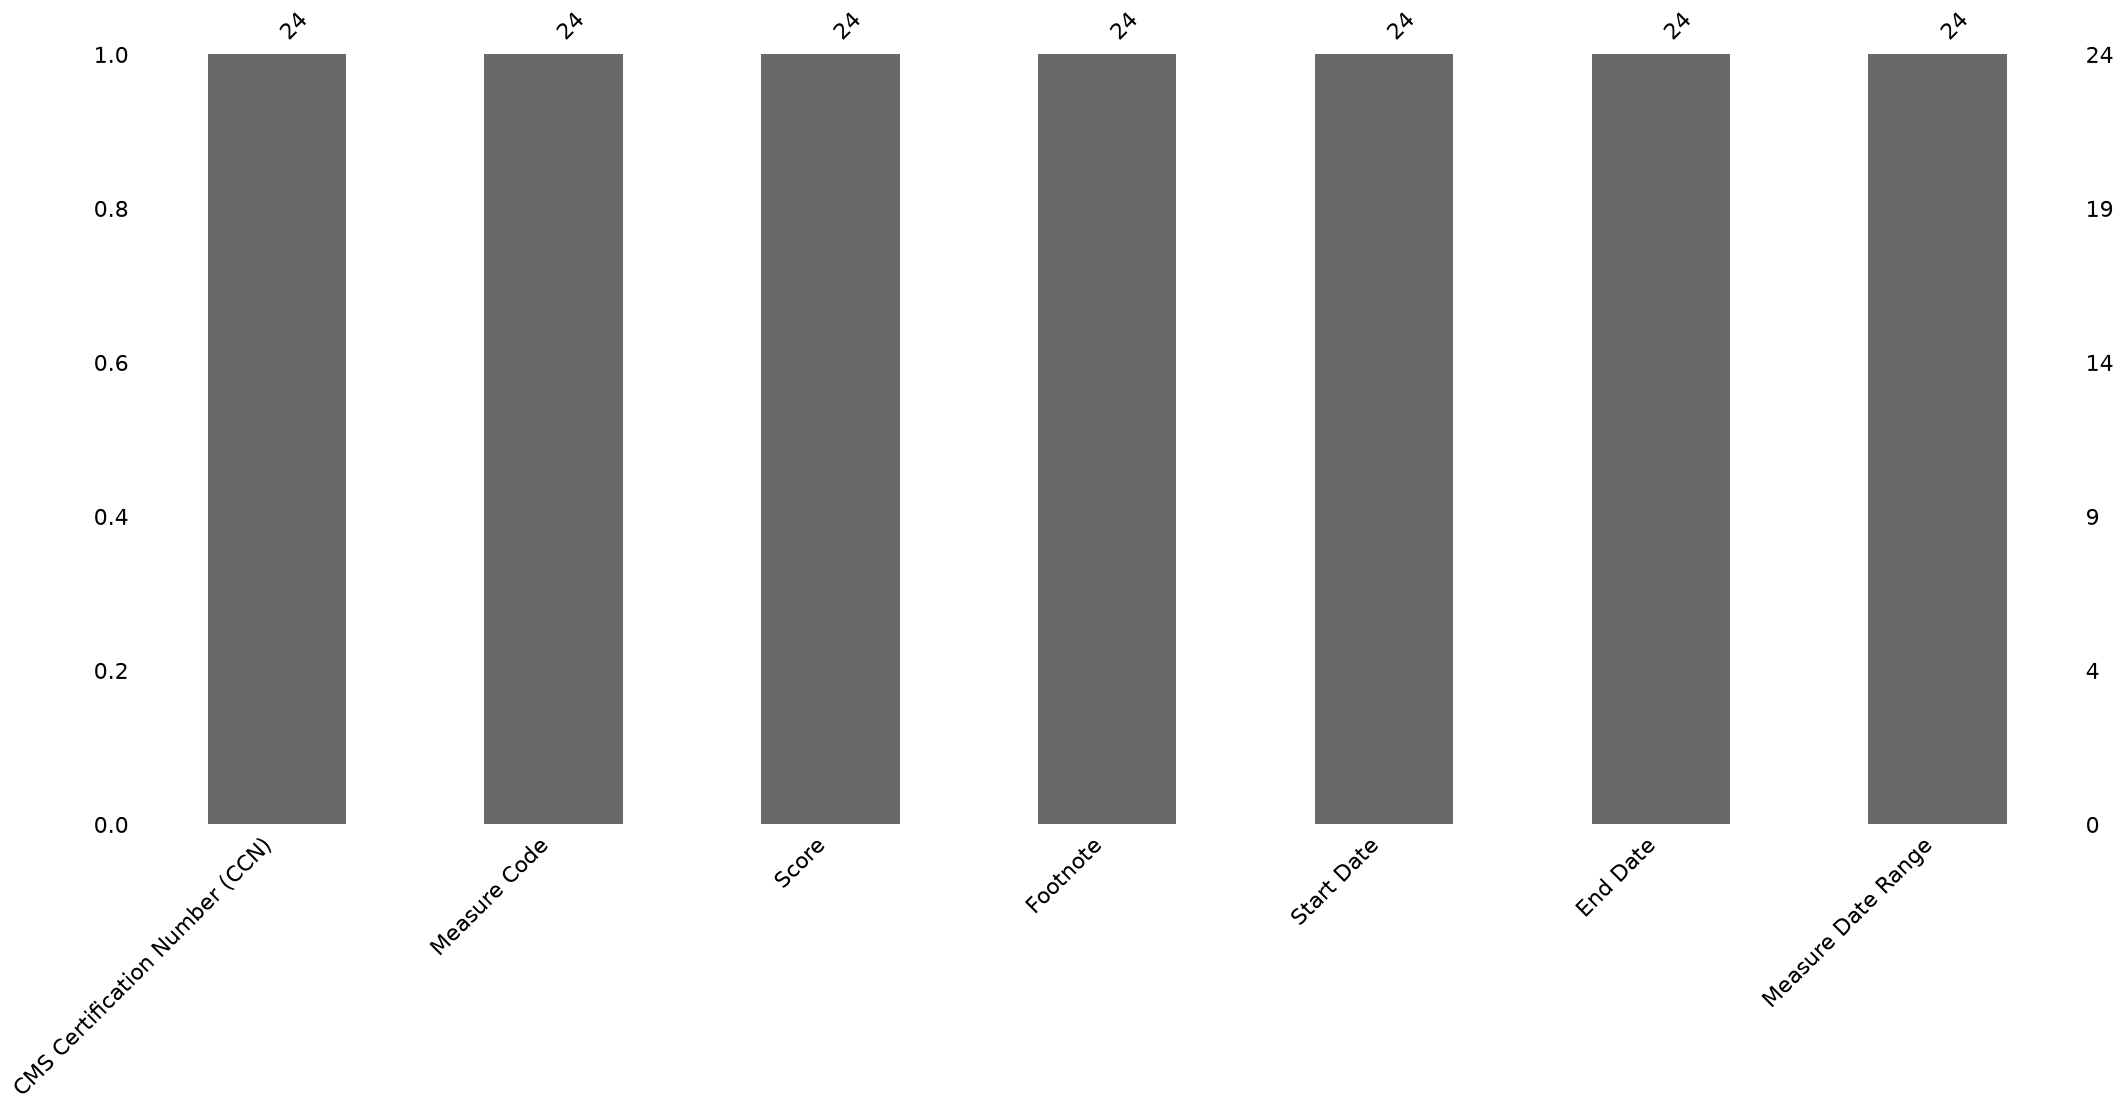

In [168]:
# Null Values
msno.bar(Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024)

In [169]:
# Duplicates
Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024_duplicates = Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024[Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024.duplicated()]
print(Skilled_Nursing_Facility_Quality_Reporting_Program_National_Data_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Measure Code, Score, Footnote, Start Date, End Date, Measure Date Range]
Index: []


### Skilled Nursing Facility Quality Reporting Program (SNF QRP) – Provider Data
- Skilled Nursing Facilities (SNFs) provide Medicare Part A SNF services to beneficiaries and must report data on certain measures of quality to Medicare through the Skilled Nursing Facility Quality Reporting Program (SNF QRP).
- Contains SNFs and their results on the quality of resident care measures implemented under the IMPACT Act.

In [170]:
Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Address Line 1,City/Town,State,ZIP Code,County/Parish,Telephone Number,CMS Region,Measure Code,Score,Footnote,Start Date,End Date,Measure Date Range,LOCATION1
0,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,Franklin,(256)332-4110,4,S_004_01_PPR_PD_COMP_PERF,No Different than the National Rate,-,10/01/2021,09/30/2023,-,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653"
1,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,Franklin,(256)332-4110,4,S_004_01_PPR_PD_OBS,5.38,-,10/01/2021,09/30/2023,-,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653"
2,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,Franklin,(256)332-4110,4,S_004_01_PPR_PD_OBS_READM,5,-,10/01/2021,09/30/2023,-,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653"
3,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,Franklin,(256)332-4110,4,S_004_01_PPR_PD_RSRR,9.02,-,10/01/2021,09/30/2023,-,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653"
4,015009,"BURNS NURSING HOME, INC.",701 MONROE STREET NW,RUSSELLVILLE,AL,35653,Franklin,(256)332-4110,4,S_004_01_PPR_PD_RSRR_2_5,6.25,-,10/01/2021,09/30/2023,-,"701 MONROE STREET NW, RUSSELLVILLE, AL, 35653"


In [171]:
Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 711072 entries, 0 to 711071
Data columns (total 16 columns):
 #   Column                          Non-Null Count   Dtype 
---  ------                          --------------   ----- 
 0   CMS Certification Number (CCN)  711072 non-null  object
 1   Provider Name                   711072 non-null  str   
 2   Address Line 1                  711072 non-null  str   
 3   City/Town                       711072 non-null  str   
 4   State                           711072 non-null  str   
 5   ZIP Code                        711072 non-null  int64 
 6   County/Parish                   711072 non-null  str   
 7   Telephone Number                711072 non-null  str   
 8   CMS Region                      711072 non-null  int64 
 9   Measure Code                    711072 non-null  str   
 10  Score                           711072 non-null  str   
 11  Footnote                        711072 non-null  str   
 12  Start Date                      711072 no

<Axes: >

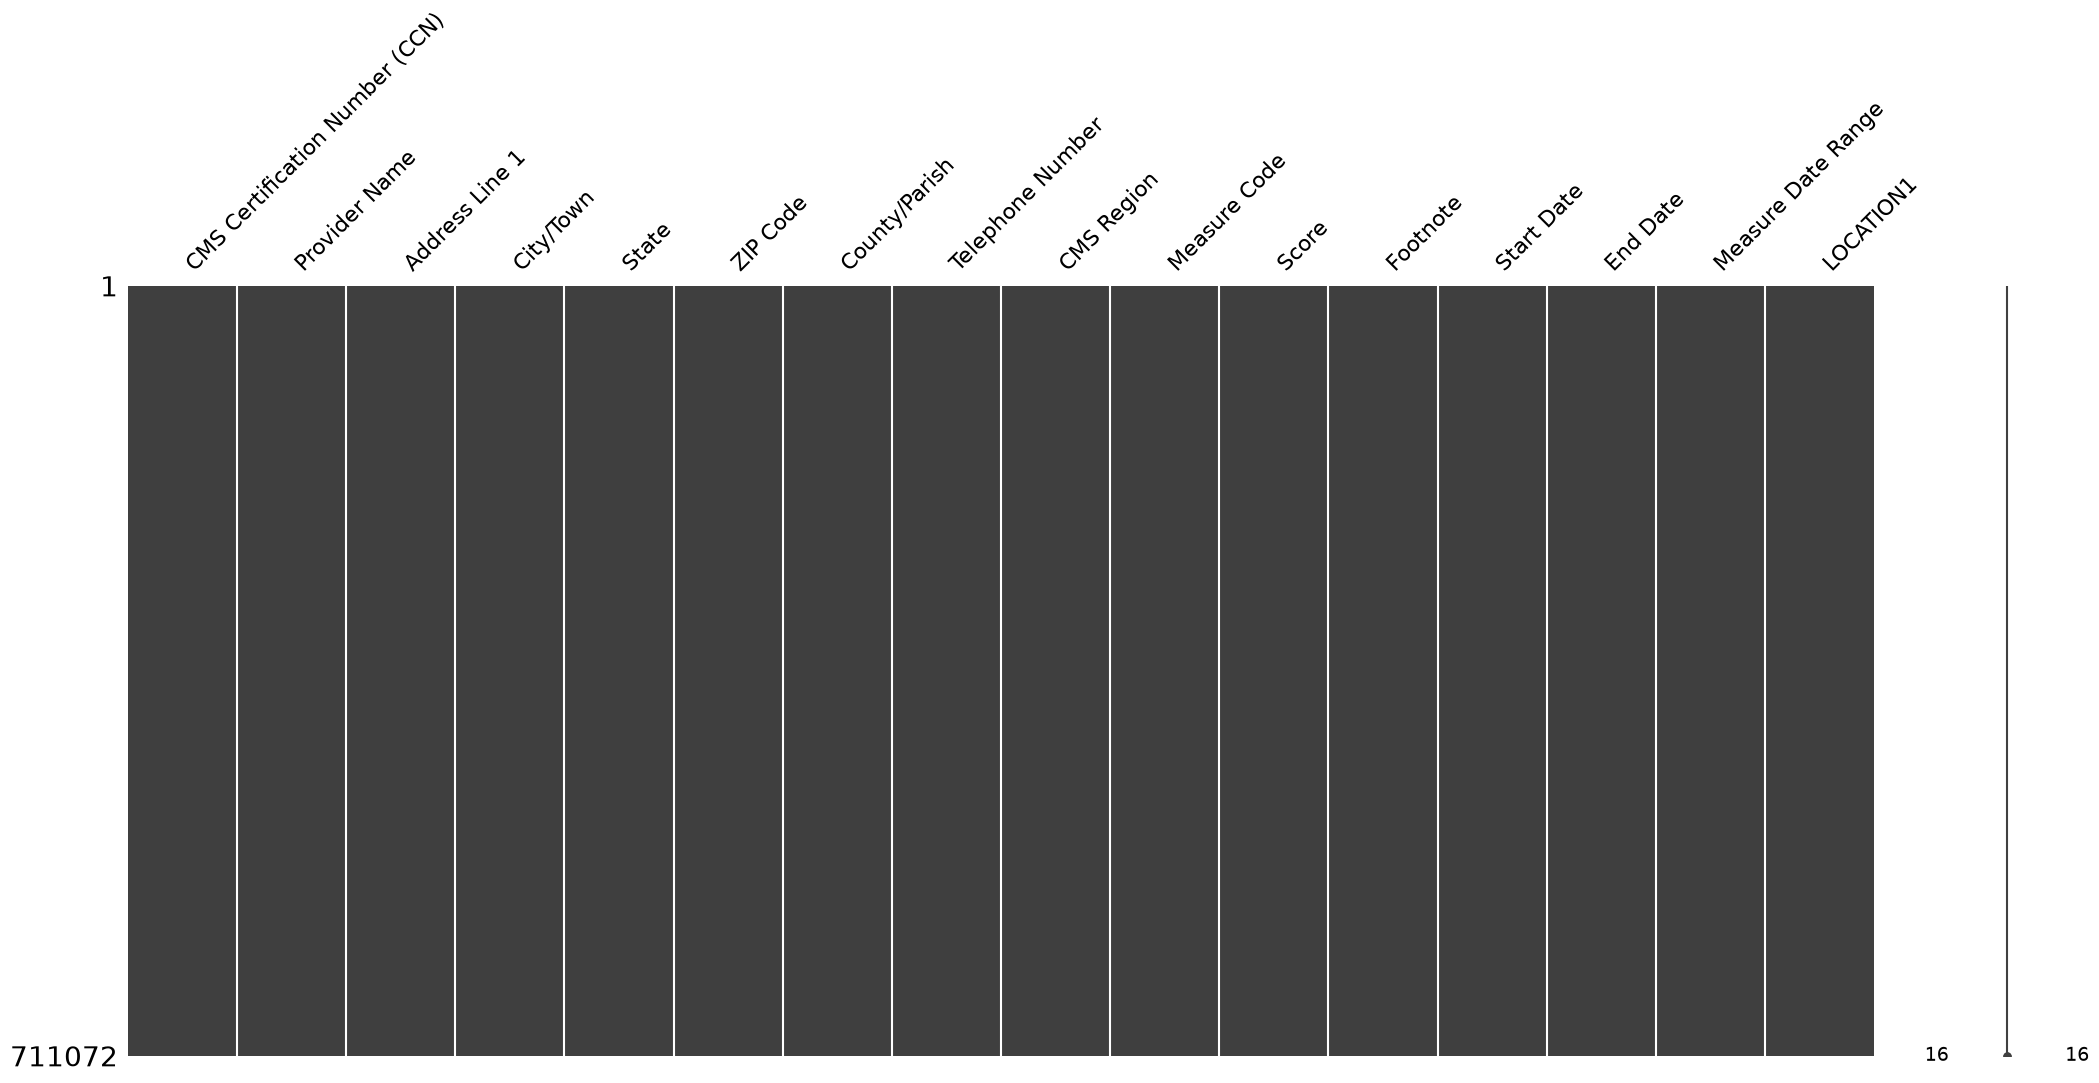

In [172]:
# Null Values
msno.matrix(Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024)

In [173]:
# Duplicates
Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024_duplicates = Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024[Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024.duplicated()]
print(Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Address Line 1, City/Town, State, ZIP Code, County/Parish, Telephone Number, CMS Region, Measure Code, Score, Footnote, Start Date, End Date, Measure Date Range, LOCATION1]
Index: []


In [174]:
# Patient Throughput
# Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024['Measure Code'].value_counts()
throughput = Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024[
    Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024['Measure Code'] == 'S_005_02_DTC_OBS_RATE'] 
    # observed discharges to community rate

print(throughput.loc[:,["CMS Certification Number (CCN)","Provider Name","State","Score","Footnote"]].head(10))

    CMS Certification Number (CCN)  \
9                           015009   
57                          015010   
105                         015012   
153                         015014   
201                         015015   
249                         015016   
297                         015019   
345                         015023   
393                         015024   
441                         015027   

                                        Provider Name State          Score  \
9                            BURNS NURSING HOME, INC.    AL          32.47   
57                     COOSA VALLEY HEALTHCARE CENTER    AL          55.36   
105                        HIGHLANDS HEALTH AND REHAB    AL          53.73   
153       EASTVIEW REHABILITATION & HEALTHCARE CENTER    AL  Not Available   
201                     PLANTATION MANOR NURSING HOME    AL  Not Available   
249              ATHENS HEALTH AND REHABILITATION LLC    AL          64.73   
297                                

### Skilled Nursing Facility Quality Reporting Program (SNF QRP) - Swing Beds - Provider Data
- Non-Critical Access Hospitals (CAHs) with swing beds are hospitals that provide Medicare Part A SNF services to beneficiaries and must report data on certain measures of quality to Medicare through the Skilled Nursing Facility Quality Reporting Program (SNF QRP).
- Contains swing bed units participating in the SNF QRP and their results on quality measures implemented under the IMPACT Act.

In [175]:
Swing_Bed_SNF_data_Oct2024.head()

,CMS Certification Number (CCN),Provider Name,Address Line 1,Address Line 2,City/Town,State,ZIP Code,County/Parish,Telephone Number,CMS Region,Measure Code,Score,Footnote,Start Date,End Date,MeasureDateRange
0,10007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,-,OPP,AL,36467,COVINGTON,(334) 493-3541,4,S_004_01_PPR_PD_COMP_PERF,No Different than the National Rate,-,10/01/2021,09/30/2023,-
1,10007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,-,OPP,AL,36467,COVINGTON,(334) 493-3541,4,S_004_01_PPR_PD_OBS,16.67,-,10/01/2021,09/30/2023,-
2,10007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,-,OPP,AL,36467,COVINGTON,(334) 493-3541,4,S_004_01_PPR_PD_OBS_READM,17,-,10/01/2021,09/30/2023,-
3,10007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,-,OPP,AL,36467,COVINGTON,(334) 493-3541,4,S_004_01_PPR_PD_RSRR,13.94,-,10/01/2021,09/30/2023,-
4,10007,MIZELL MEMORIAL HOSPITAL,702 N MAIN ST,-,OPP,AL,36467,COVINGTON,(334) 493-3541,4,S_004_01_PPR_PD_RSRR_2_5,9.89,-,10/01/2021,09/30/2023,-


In [176]:
Swing_Bed_SNF_data_Oct2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 38064 entries, 0 to 38063
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   CMS Certification Number (CCN)  38064 non-null  int64
 1   Provider Name                   38064 non-null  str  
 2   Address Line 1                  38064 non-null  str  
 3   Address Line 2                  38064 non-null  str  
 4   City/Town                       38064 non-null  str  
 5   State                           38064 non-null  str  
 6   ZIP Code                        38064 non-null  int64
 7   County/Parish                   38064 non-null  str  
 8   Telephone Number                38064 non-null  str  
 9   CMS Region                      38064 non-null  int64
 10  Measure Code                    38064 non-null  str  
 11  Score                           38064 non-null  str  
 12  Footnote                        38064 non-null  str  
 13  Start Date  

<Axes: >

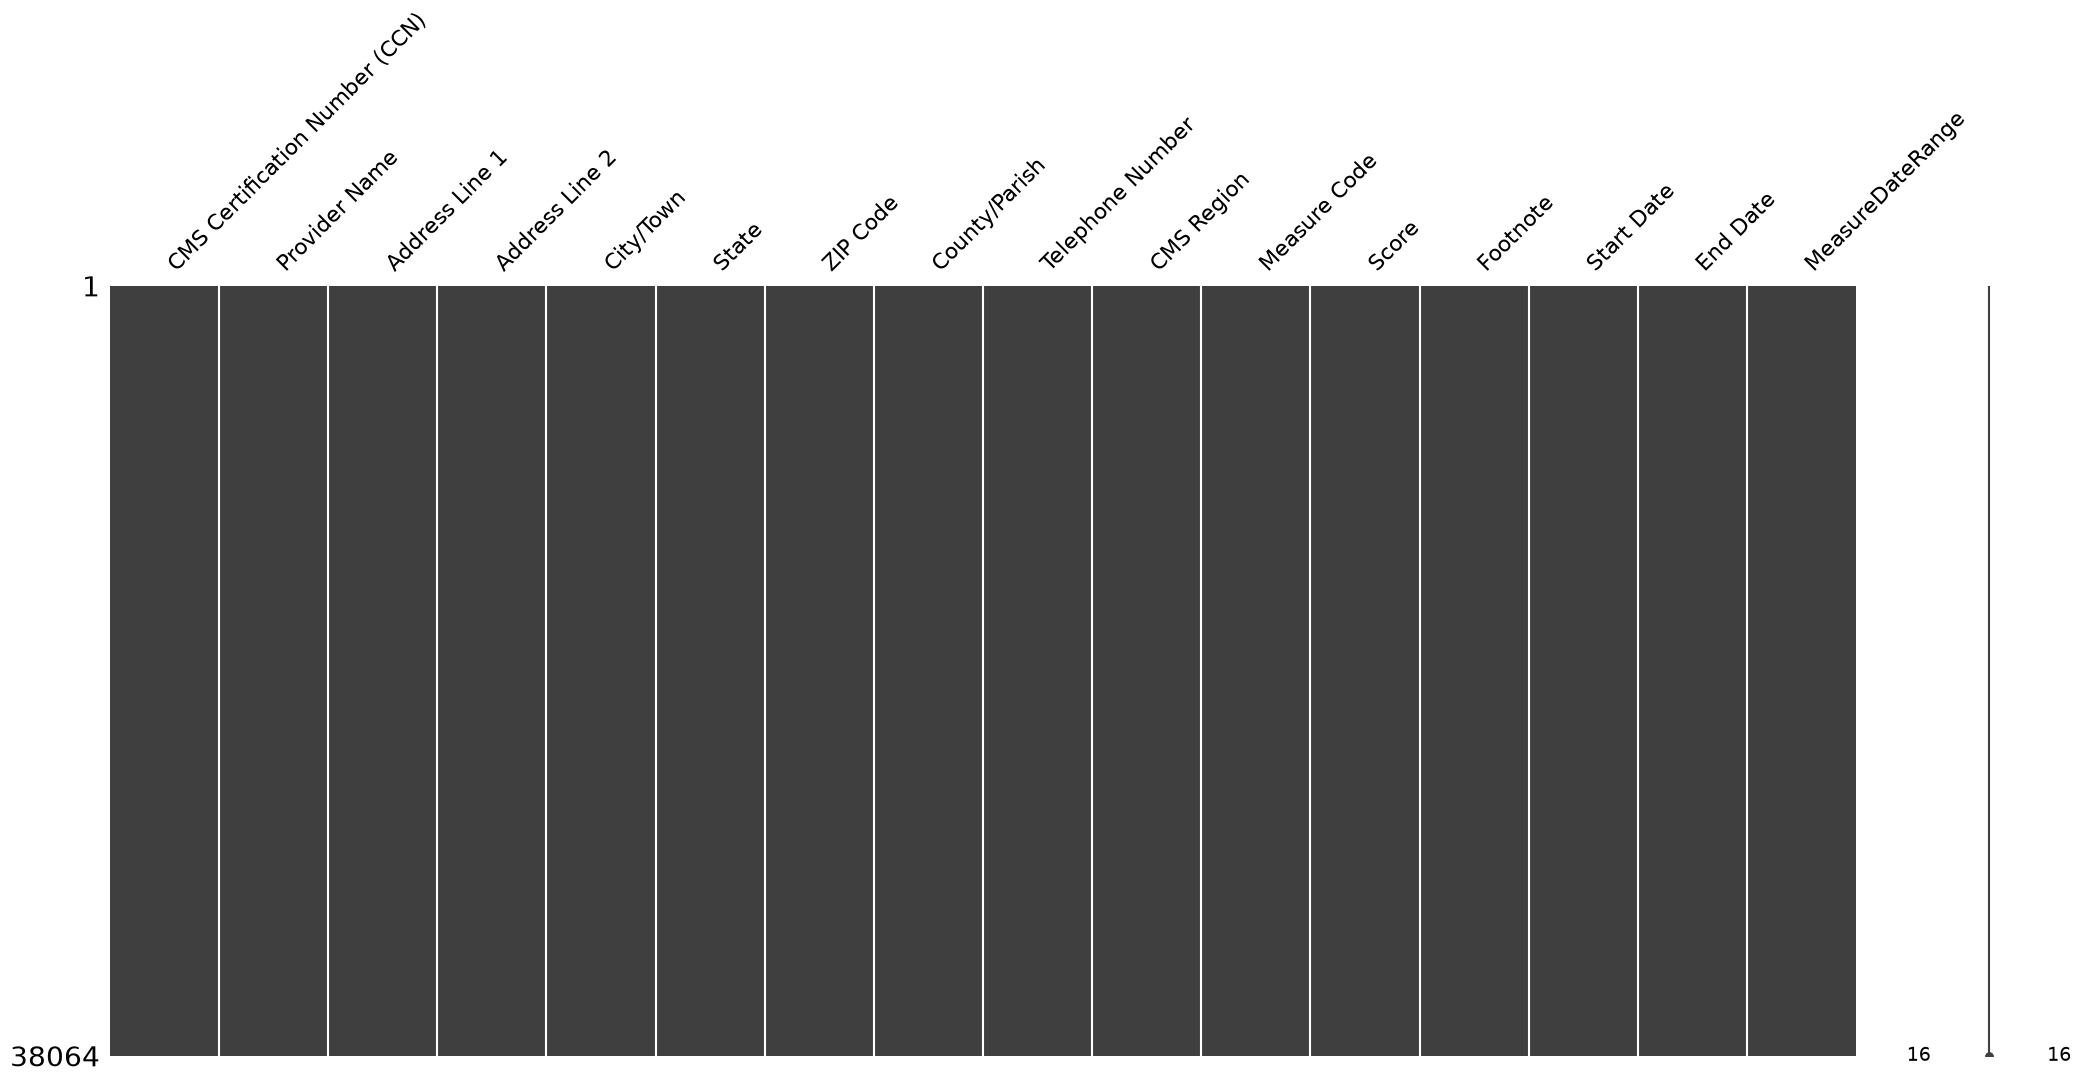

In [177]:
# Null Values
msno.matrix(Swing_Bed_SNF_data_Oct2024)

In [178]:
# Duplicates
Swing_Bed_SNF_data_Oct2024_duplicates = Swing_Bed_SNF_data_Oct2024[Swing_Bed_SNF_data_Oct2024.duplicated()]
print(Swing_Bed_SNF_data_Oct2024_duplicates)

Empty DataFrame
Columns: [CMS Certification Number (CCN), Provider Name, Address Line 1, Address Line 2, City/Town, State, ZIP Code, County/Parish, Telephone Number, CMS Region, Measure Code, Score, Footnote, Start Date, End Date, MeasureDateRange]
Index: []
